# 02 — Analisis Visual: Keadaan Mata dan Sleepiness

> **Dua benchmark dan satu audit terpisah:** MRL / eye state dan DROZY / KSS sleepiness  
> **Unit evaluasi:** gambar pada subjek holdout; original test pada subjek LOSO  
> **Mode default:** DEMO — cache terverifikasi, penghitungan window EAR dan inference checkpoint

[README proyek](../../README.md) · [MRL](https://mrl.cs.vsb.cz/eyedataset.html) · [DROZY](https://www.drozy.uliege.be/) · [Metodologi dan batasan](../../reports/limitations.md) · [Run All](README.md)

## Ringkasan untuk Pembaca

Gambar mata menjawab apakah mata terbuka atau tertutup; urutan landmark menjawab bagaimana pola mata berubah sepanjang waktu. Notebook ini menjalankan dua penelitian kecil untuk menguji kedua kemampuan tersebut pada orang yang tidak masuk training. Eye state dan KSS sleepiness tidak disatukan menjadi satu label fatigue.

Fatigue berarti kelelahan terkait tuntutan berkelanjutan; sleepiness adalah kecenderungan tertidur. Workload (tuntutan mental), stress (respons tekanan), emotion (emosi), dan eye state (keadaan mata) juga berbeda. Tidak ada skor deteksi fatigue ATC pada notebook ini.

Tambahan: audit deskriptif CogBeacon; tidak ada classifier fatigue tanpa label window yang tervalidasi.

**Ekstensi temporal:** [RQ1 — DROZY CNN](#26-rq1--apakah-urutan-mata-membantu-memperkirakan-kss) · RQ2 UTA-RLDD · RQ3 FatigueView · RQ4 audit fatigue-specific. Semua target tetap dipisahkan; hasil dataset yang belum tersedia tidak diganti skor sintetis.

In [1]:
from pathlib import Path
import os
RUN_MODE = os.environ.get('ATC_NOTEBOOK_MODE', 'DEMO').upper()
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'configs/notebook_v3.yaml').exists())
os.chdir(ROOT)
import yaml
config = yaml.safe_load(Path('configs/notebook_v3.yaml').read_text())
for key in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'NUMBA_NUM_THREADS'):
    os.environ[key] = str(config['threads'])
os.environ['OPENCV_FFMPEG_THREADS'] = str(config['opencv_threads'])
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from threadpoolctl import threadpool_limits
from atc_fatigue.research.runs import Run, cached_run, project_config, mode_from_environment, metrics_base, save_model
from atc_fatigue.research.data import local_manifest, frozen_split, prediction_table, public_errors, verify_cached_predictions
from atc_fatigue.research.plots import (COLORS, EMOTIONS, FigureBook, theme, run_card, flow,
                                      histogram, model_bars, confusion_pair, split_chart, recall_chart)
config = project_config()
RUN_MODE = mode_from_environment(config['mode_default'])
thread_limit = threadpool_limits(limits=config['threads'])
theme()
warning_context = warnings.catch_warnings(record=True)
warning_records = warning_context.__enter__()
print(f'Mode {RUN_MODE} | CPU maksimal {config["threads"]} thread | offline | kernel proyek')
from atc_fatigue.research.data import private_media_enabled
from atc_fatigue.research.representations import inspect_model_input, audio_feature_group
PRIVATE_MEDIA = private_media_enabled()
USE_SOURCE_MEDIA = RUN_MODE == 'FULL' or PRIVATE_MEDIA
print('Media sumber:', 'FRESH lokal' if USE_SOURCE_MEDIA else 'tidak dibaca; DEMO memakai cache terverifikasi')

if os.environ.get('ATC_NOTEBOOK_DENY_RAW_MEDIA') == '1':
    from atc_fatigue.research.data import deny_raw_media_reads
    deny_raw_media_reads()
    print('ACCEPTANCE: pembacaan data/raw diblokir pada proses kernel ini.')


Mode DEMO | CPU maksimal 4 thread | offline | kernel proyek
Media sumber: tidak dibaca; DEMO memakai cache terverifikasi
ACCEPTANCE: pembacaan data/raw diblokir pada proses kernel ini.


[proyek]/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. BAGIAN A — MRL: Mata Terbuka atau Tertutup

**Pertanyaan:** dapatkah model mengenali keadaan mata pada orang yang belum pernah dilihat saat training?

MRL menyediakan gambar mata IR dan label filename: **0 = tertutup**, **1 = terbuka**. Gambar tidak memiliki urutan waktu untuk menghitung kedipan. Subset yang dipakai dibatasi per subjek/kelas; proporsinya bukan prevalensi penutupan mata dalam operasi nyata.

Sumber MRL menyatakan penggunaan publik, tetapi izin redistribusi foto belum terverifikasi. Kita memproses gambar asli secara lokal dan menggunakan ilustrasi sintetis untuk demonstrasi gambar/HOG. Tidak ada foto mata peserta yang di-embed ke notebook.

In [2]:
mrl_manifest = local_manifest(config['visual']['mrl_manifest'], target='eye_state', verify_media=USE_SOURCE_MEDIA)
mrl_rights = {'source': 'https://mrl.cs.vsb.cz/eyedataset.html', 'variant': 'official 2018_01; existing bounded subset',
              'rights': 'local research; redistribution permission not established', 'public_preview': 'synthetic eye patch only'}
mrl_limits = ['eye state is not fatigue; bounded per-subject/class subset',
              'fixed original subject split; no hyperparameter tuning', 'near-duplicates not exhaustively audited']
if RUN_MODE == 'FULL':
    mrl_run = Run.create('mrl_eye_state', '02_visual_analysis.ipynb', config, mrl_manifest,
                         'mrl-hog-32x64-v1', mrl_rights, mrl_limits)
else:
    mrl_run, mrl_metrics = cached_run('mrl_eye_state', config)
mrl_book = FigureBook(mrl_run, RUN_MODE, config)
run_card(mrl_run, RUN_MODE, 'FULL: dihitung pada bagian evaluasi' if RUN_MODE == 'FULL' else
         f"Eye state Macro F1 {mrl_metrics['models']['hog_linear_svm']['test']['macro_f1']:.4f}")
display(pd.DataFrame([{'Gambar': len(mrl_manifest), 'Subjek': mrl_manifest.subject_id.nunique(),
                       'Label': '0 tertutup / 1 terbuka', 'Duplikasi byte': mrl_manifest.source_checksum.duplicated().sum()}]))

| Identitas run | Nilai |
| :--- | :--- |
| Mode | **DEMO / CACHED — hasil FULL terverifikasi; inference checkpoint dihitung ulang, tanpa training baru** |
| Run ID sumber | `20261024T164355883823Z_seed42_91ed89` |
| Status eksperimen sumber | completed |
| Dataset / target | mrl_eye / eye_state |
| Sampel / subjek | 5285 / 37 |
| Unit evaluasi | image; held-out subject |
| Hasil utama | Eye state Macro F1 0.7877 |

,Gambar,Subjek,Label,Duplikasi byte
0,5285,37,0 tertutup / 1 terbuka,0


### 1.1 Dari gambar ke HOG

**Grayscale** merangkum intensitas terang-gelap. Gambar diubah ke ukuran **32 × 64 piksel**. **HOG** (*Histogram of Oriented Gradients*) menghitung pola arah tepi, sehingga model menerima angka tentang bentuk, bukan nama orang. Bentuk tabel dan preprocessing contoh asli ditunjukkan sebelum training.

In [3]:
from atc_fatigue.io.mrl import image_features
from skimage.io import imread
from skimage.transform import resize
from skimage.feature import hog
if USE_SOURCE_MEDIA:
    live_mrl_hog = image_features(mrl_manifest.iloc[:1],config['visual']['mrl_image_size'])
    real_eye = imread(mrl_manifest.original_path.iloc[0],as_gray=True)
    resized_eye = resize(real_eye,tuple(config['visual']['mrl_image_size']),anti_aliasing=True)
    preview_metadata = {'raw_shape':list(real_eye.shape),'resize_shape':list(resized_eye.shape),
                        'hog_shape':list(live_mrl_hog.filter(regex='^hog_').shape)}
    if RUN_MODE == 'FULL':mrl_run.write('features/example_image_shapes.json',preview_metadata)
else:
    cached_mrl = pd.read_parquet(mrl_run.path/'features/features.parquet')
    live_mrl_hog = cached_mrl[cached_mrl.sample_id.eq(mrl_manifest.sample_id.iloc[0])].reset_index(drop=True)
    preview_metadata = json.loads((mrl_run.path/'features/example_image_shapes.json').read_text())
display(pd.DataFrame([preview_metadata]).T.rename(columns={0:'REAL source / '+('FRESH' if USE_SOURCE_MEDIA else 'CACHED')}))
display(live_mrl_hog.filter(regex='^hog_').iloc[:1,:6].reset_index(drop=True))

,REAL source / CACHED
raw_shape,"[102, 102]"
resize_shape,"[32, 64]"
hog_shape,"[1, 756]"


,hog_0000,hog_0001,hog_0002,hog_0003,hog_0004,hog_0005
0,0.050011,0.035776,0.288072,0.201027,0.259804,0.077059


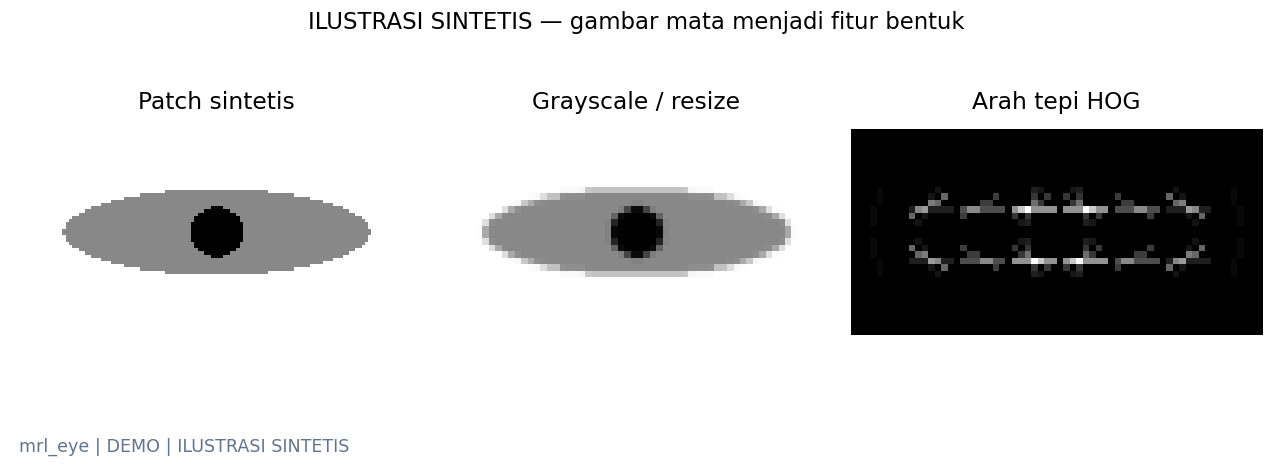

**Yang terlihat:** Bentuk mata buatan berubah menjadi peta arah tepi.

**Artinya:** HOG merangkum bentuk lokal menjadi vektor numerik berukuran tetap.

**Perlu diingat:** Ilustrasi tidak dipakai untuk training; 756 fitur contoh di tabel berasal dari gambar asli.

*Sumber: `20261024T164355883823Z_seed42_91ed89` · REAL / CACHED; inference dihitung ulang.*

In [4]:
yy, xx = np.mgrid[-1:1:64j, -2:2:128j]
synthetic_eye = np.full(xx.shape, 0.85)
synthetic_eye[(xx/1.5)**2 + (yy/0.42)**2 < 1] = 0.5
synthetic_eye[xx**2 + yy**2 < 0.25**2] = 0.1
synthetic_resized = resize(synthetic_eye, (32, 64), anti_aliasing=True)
_, synthetic_hog_image = hog(synthetic_resized, orientations=9, pixels_per_cell=(8, 8),
                             cells_per_block=(2, 2), visualize=True)
fig, axes = plt.subplots(1, 3, figsize=(12, 4), layout='constrained')
for ax, image, label in zip(axes, [synthetic_eye, synthetic_resized, synthetic_hog_image],
                            ['Patch sintetis', 'Grayscale / resize', 'Arah tepi HOG']):
    ax.imshow(image, cmap='gray'); ax.set_title(label); ax.set_axis_off()
fig.suptitle('ILUSTRASI SINTETIS — gambar mata menjadi fitur bentuk')
mrl_book.show(fig, 'gambar_ke_hog_sintetis', 'Bentuk mata buatan berubah menjadi peta arah tepi.',
              'HOG merangkum bentuk lokal menjadi vektor numerik berukuran tetap.',
              'Ilustrasi tidak dipakai untuk training; 756 fitur contoh di tabel berasal dari gambar asli.', synthetic=True)

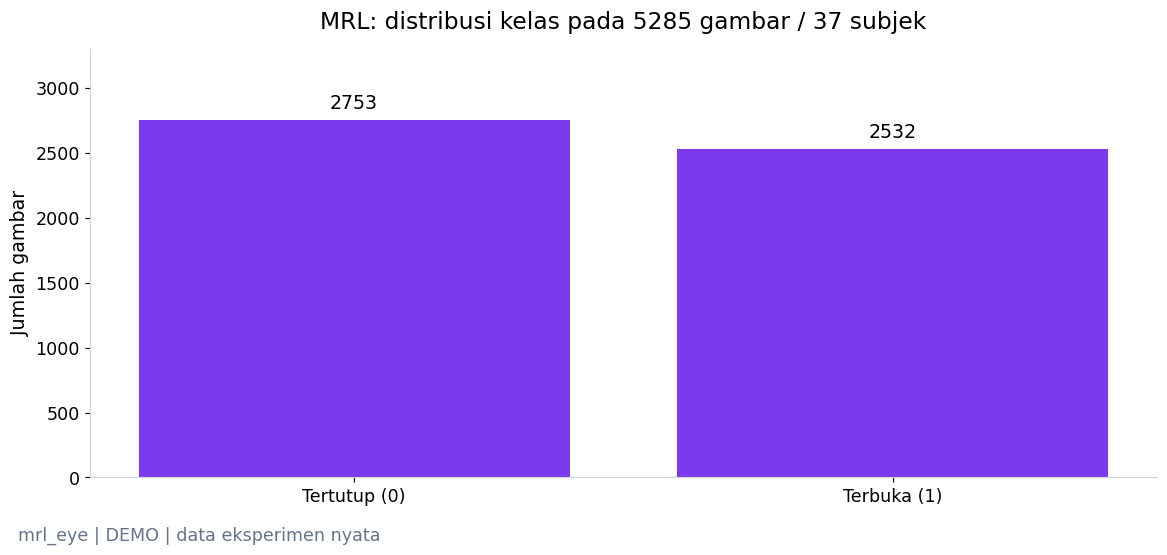

**Yang terlihat:** Tertutup 2753 gambar; terbuka 2532 gambar.

**Artinya:** Kedua kelas tersedia untuk membandingkan model dengan tebakan kelas mayoritas.

**Perlu diingat:** Sampling dibatasi per subjek/kelas; ini bukan frekuensi keadaan mata di tempat kerja.

*Sumber: `20261024T164355883823Z_seed42_91ed89` · REAL / CACHED; inference dihitung ulang.*

In [5]:
counts = mrl_manifest.target_value.value_counts().sort_index()
fig, ax = plt.subplots(layout='constrained')
bars = ax.bar(['Tertutup (0)', 'Terbuka (1)'], counts.values, color=COLORS['visual'])
ax.bar_label(bars, padding=5)
ax.set(ylabel='Jumlah gambar', ylim=(0, counts.max()*1.2),
       title=f'MRL: distribusi kelas pada {len(mrl_manifest)} gambar / {mrl_manifest.subject_id.nunique()} subjek')
mrl_book.show(fig, 'distribusi_kelas_mrl', f'Tertutup {counts.loc[0]} gambar; terbuka {counts.loc[1]} gambar.',
              'Kedua kelas tersedia untuk membandingkan model dengan tebakan kelas mayoritas.',
              'Sampling dibatasi per subjek/kelas; ini bukan frekuensi keadaan mata di tempat kerja.')

### 1.2 Ekstraksi subset dan split yang dibekukan

**Subject-disjoint split** berarti satu orang hanya masuk satu bagian data. Test menjawab generalisasi ke orang baru pada subset ini. Keanggotaan train/validation/test memakai manifest eksperimen lama yang sudah dibekukan; kita tidak memilih split setelah melihat skor.

Checksum byte dan decoded pixels diperiksa sebelum model dilatih. Kesamaan piksel yang melintasi split ditolak. Ini belum merupakan audit seluruh near-duplicate yang mungkin terjadi pada gambar serupa.

In [6]:
if RUN_MODE == 'FULL':
    mrl_hog = image_features(mrl_manifest, config['visual']['mrl_image_size'])
    mrl_data = mrl_manifest.merge(mrl_hog, on='sample_id', validate='one_to_one')
    decoded_duplicates = int(mrl_data.pixel_checksum.duplicated().sum())
    mrl_data = mrl_data.drop_duplicates('pixel_checksum').reset_index(drop=True)
    mrl_data = frozen_split(mrl_data, config['frozen_splits']['mrl_eye_state'])
else:
    mrl_data = pd.read_parquet(mrl_run.path / 'features/features.parquet')
    decoded_duplicates = json.loads((mrl_run.path / 'data_qc.json').read_text())['decoded_duplicates_removed']
    assert set(mrl_data.sample_id) == set(mrl_manifest.sample_id)
mrl_columns = [c for c in mrl_data if c.startswith('hog_')]
assert len(mrl_columns) == 756 and mrl_data.groupby('subject_id').split.nunique().max() == 1
np.testing.assert_allclose(mrl_data.loc[mrl_data.sample_id.eq(mrl_manifest.sample_id.iloc[0]), mrl_columns].iloc[0],
                           live_mrl_hog[mrl_columns].iloc[0])
mrl_sizes = mrl_data.groupby('split').size().to_dict()
display(mrl_data.groupby('split').agg(Gambar=('sample_id','size'), Subjek=('subject_id','nunique')))
display(pd.DataFrame([{'Duplikasi decoded dihapus': decoded_duplicates, 'Overlap subjek antarbagian': 0}]))
if RUN_MODE == 'FULL':
    mrl_run.features(mrl_data, mrl_columns, 'mrl-hog-32x64-v1')
    mrl_data[['sample_id','subject_id','target_value','source_checksum','pixel_checksum','split']].to_csv(mrl_run.file('split_manifest.csv'), index=False)

,Gambar,Subjek
split,,
test,1159,8
train,3234,23
validation,892,6


,Duplikasi decoded dihapus,Overlap subjek antarbagian
0,0,0


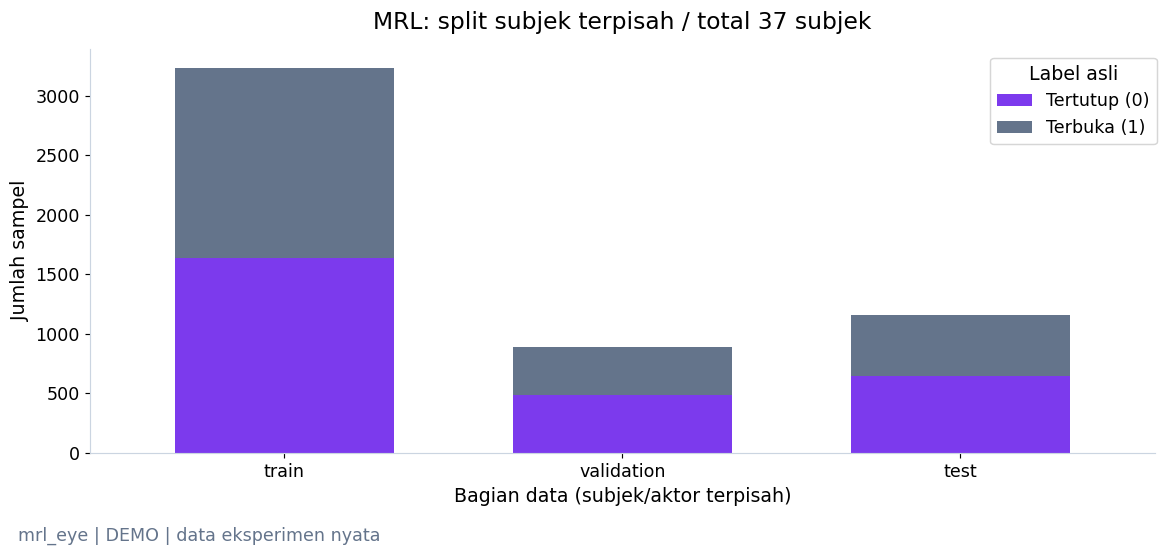

**Yang terlihat:** Train 3234, validation 892, test 1159 gambar; overlap subjek nol.

**Artinya:** Skor test menilai subjek yang tidak digunakan untuk fit preprocessing atau classifier.

**Perlu diingat:** Gambar dalam orang yang sama tetap berkorelasi; ini bukan ribuan peserta independen.

*Sumber: `20261024T164355883823Z_seed42_91ed89` · REAL / CACHED; inference dihitung ulang.*

In [7]:
fig = split_chart(mrl_data, f'MRL: split subjek terpisah / total {mrl_data.subject_id.nunique()} subjek')
mrl_book.show(fig, 'split_mrl',
              f"Train {mrl_sizes['train']}, validation {mrl_sizes['validation']}, test {mrl_sizes['test']} gambar; overlap subjek nol.",
              'Skor test menilai subjek yang tidak digunakan untuk fit preprocessing atau classifier.',
              'Gambar dalam orang yang sama tetap berkorelasi; ini bukan ribuan peserta independen.')

### 1.3 Training baseline yang benar-benar dipanggil

**Dummy mayoritas** selalu menebak kelas paling banyak pada training. **Linear SVM** mencari batas linear pada fitur HOG. **Imputer** mengisi fitur hilang dengan median training; **scaler** menyetarakan skala berdasarkan training saja. Pipeline memastikan preprocessing tidak mempelajari test.

Konfigurasi tetap: SVM `C=1`, class weight balanced, seed 42. Tidak ada pencarian hyperparameter. Pada FULL, `fit` di bawah menjalankan training; pada DEMO, checkpoint asli dimuat dan prediksi test diverifikasi terhadap hasil tersimpan.

Pada evaluasi, **precision** adalah proporsi prediksi suatu kelas yang benar; **recall** adalah proporsi anggota kelas asli yang berhasil dikenali. **Support** menyebut jumlah sampel kelas tersebut, bukan jumlah subjek.

In [8]:
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import LinearSVC
from sklearn.linear_model import Ridge
from atc_fatigue.models.baselines import classification_metrics
mrl_training, mrl_holdout = mrl_data[mrl_data.split.eq('train')], mrl_data[~mrl_data.split.eq('train')]
if RUN_MODE == 'FULL':
    mrl_models = {
        'dummy_majority': DummyClassifier(strategy='most_frequent'),
        'hog_linear_svm': make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
            LinearSVC(C=config['visual']['svm_c'], class_weight='balanced', dual='auto', random_state=config['seed'], max_iter=20000)),
    }
    mrl_scores, mrl_prediction_parts = {}, []
    for model_name, model in mrl_models.items():
        model.fit(mrl_training[mrl_columns], mrl_training.target_value)
        save_model(mrl_run, model_name, model, mrl_columns, mrl_holdout)
        mrl_scores[model_name] = {'reload_verified': True}
        for partition in ['validation','test']:
            part = mrl_data[mrl_data.split.eq(partition)]
            predicted = model.predict(part[mrl_columns])
            mrl_scores[model_name][partition] = classification_metrics(part.target_value, predicted, [0,1])
            mrl_prediction_parts.append(prediction_table(part, predicted, model_name))
    mrl_predictions = pd.concat(mrl_prediction_parts, ignore_index=True)
    mrl_predictions.to_csv(mrl_run.file('predictions/holdout_predictions.csv'), index=False)
    mrl_metrics = metrics_base(mrl_run, mrl_scores, mrl_sizes, {'0':'closed','1':'open'}, 'dummy_majority')
else:
    mrl_predictions = pd.read_csv(mrl_run.path / 'predictions/holdout_predictions.csv', dtype={'subject_id':str})
    for model_name in mrl_metrics['models']:
        verify_cached_predictions(mrl_run, mrl_data[mrl_data.split.eq('test')], mrl_predictions, model_name)

,macro_f1,balanced_accuracy,accuracy
dummy_majority,0.355753,0.5,0.5522
hog_linear_svm,0.787665,0.787206,0.790336


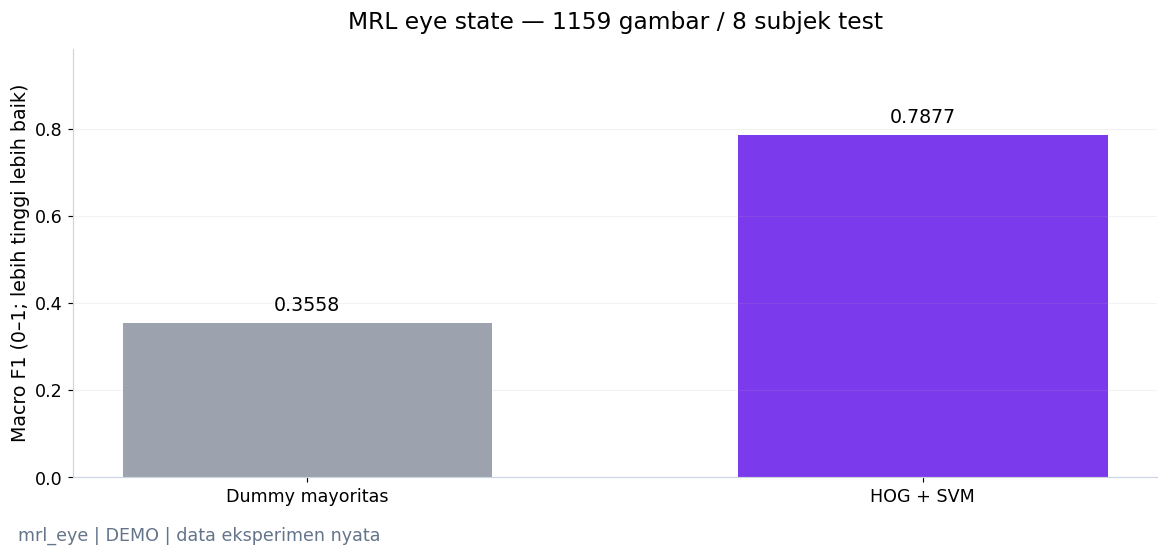

**Yang terlihat:** Macro F1 SVM 0.7877; Dummy 0.3558.

**Artinya:** Macro F1 merata-ratakan F1 tiap kelas, sehingga kedua keadaan mata ikut dinilai.

**Perlu diingat:** Peningkatan di subset ini tidak berarti model mampu mendeteksi fatigue.

*Sumber: `20261024T164355883823Z_seed42_91ed89` · REAL / CACHED; inference dihitung ulang.*

In [9]:
mrl_test_scores = {name: value['test'] for name, value in mrl_metrics['models'].items()}
display(pd.DataFrame(mrl_test_scores).T[['macro_f1','balanced_accuracy','accuracy']])
fig = model_bars(mrl_test_scores, 'macro_f1', f'MRL eye state — {mrl_sizes["test"]} gambar / 8 subjek test',
                 'Macro F1 (0–1; lebih tinggi lebih baik)', COLORS['visual'])
mrl_book.show(fig, 'perbandingan_model_mrl',
              f"Macro F1 SVM {mrl_test_scores['hog_linear_svm']['macro_f1']:.4f}; Dummy {mrl_test_scores['dummy_majority']['macro_f1']:.4f}.",
              'Macro F1 merata-ratakan F1 tiap kelas, sehingga kedua keadaan mata ikut dinilai.',
              'Peningkatan di subset ini tidak berarti model mampu mendeteksi fatigue.')

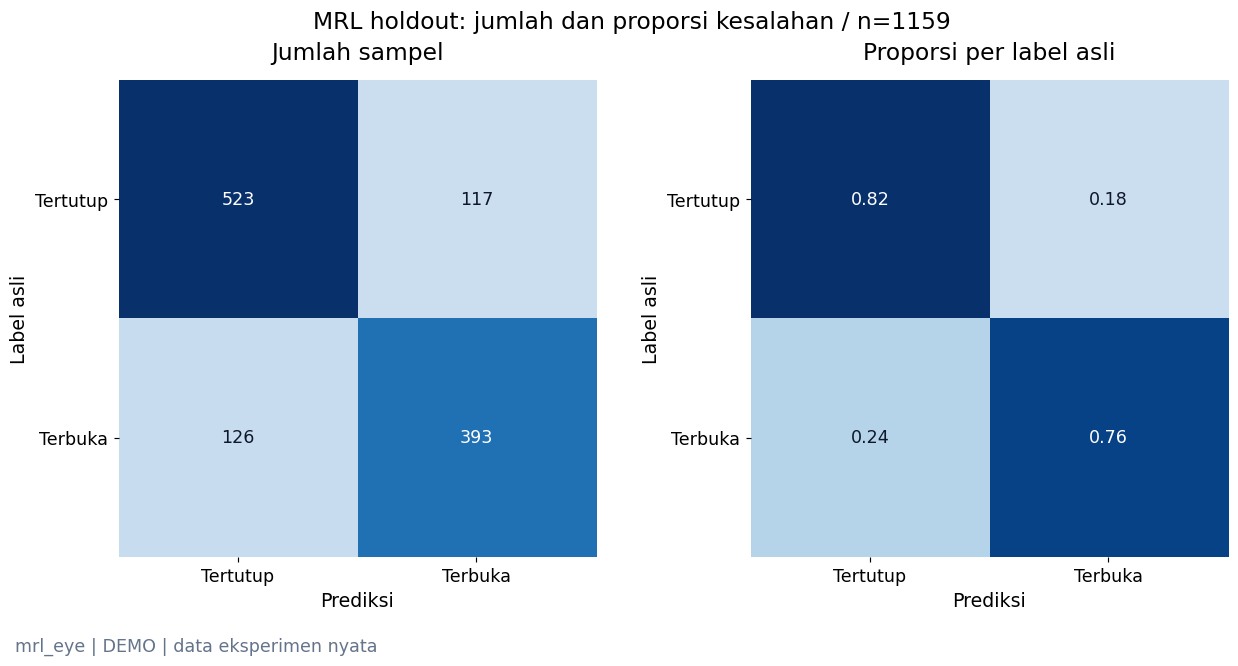

**Yang terlihat:** Dari matriks test, 916 gambar diprediksi benar; sisanya tertukar kelas.

**Artinya:** Baris menyatakan label asli, kolom prediksi; sel di luar diagonal adalah kesalahan.

**Perlu diingat:** Normalisasi dilakukan per baris agar proporsi kesalahan tiap kelas mudah dibandingkan.

*Sumber: `20261024T164355883823Z_seed42_91ed89` · REAL / CACHED; inference dihitung ulang.*

In [10]:
mrl_result = mrl_test_scores['hog_linear_svm']
fig = confusion_pair(mrl_result, ['Tertutup','Terbuka'], f'MRL holdout: jumlah dan proporsi kesalahan / n={mrl_sizes["test"]}')
mrl_book.show(fig, 'confusion_mrl',
              f"Dari matriks test, {np.trace(mrl_result['confusion_matrix'])} gambar diprediksi benar; sisanya tertukar kelas.",
              'Baris menyatakan label asli, kolom prediksi; sel di luar diagonal adalah kesalahan.',
              'Normalisasi dilakukan per baris agar proporsi kesalahan tiap kelas mudah dibandingkan.')

,Precision,Recall,F1,Jumlah gambar test
Tertutup,0.805855,0.817187,0.811482,640.0
Terbuka,0.770588,0.757225,0.763848,519.0


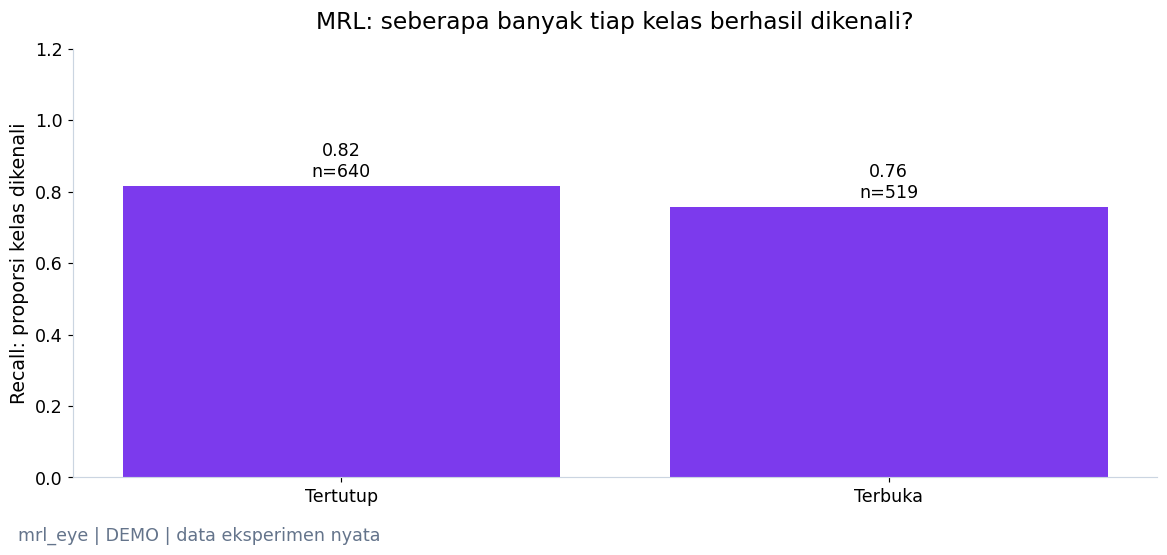

**Yang terlihat:** Recall tertutup 0.817; terbuka 0.757.

**Artinya:** Recall adalah bagian sampel kelas asli yang dikenali dengan benar.

**Perlu diingat:** Kesalahan open/closed belum dapat diterjemahkan menjadi false alarm fatigue.

*Sumber: `20261024T164355883823Z_seed42_91ed89` · REAL / CACHED; inference dihitung ulang.*

,Contoh,Label asli,Prediksi
2950,contoh-3b1a6522,0,1
2952,contoh-f789fe7f,0,1
2953,contoh-14817f62,0,1
2955,contoh-9cc089c8,0,1
2956,contoh-861c0936,0,1
2971,contoh-5bd728e0,0,1


In [11]:
mrl_class_report = pd.DataFrame({label:mrl_result['classification_report'][str(code)]
                                     for code,label in [(0,'Tertutup'),(1,'Terbuka')]}).T
mrl_class_report = mrl_class_report.rename(columns={'precision':'Precision','recall':'Recall','f1-score':'F1','support':'Jumlah gambar test'})
display(mrl_class_report)
fig = recall_chart(mrl_result, ['Tertutup','Terbuka'], 'MRL: seberapa banyak tiap kelas berhasil dikenali?', COLORS['visual'])
mrl_book.show(fig, 'recall_mrl',
              f"Recall tertutup {mrl_result['classification_report']['0']['recall']:.3f}; terbuka {mrl_result['classification_report']['1']['recall']:.3f}.",
              'Recall adalah bagian sampel kelas asli yang dikenali dengan benar.',
              'Kesalahan open/closed belum dapat diterjemahkan menjadi false alarm fatigue.')
display(public_errors(mrl_predictions, 'hog_linear_svm'))

### 1.4 Lihat input HOG yang dipakai model

**Apa yang masuk classifier?** Satu gambar mata diubah menjadi grayscale 32×64, lalu HOG merangkum arah tepi menjadi vektor numerik.
HOG menangkap bentuk/appearance pada gambar, bukan durasi mata tertutup. Tidak ada timestamp atau FPS terverifikasi pada MRL;
subset kita dipilih acak per peserta/kelas, sehingga tidak dipakai sebagai urutan kedipan.

Tabel menunjukkan kolom raw dan hasil scaling dari pipeline SVM tersimpan, bukan angka ilustrasi.
Heatmap menampilkan hanya 16 kolom tersebar dari dimensi lengkap; ID orang/nama file/label tidak masuk X.
Contoh benar/salah dipilih sebagai sample ID pertama untuk masing-masing status, bukan kasus yang paling mengesankan.

,Split,X.shape,y.shape
0,train,"(3234, 756)","(3234,)"
1,validation,"(892, 756)","(892,)"
2,test,"(1159, 756)","(1159,)"


,feature,raw,transformed
0,hog_0000,0.0619,-0.4984
50,hog_0050,0.1650,0.2480
100,hog_0100,0.0605,0.9549
151,hog_0151,0.0052,-0.3532
201,hog_0201,0.2347,0.7188
251,hog_0251,0.0761,-0.0507
302,hog_0302,0.2896,1.3073
352,hog_0352,0.0111,-0.4147
402,hog_0402,0.0688,0.4804
453,hog_0453,0.3309,0.5406


,hog_0000,hog_0050,hog_0100,hog_0151,hog_0201,hog_0251,hog_0302,hog_0352,hog_0402,hog_0453,hog_0503,hog_0553,hog_0604,hog_0654,hog_0704,hog_0755
0,0.0500,0.1448,0.0503,0.0072,0.0773,0.1017,0.0822,0.0,0.0173,0.3513,0.1179,0.4142,0.0404,0.0000,0.0726,0.0536
1,0.0456,0.1360,0.0291,0.0000,0.0702,0.0819,0.0857,0.0,0.0079,0.4079,0.0467,0.4108,0.0000,0.0044,0.0602,0.0881
2,0.1143,0.1436,0.0526,0.0029,0.0446,0.1066,0.3334,0.0,0.0659,0.3319,0.2728,0.3953,0.0387,0.0000,0.2706,0.1986


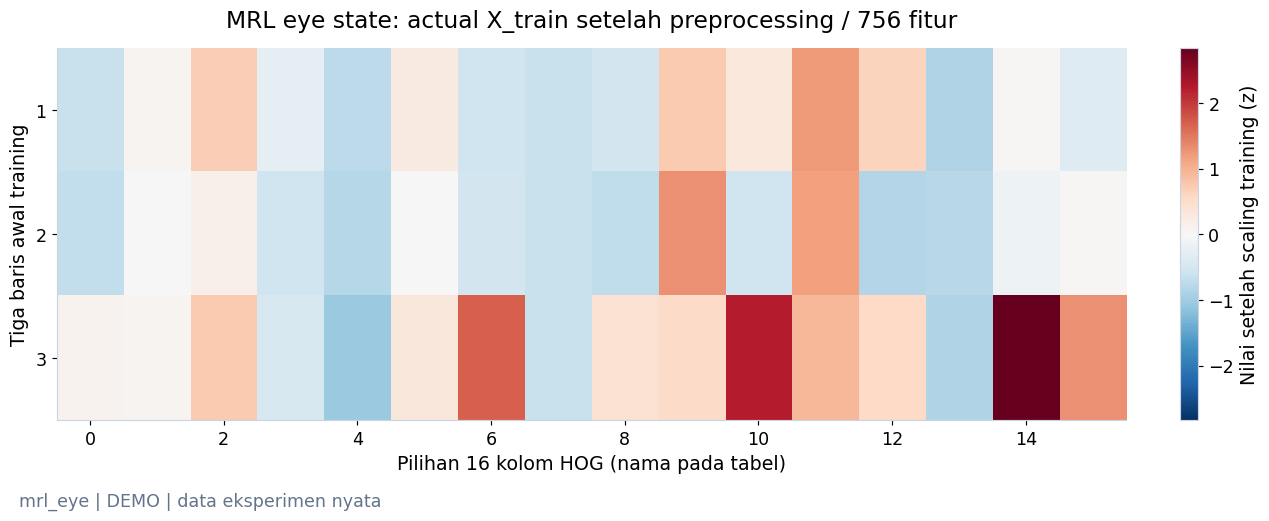

**Yang terlihat:** Heatmap berasal dari transform pipeline SVM yang sama dengan model evaluasi; tabel raw memungkinkan penelusuran nilai.

**Artinya:** SVM menerima vektor tepi, tanpa perlu melihat raw image pada notebook publik.

**Perlu diingat:** HOG bukan pengukuran fisiologis; dimensi ini tidak mengandung durasi blink atau fatigue ground truth.

*Sumber: `20261024T164355883823Z_seed42_91ed89` · REAL / CACHED; inference dihitung ulang.*

,Contoh,Ground truth eye state,Prediksi,Benar
2943,contoh-66b1540f,0,0,True
2950,contoh-3b1a6522,0,1,False


In [12]:
import joblib
mrl_pipeline = joblib.load(mrl_run.path/'models/hog_linear_svm.joblib')['model']
mrl_test = mrl_data[mrl_data.split.eq('test')]
mrl_input_view = inspect_model_input(mrl_pipeline,mrl_training,mrl_test,mrl_columns)
display(pd.DataFrame([{'Split':part,'X.shape':str((len(mrl_data[mrl_data.split.eq(part)]),len(mrl_columns))),
                      'y.shape':str(mrl_data[mrl_data.split.eq(part)].target_value.shape)} for part in ['train','validation','test']]))
display(mrl_input_view['example_vector'].iloc[mrl_input_view['selected_indices']].round(4))
display(mrl_input_view['raw_preview'].round(4))
fig,ax = plt.subplots(figsize=(12,4.5),layout='constrained')
preview = mrl_input_view['transformed_preview'].to_numpy();limit = max(1,float(abs(preview).max()))
image = ax.imshow(preview,aspect='auto',cmap='RdBu_r',vmin=-limit,vmax=limit)
ax.set(xlabel='Pilihan 16 kolom HOG (nama pada tabel)',ylabel='Tiga baris awal training',yticks=[0,1,2],yticklabels=['1','2','3'],
       title=f'MRL eye state: actual X_train setelah preprocessing / {len(mrl_columns)} fitur')
fig.colorbar(image,ax=ax,label='Nilai setelah scaling training (z)')
mrl_book.show(fig,'mrl_actual_input_matrix',
              'Heatmap berasal dari transform pipeline SVM yang sama dengan model evaluasi; tabel raw memungkinkan penelusuran nilai.',
              'SVM menerima vektor tepi, tanpa perlu melihat raw image pada notebook publik.',
              'HOG bukan pengukuran fisiologis; dimensi ini tidak mengandung durasi blink atau fatigue ground truth.')
mrl_case_predictions = mrl_predictions[mrl_predictions.model.eq('hog_linear_svm')&mrl_predictions.split.eq('test')].sort_values('sample_id')
mrl_cases = pd.concat([mrl_case_predictions[mrl_case_predictions.truth.eq(mrl_case_predictions.prediction)].head(1),
                       mrl_case_predictions[mrl_case_predictions.truth.ne(mrl_case_predictions.prediction)].head(1)])
from atc_fatigue.research.data import pseudonym
case_display = mrl_cases[['sample_id','truth','prediction']].copy()
case_display.sample_id = case_display.sample_id.map(pseudonym)
case_display['Benar'] = case_display.truth.eq(case_display.prediction)
display(case_display.rename(columns={'sample_id':'Contoh','truth':'Ground truth eye state','prediction':'Prediksi'}))

In [13]:
if PRIVATE_MEDIA:
    selected_eye = mrl_test.sort_values('sample_id').iloc[0]
    eye_image = imread(selected_eye.original_path,as_gray=True)
    eye_resized = resize(eye_image,tuple(config['visual']['mrl_image_size']),anti_aliasing=True)
    eye_vector,eye_hog_picture = hog(eye_resized,orientations=9,pixels_per_cell=(8,8),cells_per_block=(2,2),block_norm='L2-Hys',visualize=True)
    np.testing.assert_allclose(eye_vector,selected_eye[mrl_columns].to_numpy(float),rtol=1e-6)
    fig,axes = plt.subplots(1,3,figsize=(12,4.5),layout='constrained')
    for axis,content,title in zip(axes,[eye_image,eye_resized,eye_hog_picture],['Raw eye image / REAL','Grayscale + resize','HOG visual / vektor yang sama']):
        axis.imshow(content,cmap='gray');axis.set(title=title);axis.axis('off')
    mrl_book.show(fig,'mrl_real_eye_hog_local',
                  f'Satu gambar test yang sama menjadi {len(eye_vector)} angka; nilainya cocok dengan row model tersimpan.',
                  'Visual HOG menjelaskan arah tepi yang diringkas classifier; bukan saliency atau penjelasan sebab fatigue.',
                  'Gambar mata dan visual HOG sumber hanya lokal; izin redistribusi tidak diasumsikan.',private=True,origin='REAL / FRESH — LOCAL ONLY')
    fig,axes = plt.subplots(1,len(mrl_cases),figsize=(10,4.5),squeeze=False,layout='constrained')
    for axis,case in zip(axes[0],mrl_cases.itertuples()):
        source = mrl_data[mrl_data.sample_id.eq(case.sample_id)].iloc[0]
        axis.imshow(imread(source.original_path),cmap='gray')
        axis.set(title=f'GT={int(case.truth)} / pred={int(case.prediction)} / benar={case.truth==case.prediction}');axis.axis('off')
    mrl_book.show(fig,'mrl_real_success_failure_local',
                  'Contoh benar pertama dan salah pertama menurut sample ID ditampilkan, tanpa mengubah pemilihan berdasarkan tampilan.',
                  'Kegagalan tetap terlihat walau skor agregat cukup baik untuk eye state.',
                  '0 berarti tertutup, 1 terbuka; gambar hanya untuk sesi privat berizin.',private=True,origin='REAL / FRESH source + actual checkpoint predictions')
else:
    print('Raw eye image, HOG visual, dan preview kasus asli hanya aktif pada --private-media; contoh numerik tetap REAL/CACHED.')

Media sumber hanya tersedia pada salinan eksekusi lokal; output privat dihilangkan dari salinan publik.


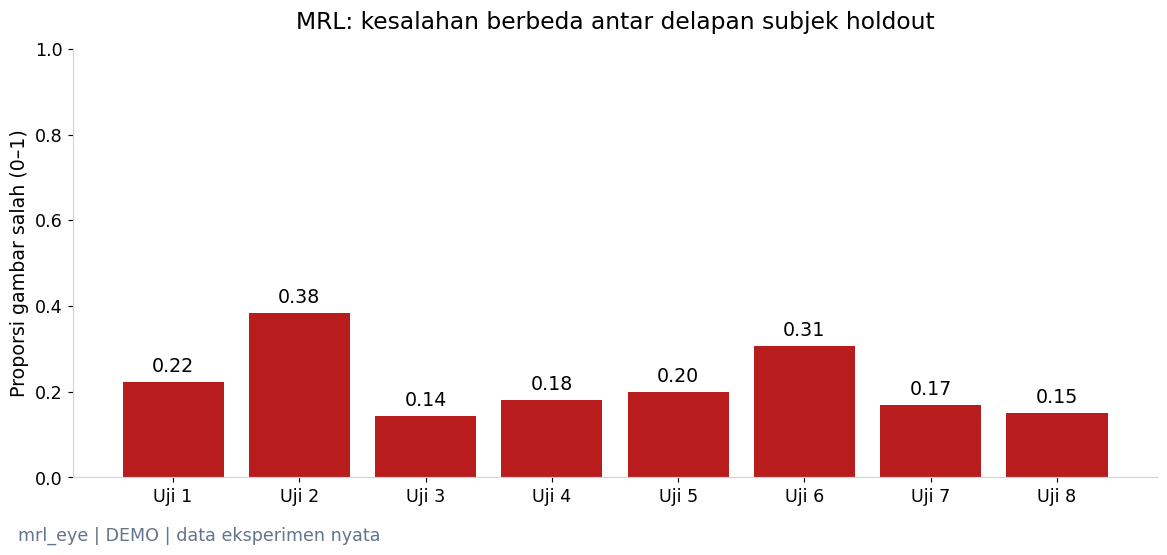

**Yang terlihat:** Proporsi kesalahan per subjek berkisar 0.14–0.38.

**Artinya:** Rata-rata global dapat menyembunyikan perbedaan antarorang.

**Perlu diingat:** ID tampilan disamarkan; tidak ada contoh foto peserta yang dipublikasikan.

*Sumber: `20261024T164355883823Z_seed42_91ed89` · REAL / CACHED; inference dihitung ulang.*

In [14]:
mrl_errors = mrl_predictions[mrl_predictions.model.eq('hog_linear_svm') & mrl_predictions.split.eq('test')].copy()
mrl_errors['Salah'] = mrl_errors.truth.ne(mrl_errors.prediction)
subject_error = mrl_errors.groupby('subject_id').Salah.mean().sort_index()
fig, ax = plt.subplots(layout='constrained')
bars = ax.bar([f'Uji {i+1}' for i in range(len(subject_error))], subject_error, color=COLORS['error'])
ax.bar_label(bars, fmt='%.2f', padding=4)
ax.set(ylabel='Proporsi gambar salah (0–1)', ylim=(0,1), title='MRL: kesalahan berbeda antar delapan subjek holdout')
mrl_book.show(fig, 'error_per_subjek_mrl',
              f'Proporsi kesalahan per subjek berkisar {subject_error.min():.2f}–{subject_error.max():.2f}.',
              'Rata-rata global dapat menyembunyikan perbedaan antarorang.',
              'ID tampilan disamarkan; tidak ada contoh foto peserta yang dipublikasikan.')
mrl_book.finish()
if RUN_MODE == 'FULL':
    mrl_run.complete(mrl_metrics, {'evaluation_rows':len(mrl_data), 'decoded_duplicates_removed':decoded_duplicates,
                                 'subject_overlap':0, 'feature_missing_fraction':float(mrl_data[mrl_columns].isna().mean().mean())}, warning_records)

---

## 2. BAGIAN B — DROZY: Pola Mata Sepanjang Waktu dan KSS

**Ini tugas baru dengan label berbeda. Tidak ada satu skor gabungan dengan MRL.**

Pertanyaan pertama: bagaimana koordinat mata menjadi fitur kedipan dan penutupan mata? Pertanyaan kedua: apakah agregat fitur dapat memperkirakan **KSS** (*Karolinska Sleepiness Scale*), penilaian subjektif rasa kantuk skala 1–9, pada orang yang tidak ada dalam training?

DROZY menggunakan satu KSS asli per test. Banyak window dari satu test bukan banyak penilaian manusia independen. Test berulang pada orang yang sama tetap berkorelasi. Data dan wajah dibatasi untuk riset; notebook hanya menampilkan diagram sintetis dan grafik turunan numerik yang terbatas, tanpa gambar wajah.

In [15]:
from atc_fatigue.io.drozy import read_landmarks,process_test
from atc_fatigue.vision.eye_features import ear,ear_68,closure_events,window_features
from atc_fatigue.research.data import kss_test_table,regression_metrics
from sklearn.model_selection import LeaveOneGroupOut
drozy_root = Path(config['visual']['drozy_root'])
if USE_SOURCE_MEDIA:
    if not (drozy_root/'KSS.txt').exists():raise FileNotFoundError('DROZY source belum tersedia; FULL/privat memerlukan sumber berizin.')
    original_kss = np.loadtxt(drozy_root/'KSS.txt',ndmin=2)
    drozy_tests = []
    for path in sorted((drozy_root/'annotations-auto').glob('*-s2.txt')):
        session = path.stem.removesuffix('-s2');subject,trial = map(int,session.split('-'))
        label = float(original_kss[subject-1,trial-1])
        if 1<=label<=9:
            drozy_tests.append({'dataset_id':'drozy','sample_id':f'drozy_test_{session}','subject_id':str(subject),
                'session_id':session,'target_name':'KSS','target_value':label,'label_source':'original_KSS.txt_subject_test','is_synthetic_pair':False})
    drozy_manifest = pd.DataFrame(drozy_tests)
else:
    cached_drozy_run,_ = cached_run('drozy_kss',config)
    drozy_manifest = pd.read_parquet(cached_drozy_run.path/'features/features.parquet')

In [16]:
drozy_rights = {'source':'https://www.drozy.uliege.be/', 'variant':'original 2D 68 landmarks + native timestamps + KSS.txt',
                'rights':'research/evaluation only; no redistribution; restricted participant display',
                'public_preview':'synthetic eye geometry and limited derived numeric charts; no faces'}
drozy_limits = ['KSS is sleepiness, not fatigue; repeated tests within 14 subjects',
                'whole-test offline aggregates; no real-time warning',
                'EAR .21 and closure >=500ms uncalibrated; not validated standard PERCLOS']
if RUN_MODE == 'FULL':
    drozy_run = Run.create('drozy_kss','02_visual_analysis.ipynb',config,drozy_manifest,
                           'ear68-duration-v1; test-aggregate-v1',drozy_rights,drozy_limits)
else:
    drozy_run, kss_metrics = cached_run('drozy_kss',config)
drozy_book = FigureBook(drozy_run,RUN_MODE,config)
run_card(drozy_run,RUN_MODE,'FULL: hasil dihitung di evaluasi' if RUN_MODE=='FULL' else
         f"KSS LOSO MAE {kss_metrics['models']['ridge_alpha1']['mae']:.4f} poin")

| Identitas run | Nilai |
| :--- | :--- |
| Mode | **DEMO / CACHED — hasil FULL terverifikasi; inference checkpoint dihitung ulang, tanpa training baru** |
| Run ID sumber | `20261024T164409996849Z_seed42_ae9238` |
| Status eksperimen sumber | completed |
| Dataset / target | drozy / KSS |
| Sampel / subjek | 36 / 14 |
| Unit evaluasi | original_test; held-out subject |
| Hasil utama | KSS LOSO MAE 1.4544 poin |

### 2.1 Menghitung EAR dari enam titik

**EAR** (*Eye Aspect Ratio*) membandingkan dua jarak vertikal dengan lebar mata:

`EAR = (jarak p2–p6 + jarak p3–p5) / (2 × jarak p1–p4)`.

EAR tidak memiliki satuan; mata lebih sempit biasanya menghasilkan rasio lebih rendah. Contoh berikut memakai koordinat buatan dan memperlihatkan hitungan langsung. Mapping 68 landmark DROZY memakai indeks 36:42 dan 42:48, yang sudah diperiksa dengan overlay QC lokal pada pekerjaan sebelumnya.

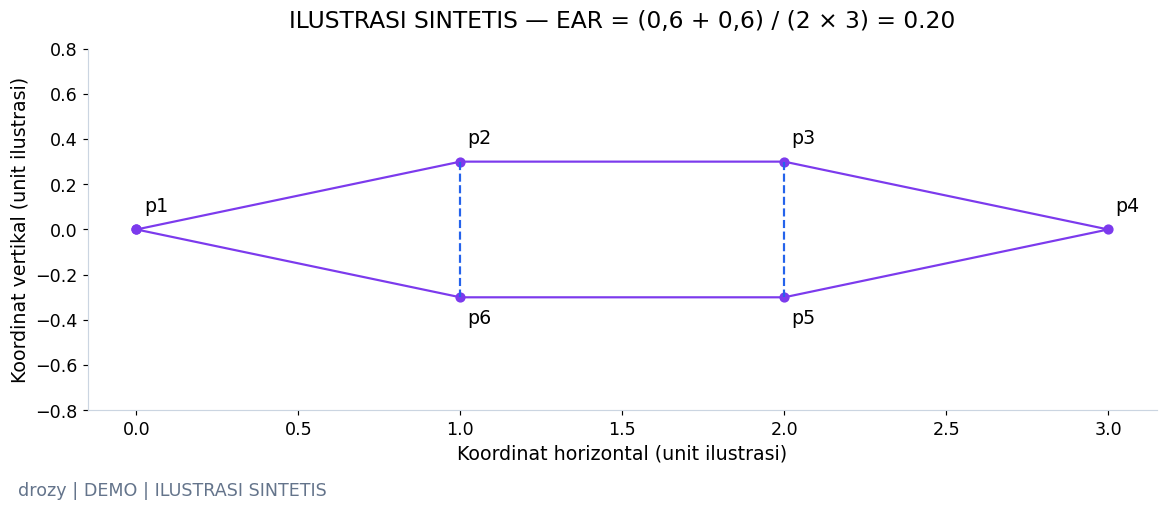

**Yang terlihat:** Enam titik buatan menghasilkan EAR 0,20.

**Artinya:** Rasio mengurangi ketergantungan pada ukuran absolut mata dalam piksel.

**Perlu diingat:** Anatomi, pose, dan landmark error tetap berpengaruh; ini bukan threshold fatigue.

*Sumber: `20261024T164409996849Z_seed42_ae9238` · REAL / CACHED; inference dihitung ulang.*

In [17]:
illustrated_eye = np.array([[0,0],[1,0.3],[2,0.3],[3,0],[2,-0.3],[1,-0.3]])
illustrated_ear = ear(illustrated_eye)
fig, ax = plt.subplots(figsize=(11,4.4),layout='constrained')
outline = np.vstack([illustrated_eye,illustrated_eye[0]])
ax.plot(outline[:,0],outline[:,1],'-o',color=COLORS['visual'])
for i,(x,y) in enumerate(illustrated_eye):
    ax.annotate(f'p{i+1}',(x,y),xytext=(5,12 if y>=0 else -18),textcoords='offset points')
for a,b in [(1,5),(2,4)]:
    ax.plot(illustrated_eye[[a,b],0],illustrated_eye[[a,b],1],'--',color=COLORS['audio'])
ax.set(xlabel='Koordinat horizontal (unit ilustrasi)',ylabel='Koordinat vertikal (unit ilustrasi)',
       ylim=(-0.8,0.8),title=f'ILUSTRASI SINTETIS — EAR = (0,6 + 0,6) / (2 × 3) = {illustrated_ear:.2f}')
drozy_book.show(fig,'geometri_ear','Enam titik buatan menghasilkan EAR 0,20.',
                'Rasio mengurangi ketergantungan pada ukuran absolut mata dalam piksel.',
                'Anatomi, pose, dan landmark error tetap berpengaruh; ini bukan threshold fatigue.',synthetic=True)

In [18]:
example_test = drozy_manifest.iloc[0]
if USE_SOURCE_MEDIA:
    eye_points,timestamps_ms = read_landmarks(drozy_root/f'annotations-auto/{example_test.session_id}-s2.txt',
                                             drozy_root/f'timestamps/{example_test.session_id}.txt')
    ear_left,ear_right,ear_values = ear_68(eye_points)
else:
    cached_frames = pd.read_parquet(drozy_run.path/f'features/windows/{example_test.session_id}.frames.parquet')
    timestamps_ms = cached_frames.timestamp_ms.to_numpy()
    ear_left,ear_right,ear_values = (cached_frames[name].to_numpy() for name in ['ear_left','ear_right','ear_mean'])
    eye_points = None
live_windows = window_features(timestamps_ms,ear_values,config['visual'])
eye_events = closure_events(timestamps_ms,ear_values,config['visual']['ear_threshold'],config['visual']['max_gap_ms'])
display(pd.DataFrame({'Waktu (ms)':timestamps_ms[:5],'EAR kiri':ear_left[:5],'EAR kanan':ear_right[:5],'EAR rerata':ear_values[:5]}))
display(live_windows[['window_start_ms','window_end_ms','blink_count','perclos','valid_coverage']].head())
print(('FRESH source' if USE_SOURCE_MEDIA else 'CACHED native EAR/timestamp; FRESH window calculation'),
      f': {len(timestamps_ms)} frame → {len(live_windows)} window; timestamp asli, bukan asumsi frame/30.')

,Waktu (ms),EAR kiri,EAR kanan,EAR rerata
0,23.0,0.415755,0.423905,0.419830
1,57.0,0.413933,0.426024,0.419979
2,89.0,0.418391,0.431501,0.424946
3,124.0,0.421750,0.434360,0.428055
4,157.0,0.431687,0.444985,0.438336


,window_start_ms,window_end_ms,blink_count,perclos,valid_coverage
0,23.0,60023.0,12,0.0,1.000000
1,60023.0,120023.0,15,0.0,0.989850
2,120023.0,180023.0,4,0.0,0.994717
3,180023.0,240023.0,6,0.0,0.981567
4,240023.0,300023.0,9,0.0,0.994500


CACHED native EAR/timestamp; FRESH window calculation : 17865 frame → 10 window; timestamp asli, bukan asumsi frame/30.


### 2.1a Menelusuri geometri dan perubahan EAR

EAR membagi jumlah dua jarak vertikal dengan dua kali lebar horizontal mata.
Ketika kelopak lebih mendekat, jarak vertikal mengecil dan EAR umumnya turun.
Ilustrasi publik berikut memiliki **kontrol parameter yang dapat dieksekusi**: ubah `half_opening` dan jalankan ulang cell.
Buka panel penjelasan untuk membaca jarak dan nilai EAR hasil perhitungan, bukan skor buatan.
Ini geometri sintetis untuk pendidikan; tidak menjadi data training atau label fatigue.

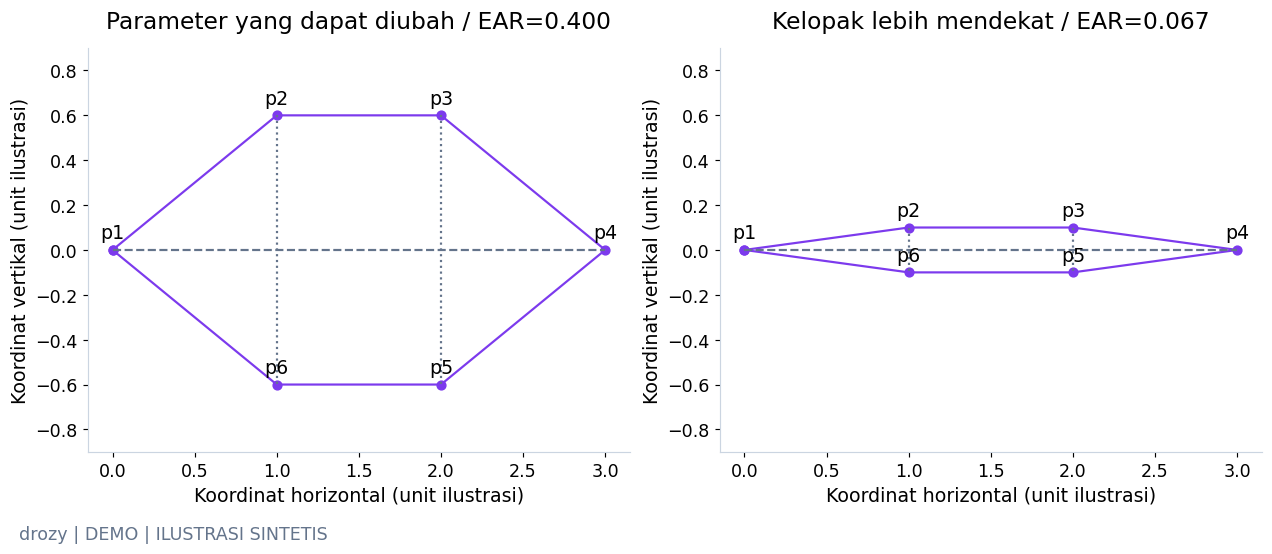

**Yang terlihat:** Jarak horizontal sama sementara dua jarak vertikal berbeda; EAR dihitung dengan fungsi canonical yang juga dipakai pada DROZY.

**Artinya:** Pembaca dapat mengubah satu parameter untuk memahami pengaruh geometri terhadap rasio.

**Perlu diingat:** Ilustrasi sintetis, bukan anotasi fatigue; threshold 0,21 bukan konstanta universal anatomi.

*Sumber: `20261024T164409996849Z_seed42_ae9238` · REAL / CACHED; inference dihitung ulang.*

Keadaan ilustrasi,Vertikal p2–p6,Vertikal p3–p5,Horizontal p1–p4,EAR
Parameter yang dapat diubah,1.2,1.2,3.0,0.4000
Kelopak lebih mendekat,0.2,0.2,3.0,0.0667


In [19]:
from IPython.display import HTML
half_opening = 0.6  # Ubah misalnya menjadi 0.1, lalu run cell untuk eksplorasi geometri.
fig,axes = plt.subplots(1,2,figsize=(12,4.8),layout='constrained')
geometry_rows = []
for axis,opening,title in zip(axes,[half_opening,.1],['Parameter yang dapat diubah','Kelopak lebih mendekat']):
    points = np.array([[0,0],[1,opening],[2,opening],[3,0],[2,-opening],[1,-opening]])
    horizontal = np.linalg.norm(points[0]-points[3]);vertical1 = np.linalg.norm(points[1]-points[5]);vertical2 = np.linalg.norm(points[2]-points[4])
    axis.plot(*np.vstack([points,points[0]]).T,color=COLORS['visual'],marker='o')
    for first,last,style in [(0,3,'--'),(1,5,':'),(2,4,':')]:axis.plot(points[[first,last],0],points[[first,last],1],style,color=COLORS['secondary'])
    for index,(x,y) in enumerate(points):axis.annotate(f'p{index+1}',(x,y),xytext=(0,8),textcoords='offset points',ha='center')
    axis.set(xlabel='Koordinat horizontal (unit ilustrasi)',ylabel='Koordinat vertikal (unit ilustrasi)',ylim=(-.9,.9),title=f'{title} / EAR={ear(points):.3f}')
    geometry_rows.append({'Keadaan ilustrasi':title,'Vertikal p2–p6':vertical1,'Vertikal p3–p5':vertical2,'Horizontal p1–p4':horizontal,'EAR':ear(points)})
drozy_book.show(fig,'ear_geometry_parameter',
                'Jarak horizontal sama sementara dua jarak vertikal berbeda; EAR dihitung dengan fungsi canonical yang juga dipakai pada DROZY.',
                'Pembaca dapat mengubah satu parameter untuk memahami pengaruh geometri terhadap rasio.',
                'Ilustrasi sintetis, bukan anotasi fatigue; threshold 0,21 bukan konstanta universal anatomi.',synthetic=True)
display(HTML('<details><summary>Buka perhitungan numerik dua keadaan mata</summary>'+pd.DataFrame(geometry_rows).round(4).to_html(index=False)+'</details>'))

In [20]:
if PRIVATE_MEDIA:
    first_event = next(event for event in eye_events if event.completed)
    open_index = max(0,int(np.searchsorted(timestamps_ms,first_event.start_ms))-3)
    closed_indices = np.flatnonzero((timestamps_ms>=first_event.start_ms)&(timestamps_ms<first_event.end_ms))
    closed_index = closed_indices[np.argmin(ear_values[closed_indices])]
    fig,axes = plt.subplots(1,3,figsize=(13,4.8),layout='constrained')
    face = eye_points[open_index]
    axes[0].scatter(face[:,0],face[:,1],s=12,color=COLORS['secondary'])
    axes[0].scatter(face[36:48,0],face[36:48,1],s=25,color=COLORS['visual'])
    axes[0].set(title='68 landmark asli / titik mata 36–47',xlabel='Koordinat x (piksel sumber)',ylabel='Koordinat y (piksel sumber)');axes[0].invert_yaxis()
    for axis,index,title in zip(axes[1:],[open_index,closed_index],['Sebelum closure','Dalam kandidat closure']):
        points = eye_points[index,36:42]
        axis.plot(*np.vstack([points,points[0]]).T,color=COLORS['visual'],marker='o')
        for first,last,style in [(0,3,'--'),(1,5,':'),(2,4,':')]:axis.plot(points[[first,last],0],points[[first,last],1],style,color=COLORS['secondary'])
        for j,(x,y) in enumerate(points):axis.annotate(f'p{j+1}',(x,y),xytext=(0,6),textcoords='offset points')
        axis.set(title=f'{title}\nEAR kiri={ear(points):.3f}',xlabel='x (piksel sumber)',ylabel='y (piksel sumber)');axis.invert_yaxis()
    both_states = np.concatenate([eye_points[open_index,36:42],eye_points[closed_index,36:42]])
    for axis in axes[1:]:
        axis.set(xlim=(both_states[:,0].min()-.8,both_states[:,0].max()+.8),
                 ylim=(both_states[:,1].max()+.8,both_states[:,1].min()-.8))
        axis.set_aspect('equal',adjustable='box')
    drozy_book.show(fig,'drozy_real_landmark_ear_local',
                    'Landmark aktual memperlihatkan mapping68→enam titik dan nilai EAR sebelum/dalam satu event pada test yang sama.',
                    'Jarak yang tampak pada koordinat ini benar-benar digunakan fungsi EAR; rerata kedua mata dipakai time series.',
                    'Koordinat wajah sumber hanya lokal; landmark otomatis belum seluruhnya divalidasi manual.',private=True,origin='REAL / FRESH — LOCAL ONLY')
else:
    print('Overlay landmark asli privat dinonaktifkan; diagram sintetis dan EAR cache tetap tersedia.')

Media sumber hanya tersedia pada salinan eksekusi lokal; output privat dihilangkan dari salinan publik.


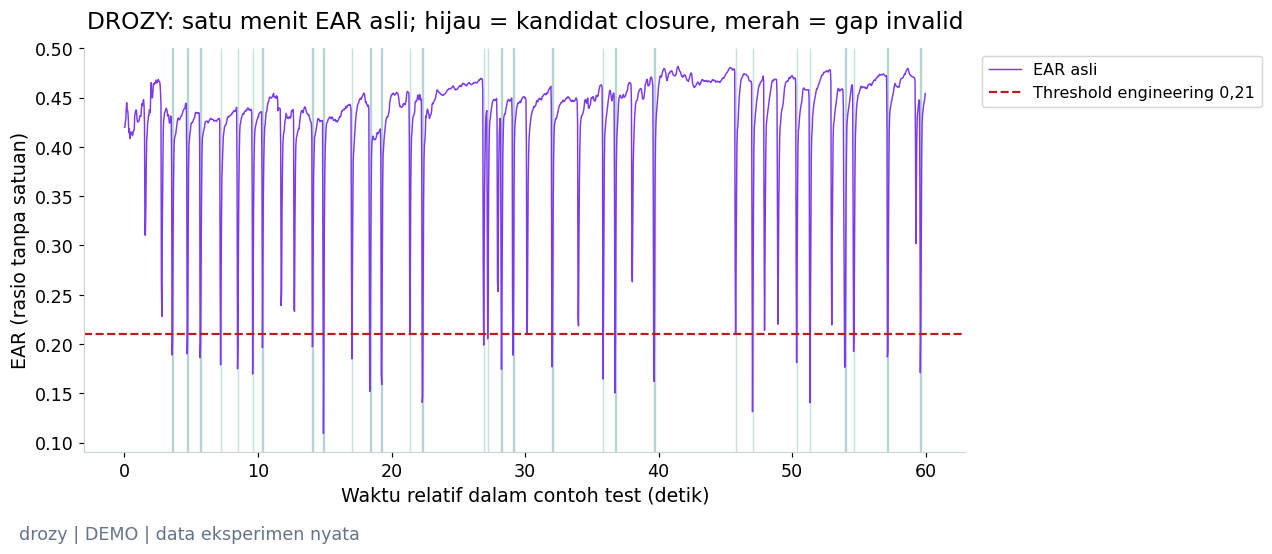

**Yang terlihat:** Terdapat 91 kandidat blink selesai pada seluruh contoh test.

**Artinya:** Event menghitung rentang penutupan, bukan jumlah frame yang berada di bawah threshold.

**Perlu diingat:** Grafik hanya menit pertama; event kandidat belum diverifikasi manual sebagai kedipan fisiologis.

*Sumber: `20261024T164409996849Z_seed42_ae9238` · REAL / CACHED; inference dihitung ulang.*

In [21]:
relative_ms = timestamps_ms-timestamps_ms[0]
first_minute = relative_ms <= 60000
fig, ax = plt.subplots(figsize=(12,4.8),layout='constrained')
ax.plot(relative_ms[first_minute]/1000,ear_values[first_minute],color=COLORS['visual'],lw=1,label='EAR asli')
ax.axhline(config['visual']['ear_threshold'],color=COLORS['error'],ls='--',label='Threshold engineering 0,21')
for event in eye_events:
    start = (event.start_ms-timestamps_ms[0])/1000
    end = (event.end_ms-timestamps_ms[0])/1000
    if 0 <= start < 60:
        ax.axvspan(start,min(end,60),color=COLORS['fusion'],alpha=0.22)
for gap_index in np.flatnonzero(np.diff(timestamps_ms)>config['visual']['max_gap_ms']):
    if relative_ms[gap_index]<60000:
        ax.axvspan(relative_ms[gap_index]/1000,min(relative_ms[gap_index+1]/1000,60),color=COLORS['error'],alpha=0.25)
ax.set(xlabel='Waktu relatif dalam contoh test (detik)',ylabel='EAR (rasio tanpa satuan)',
       title='DROZY: satu menit EAR asli; hijau = kandidat closure, merah = gap invalid')
ax.legend(loc='upper left',bbox_to_anchor=(1.01,1),fontsize=11)
drozy_book.show(fig,'ear_dan_events',
                f'Terdapat {sum(e.completed and 50<=e.end_ms-e.start_ms<=500 for e in eye_events)} kandidat blink selesai pada seluruh contoh test.',
                'Event menghitung rentang penutupan, bukan jumlah frame yang berada di bawah threshold.',
                'Grafik hanya menit pertama; event kandidat belum diverifikasi manual sebagai kedipan fisiologis.')

### Membaca keputusan satu event: zoom kandidat closure

Grafik satu menit membantu melihat pola umum, tetapi terlalu padat untuk menjelaskan keputusan algoritma.
Berikut dua event selesai paling awal yang memenuhi durasi kandidat blink 50–500 ms, dipilih menurut timestamp, bukan karena tampilannya bagus.
Area teal menunjukkan interval EAR di bawah threshold; angka durasi memakai timestamp asli.
Jika ada gap lebih dari 150 ms atau EAR invalid di sekitar event, area tersebut diarsir merah dan tidak dianggap bukti mata tertutup.
**Kandidat closure** adalah keluaran aturan numerik; belum diverifikasi sebagai kedipan fisiologis.

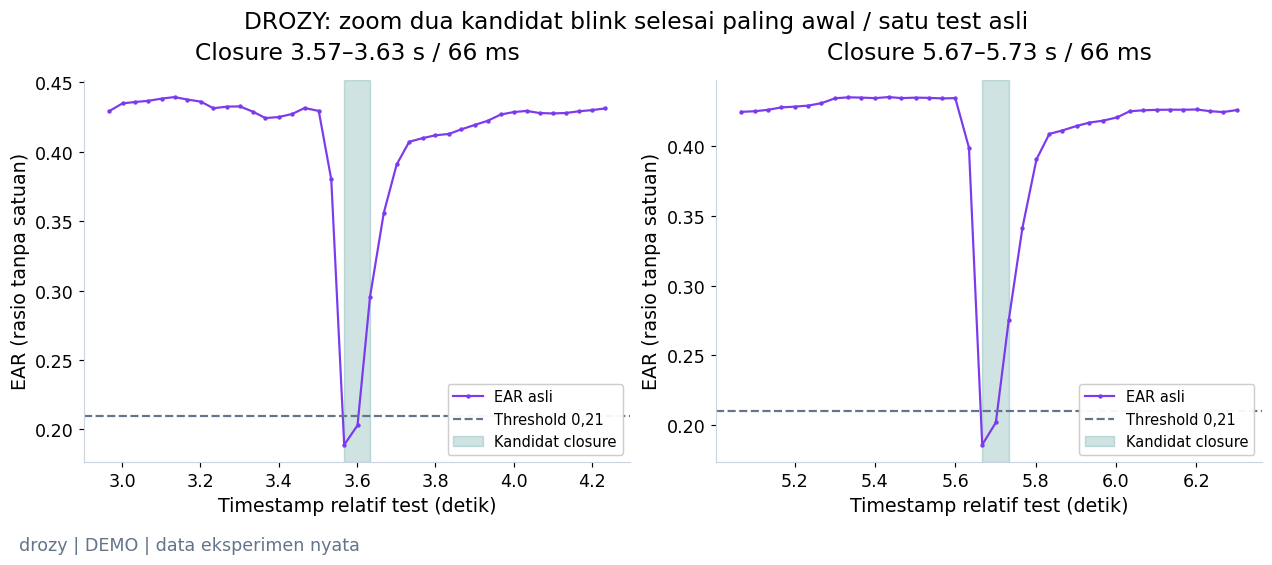

**Yang terlihat:** Kurva melintasi threshold dan kembali terbuka; arsiran membatasi awal dan akhir event berdasarkan timestamp.

**Artinya:** Durasi penutupan dihitung dari rentang waktu, bukan sekadar banyaknya frame di bawah threshold.

**Perlu diingat:** Threshold belum dikalibrasi per orang; event sangat singkat atau panjang tidak otomatis blink valid.

*Sumber: `20261024T164409996849Z_seed42_ae9238` · FRESH — landmark dan timestamp asli.*

In [22]:
zoom_events = [event for event in eye_events if event.completed and 50 <= event.end_ms-event.start_ms <= 500][:2]
if not zoom_events:
    display(Markdown('Tidak ada event selesai pada contoh test ini; tidak dibuat contoh buatan.'))
else:
    fig,axes = plt.subplots(1,len(zoom_events),figsize=(12,4.9),squeeze=False,layout='constrained')
    for ax,event in zip(axes[0],zoom_events):
        start_s,end_s = (event.start_ms-timestamps_ms[0])/1000,(event.end_ms-timestamps_ms[0])/1000
        within = (relative_ms/1000 >= start_s-.6)&(relative_ms/1000 <= end_s+.6)
        ax.plot(relative_ms[within]/1000,ear_values[within],color=COLORS['visual'],marker='.',ms=4,label='EAR asli')
        ax.axhline(config['visual']['ear_threshold'],color=COLORS['secondary'],ls='--',label='Threshold 0,21')
        ax.axvspan(start_s,end_s,color=COLORS['fusion'],alpha=.2,label='Kandidat closure')
        for index in np.flatnonzero(np.diff(timestamps_ms)>config['visual']['max_gap_ms']):
            if relative_ms[index]/1000 < end_s+.6 and relative_ms[index+1]/1000 > start_s-.6:
                ax.axvspan(relative_ms[index]/1000,relative_ms[index+1]/1000,color=COLORS['error'],alpha=.2)
        for index in np.flatnonzero(within & ~np.isfinite(ear_values)):
            ax.axvspan(relative_ms[index]/1000,relative_ms[min(index+1,len(relative_ms)-1)]/1000,color=COLORS['error'],alpha=.2)
        ax.set(xlabel='Timestamp relatif test (detik)',ylabel='EAR (rasio tanpa satuan)',
               title=f'Closure {start_s:.2f}–{end_s:.2f} s / {event.end_ms-event.start_ms:.0f} ms')
        ax.legend(fontsize=10,loc='lower right',framealpha=.95)
    fig.suptitle('DROZY: zoom dua kandidat blink selesai paling awal / satu test asli',fontsize=16)
    drozy_book.show(fig,'ear_event_zoom',
                    'Kurva melintasi threshold dan kembali terbuka; arsiran membatasi awal dan akhir event berdasarkan timestamp.',
                    'Durasi penutupan dihitung dari rentang waktu, bukan sekadar banyaknya frame di bawah threshold.',
                    'Threshold belum dikalibrasi per orang; event sangat singkat atau panjang tidak otomatis blink valid.',origin='FRESH — landmark dan timestamp asli')

### 2.2 Dari frame menjadi window: kualitas dan definisi penutupan

Gap timestamp >150 ms tidak dianggap pengamatan baru dan tidak diinterpolasi. Window 60 detik memerlukan coverage ≥80%. **Blink** adalah event yang selesai, dengan mata terbuka yang teramati di kedua batas dan durasi engineering 50–500 ms.

**PERCLOS operasional** merangkum proporsi durasi closure yang sudah teramati minimal 500 ms di akhir window. Ukuran ini **belum tervalidasi sebagai definisi baku kelopak 80% tertutup**. Threshold EAR 0,21 belum dikalibrasi. Sensitivitas 0,18/0,21/0,24 ditunjukkan tanpa memilih threshold berdasarkan skor KSS.

In [23]:
if RUN_MODE == 'FULL':
    drozy_window_parts, sensitivity_rows, frame_qc = [], [], []
    for test in drozy_manifest.itertuples():
        points_path = drozy_root / f'annotations-auto/{test.session_id}-s2.txt'
        timestamp_path = drozy_root / f'timestamps/{test.session_id}.txt'
        window_path = drozy_run.file(f'features/windows/{test.session_id}.parquet')
        test_windows = process_test(points_path,timestamp_path,test.subject_id,test.session_id,config['visual'],window_path)
        test_windows['target_value'] = test.target_value
        test_windows['label_source'] = 'original_KSS.txt_subject_test; not_independent_window_labels'
        drozy_window_parts.append(test_windows)
        frames = pd.read_parquet(window_path.with_suffix('.frames.parquet'))
        frame_qc.append({'session_id':test.session_id,'frames':len(frames),
                         'gaps_gt150ms':int((frames.timestamp_ms.diff()>config['visual']['max_gap_ms']).sum())})
        for threshold in config['visual']['sensitivity_thresholds']:
            threshold_windows = window_features(frames.timestamp_ms,frames.ear_mean,{**config['visual'],'ear_threshold':threshold})
            sensitivity_rows.append({'session_id':test.session_id,'threshold':threshold,
                                      'perclos':threshold_windows.perclos.mean(),
                                      'blink_rate_per_min':threshold_windows.blink_rate_per_min.mean()})
    drozy_windows = pd.concat(drozy_window_parts,ignore_index=True)
    sensitivity = pd.DataFrame(sensitivity_rows)
    drozy_windows.to_parquet(drozy_run.file('features/windows.parquet'),index=False)
    sensitivity.to_csv(drozy_run.file('features/threshold_sensitivity.csv'),index=False)
    drozy_run.write('features/frame_qc.json',frame_qc)
else:
    drozy_windows = pd.read_parquet(drozy_run.path / 'features/windows.parquet')
    sensitivity = pd.read_csv(drozy_run.path / 'features/threshold_sensitivity.csv')
    frame_qc = json.loads((drozy_run.path / 'features/frame_qc.json').read_text())
cached_example = drozy_windows[drozy_windows.session_id.eq(example_test.session_id)]
np.testing.assert_allclose(live_windows.perclos,cached_example.perclos,equal_nan=True)
display(drozy_windows[['window_start_ms','window_end_ms','ear_mean','blink_rate_per_min','perclos','valid_coverage']].head())

,window_start_ms,window_end_ms,ear_mean,blink_rate_per_min,perclos,valid_coverage
0,23.0,60023.0,0.429510,12.000000,0.0,1.000000
1,60023.0,120023.0,0.436223,15.153811,0.0,0.989850
2,120023.0,180023.0,0.453793,4.021246,0.0,0.994717
3,180023.0,240023.0,0.456470,6.112677,0.0,0.981567
4,240023.0,300023.0,0.443432,9.049774,0.0,0.994500


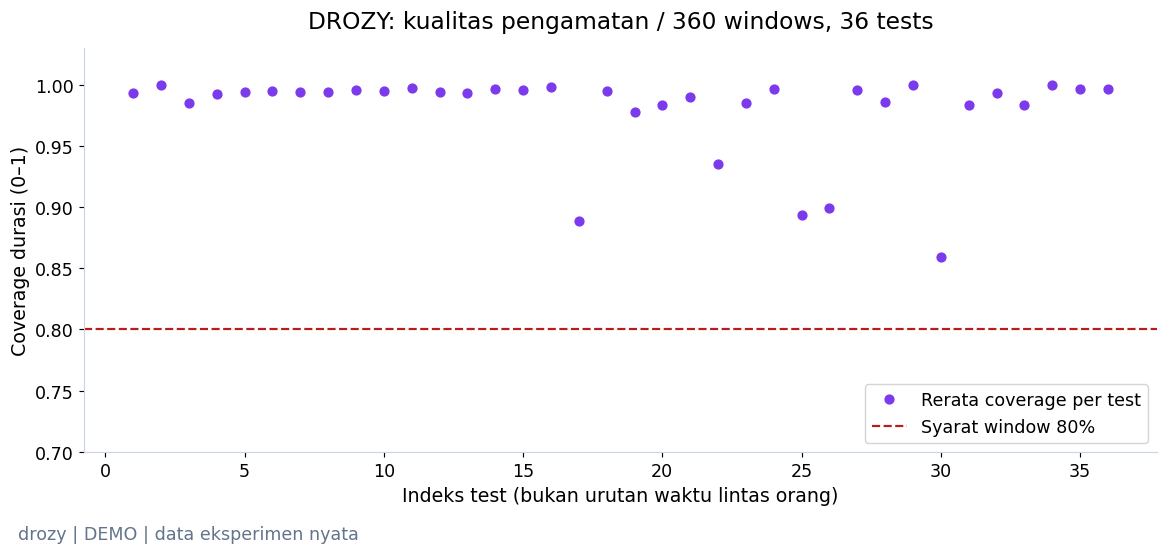

**Yang terlihat:** 348/360 windows tersedia; total gap >150 ms: 1041.

**Artinya:** Coverage menjaga agar waktu yang tidak teramati tidak ikut dihitung sebagai mata terbuka/tertutup.

**Perlu diingat:** Coverage baik tidak menjamin landmark akurat; pose dan kacamata masih perlu QC.

*Sumber: `20261024T164409996849Z_seed42_ae9238` · REAL / CACHED; inference dihitung ulang.*

In [24]:
coverage_summary = drozy_windows.groupby('session_id').valid_coverage.mean().sort_index()
fig, ax = plt.subplots(layout='constrained')
ax.plot(range(1,len(coverage_summary)+1),coverage_summary,'o',color=COLORS['visual'],label='Rerata coverage per test')
ax.axhline(config['visual']['min_coverage'],ls='--',color=COLORS['error'],label='Syarat window 80%')
ax.set(xlabel='Indeks test (bukan urutan waktu lintas orang)',ylabel='Coverage durasi (0–1)',ylim=(0.7,1.03),
       title=f'DROZY: kualitas pengamatan / {len(drozy_windows)} windows, {len(coverage_summary)} tests')
ax.legend(loc='lower right')
drozy_book.show(fig,'coverage_drozy',
                f'{int(drozy_windows.video_available.sum())}/{len(drozy_windows)} windows tersedia; total gap >150 ms: {sum(r["gaps_gt150ms"] for r in frame_qc)}.',
                'Coverage menjaga agar waktu yang tidak teramati tidak ikut dihitung sebagai mata terbuka/tertutup.',
                'Coverage baik tidak menjamin landmark akurat; pose dan kacamata masih perlu QC.')

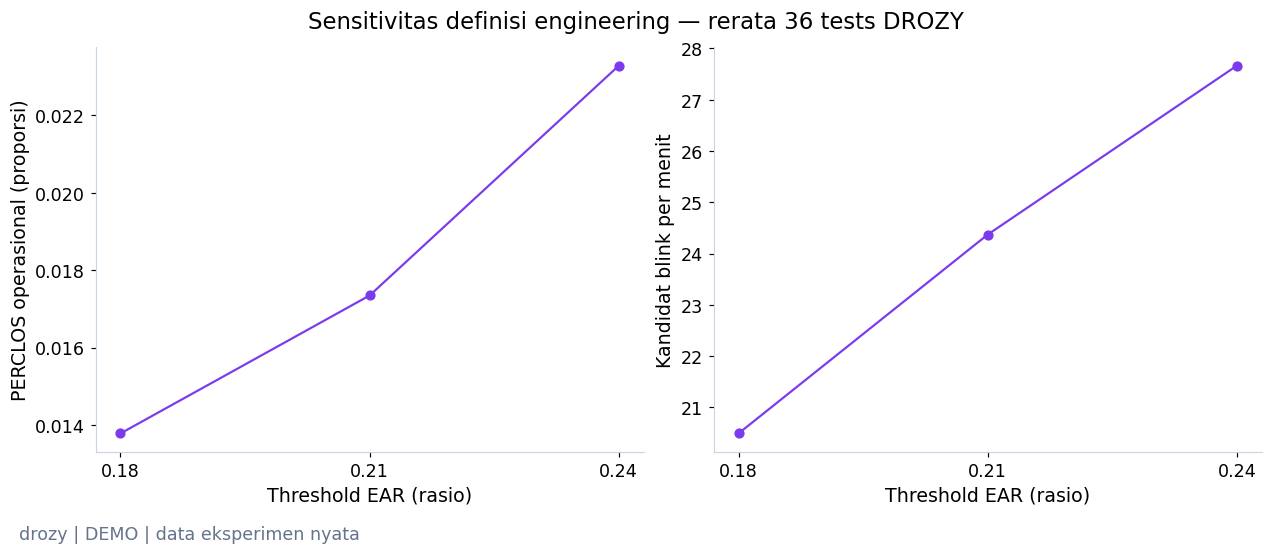

**Yang terlihat:** Mean PERCLOS berubah 0.0138–0.0233 pada threshold yang diperiksa.

**Artinya:** Fitur bergantung pada definisi closure; threshold bukan konstanta universal.

**Perlu diingat:** Model tetap memakai 0,21; tidak ada pemilihan threshold menggunakan hasil holdout KSS.

*Sumber: `20261024T164409996849Z_seed42_ae9238` · REAL / CACHED; inference dihitung ulang.*

In [25]:
threshold_means = sensitivity.groupby('threshold')[['perclos','blink_rate_per_min']].mean()
fig, axes = plt.subplots(1,2,figsize=(12,4.8),layout='constrained')
for ax,column,label in zip(axes,['perclos','blink_rate_per_min'],['PERCLOS operasional (proporsi)','Kandidat blink per menit']):
    ax.plot(threshold_means.index,threshold_means[column],'o-',color=COLORS['visual'])
    ax.set(xlabel='Threshold EAR (rasio)',ylabel=label,xticks=threshold_means.index)
fig.suptitle(f'Sensitivitas definisi engineering — rerata {drozy_manifest.shape[0]} tests DROZY')
drozy_book.show(fig,'sensitivitas_threshold',
                f"Mean PERCLOS berubah {threshold_means.perclos.min():.4f}–{threshold_means.perclos.max():.4f} pada threshold yang diperiksa.",
                'Fitur bergantung pada definisi closure; threshold bukan konstanta universal.',
                'Model tetap memakai 0,21; tidak ada pemilihan threshold menggunakan hasil holdout KSS.')

### 2.2a Apa yang dihitung pada satu window nyata?

Kita pilih window pertama menurut timestamp, bukan window dengan pola paling menarik.
Coverage adalah waktu pengamatan valid dibagi panjang window. Gap >150 ms tidak dipakai sebagai bukti closure.
Kandidat blink memerlukan batas mata terbuka yang teramati serta durasi 50–500 ms.
PERCLOS implementasi ini adalah **proporsi durasi closure teramati ≥500 ms terhadap waktu valid**, berdasarkan EAR <0,21.
Ini **bukan** pengukuran baku persentase kelopak tertutup 80%; threshold dan landmark masih memerlukan kalibrasi/validasi.

In [26]:
selected_window = live_windows.iloc[0]
event_rows = [{'Start relatif (s)':(event.start_ms-timestamps_ms[0])/1000,
    'End relatif (s)':(event.end_ms-timestamps_ms[0])/1000,'Durasi (ms)':event.end_ms-event.start_ms,
    'Batas open teramati':event.completed,
    'Kandidat blink valid aturan':event.completed and 50<=event.end_ms-event.start_ms<=500} for event in eye_events[:8]]
display(pd.DataFrame(event_rows))
display(pd.DataFrame([{'Panjang window (s)':(selected_window.window_end_ms-selected_window.window_start_ms)/1000,
    'Waktu valid (s)':selected_window.video_coverage_seconds,'Coverage (%)':selected_window.valid_coverage*100,
    'Window tersedia':selected_window.video_available,'Kandidat blink':selected_window.blink_count,
    'Blink/min waktu valid':selected_window.blink_rate_per_min,'Closure fraction operasional':selected_window.perclos,
    'Durasi closure numerator (s)':selected_window.perclos*selected_window.video_coverage_seconds}]))
print('Bukan label KSS tambahan: event/frame/window adalah input turunan satu test, bukan observasi ground truth independen.')

,Start relatif (s),End relatif (s),Durasi (ms),Batas open teramati,Kandidat blink valid aturan
0,3.567,3.633,66.0,True,True
1,4.700,4.733,33.0,True,False
2,5.667,5.733,66.0,True,True
3,7.200,7.234,34.0,True,False
4,8.468,8.533,65.0,True,True
5,9.600,9.633,33.0,True,False
6,10.335,10.367,32.0,True,False
7,14.067,14.134,67.0,True,True


,Panjang window (s),Waktu valid (s),Coverage (%),Window tersedia,Kandidat blink,Blink/min waktu valid,Closure fraction operasional,Durasi closure numerator (s)
0,60.0,60.0,100.0,True,12,12.0,0.0,0.0


Bukan label KSS tambahan: event/frame/window adalah input turunan satu test, bukan observasi ground truth independen.


### 2.3 Satu baris per test dan sumber label

Window yang tersedia dirangkum menjadi rerata dan simpangan baku lima fitur, total sepuluh fitur per test. KSS dibaca dari `KSS.txt` pada pasangan subjek/test asli; nilai dummy 0 tidak menjadi target. **360 windows → 36 baris per test**, dengan pengukuran berulang dalam 14 subjek; 36 baris ini pun bukan 36 orang independen.

,Windows,Original tests,Subjek,Fitur per test
0,360,36,14,10


,usable_windows,ear_mean_mean,blink_rate_per_min_mean,perclos_mean,KSS asli per test
0,10,0.439414,9.158735,0.000000,3.0
1,10,0.419268,20.205730,0.001003,6.0
2,10,0.418600,19.518430,0.000000,7.0
3,10,0.368781,32.539184,0.000000,3.0
4,10,0.414012,38.741811,0.000000,7.0


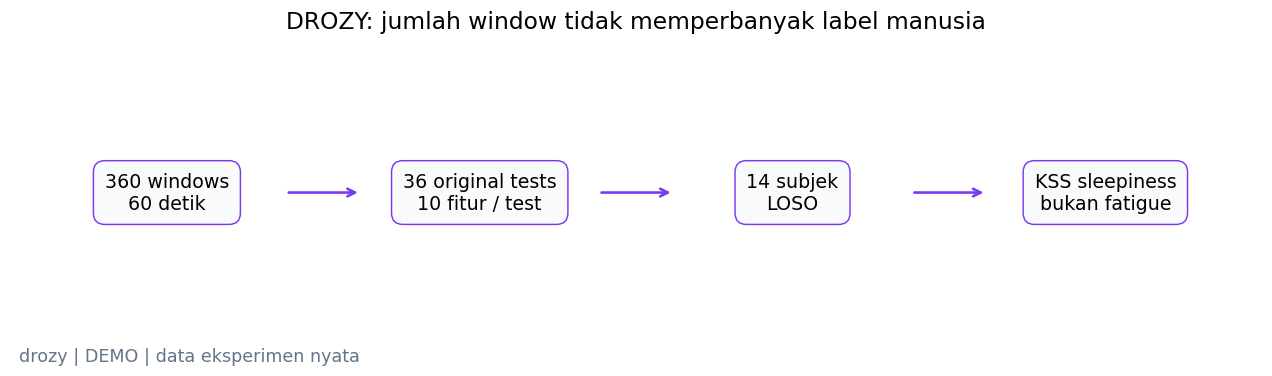

**Yang terlihat:** Satu KSS asli dipasangkan dengan satu agregat test.

**Artinya:** Evaluasi mempertahankan resolusi label dan menahan subjek yang sama di satu fold uji.

**Perlu diingat:** Whole-test features memakai seluruh rekaman offline; bukan prediksi awal atau real-time.

*Sumber: `20261024T164409996849Z_seed42_ae9238` · REAL / CACHED; inference dihitung ulang.*

In [27]:
kss_data, kss_columns = kss_test_table(drozy_windows)
assert len(kss_data)==len(drozy_manifest) and kss_data.target_value.between(1,9).all()
display(pd.DataFrame([{'Windows':len(drozy_windows),'Original tests':len(kss_data),
                       'Subjek':kss_data.subject_id.nunique(),'Fitur per test':len(kss_columns)}]))
display(kss_data[['usable_windows','ear_mean_mean','blink_rate_per_min_mean','perclos_mean','target_value']].head()
        .rename(columns={'target_value':'KSS asli per test'}))
if RUN_MODE=='FULL':
    drozy_run.features(kss_data,kss_columns,'ear68-duration-v1; test-aggregate-v1')
fig = flow([f'{len(drozy_windows)} windows\n60 detik',f'{len(kss_data)} original tests\n10 fitur / test',
            f'{kss_data.subject_id.nunique()} subjek\nLOSO', 'KSS sleepiness\nbukan fatigue'],
           COLORS['visual'],'DROZY: jumlah window tidak memperbanyak label manusia')
drozy_book.show(fig,'window_ke_test','Satu KSS asli dipasangkan dengan satu agregat test.',
                'Evaluasi mempertahankan resolusi label dan menahan subjek yang sama di satu fold uji.',
                'Whole-test features memakai seluruh rekaman offline; bukan prediksi awal atau real-time.')

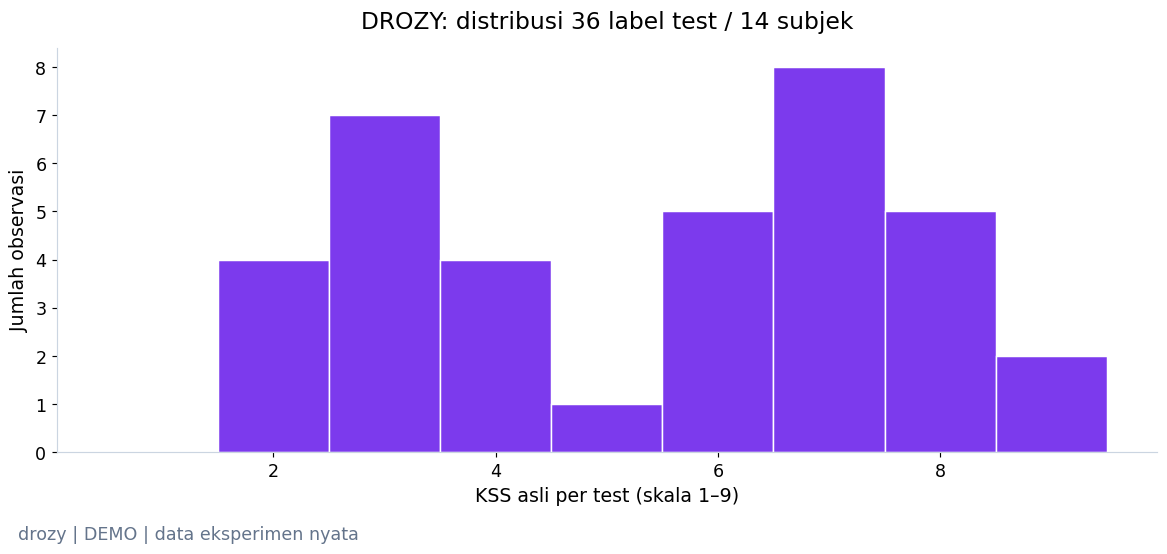

**Yang terlihat:** Skor KSS yang tersedia berkisar 2–9.

**Artinya:** Target adalah angka rasa kantuk subjektif, sehingga masalah ini diperlakukan sebagai regresi.

**Perlu diingat:** Histogram berunit test, tidak dihitung ulang per window; nilai dummy nol tidak dimasukkan.

*Sumber: `20261024T164409996849Z_seed42_ae9238` · REAL / CACHED; inference dihitung ulang.*

In [28]:
fig = histogram(kss_data.target_value.to_numpy(float),'KSS asli per test (skala 1–9)',
                f'DROZY: distribusi {len(kss_data)} label test / {kss_data.subject_id.nunique()} subjek',COLORS['visual'],bins=np.arange(0.5,10,1))
drozy_book.show(fig,'distribusi_kss',
                f'Skor KSS yang tersedia berkisar {kss_data.target_value.min():.0f}–{kss_data.target_value.max():.0f}.',
                'Target adalah angka rasa kantuk subjektif, sehingga masalah ini diperlakukan sebagai regresi.',
                'Histogram berunit test, tidak dihitung ulang per window; nilai dummy nol tidak dimasukkan.')

### 2.3a Window → satu vektor test → X dan y

KSS asli tersedia per **test**, bukan per window. Karena itu lima fitur dari window yang tersedia diringkas dengan mean dan std
menjadi **10 fitur per test**. Window unavailable tidak diisi sebagai pengukuran valid.
Tabel berikut memperlihatkan window contoh, vektor test yang dihasilkan, dan schema yang benar-benar dipakai Ridge.
**360 window tetap hanya menghasilkan 36 target KSS asli dari 14 orang.**

In [29]:
example_windows = drozy_windows[drozy_windows.session_id.eq(example_test.session_id)]
example_kss = kss_data[kss_data.session_id.eq(example_test.session_id)].iloc[0]
display(example_windows[['window_start_ms','ear_mean','blink_rate_per_min','perclos','video_available']].reset_index(drop=True))
display(pd.DataFrame({'Feature':kss_columns,'Nilai satu test':[example_kss[name] for name in kss_columns]}))
display(pd.DataFrame([{'X seluruh test':str(kss_data[kss_columns].shape),'y':str(kss_data.target_value.shape),
                       'Test':len(kss_data),'Peserta':kss_data.subject_id.nunique(),'Missing cells X':int(kss_data[kss_columns].isna().sum().sum())}]))

,window_start_ms,ear_mean,blink_rate_per_min,perclos,video_available
0,23.0,0.429510,12.000000,0.0,True
1,60023.0,0.436223,15.153811,0.0,True
2,120023.0,0.453793,4.021246,0.0,True
3,180023.0,0.456470,6.112677,0.0,True
4,240023.0,0.443432,9.049774,0.0,True
5,300023.0,0.433371,14.083326,0.0,True
6,360023.0,0.440536,5.028326,0.0,True
7,420023.0,0.428960,11.112421,0.0,True
8,480023.0,0.427964,11.000000,0.0,True
9,540023.0,0.443878,4.025765,0.0,True


,Feature,Nilai satu test
0,ear_mean_mean,0.439414
1,ear_mean_std,0.009593
2,ear_std_mean,0.062421
3,ear_std_std,0.002896
4,blink_rate_per_min_mean,9.158735
5,blink_rate_per_min_std,3.931466
6,blink_duration_mean_ms_mean,72.678167
7,blink_duration_mean_ms_std,7.422186
8,perclos_mean,0.000000
9,perclos_std,0.000000


,X seluruh test,y,Test,Peserta,Missing cells X
0,"(36, 10)","(36,)",36,14,0


### 2.4 Training LOSO yang dapat diperiksa

**LOSO** (*Leave-One-Subject-Out*) melatih model pada semua orang kecuali satu, lalu menguji seluruh tests orang yang ditahan. Ini diulang untuk 14 orang. Pada setiap fold, median dan skala hanya dipelajari dari training.

**Dummy mean** menebak KSS rerata training. **Ridge** adalah regresi linear dengan pembatasan besar koefisien (`alpha=1`) untuk mengurangi kecocokan berlebihan pada sampel kecil. FULL menjalankan seluruh fold; DEMO menguji ulang inference satu fold dari checkpoint tersimpan, tanpa mengaku melakukan training ulang.

,Fold,Subjek train,Subjek test,Tests train,Tests uji
0,1,13,1,33,3
1,2,13,1,34,2
2,3,13,1,33,3
3,4,13,1,35,1
4,5,13,1,34,2


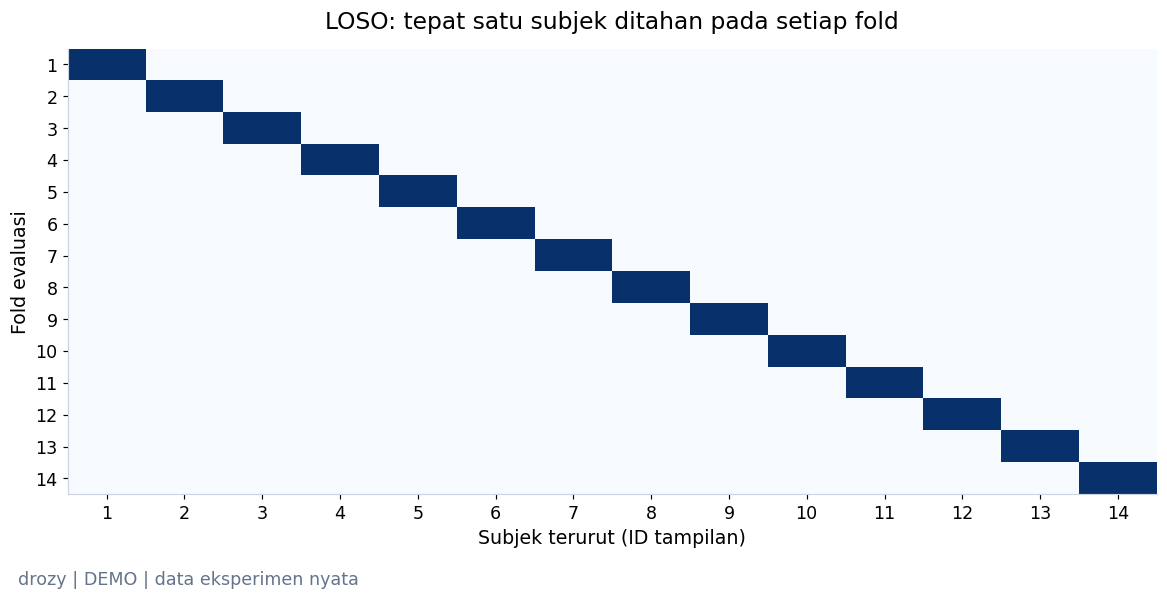

**Yang terlihat:** Sel biru menunjukkan subjek test; subjek lainnya menjadi training.

**Artinya:** Tidak ada data orang yang sedang diuji untuk fit model atau preprocessing fold tersebut.

**Perlu diingat:** LOSO pada korpus kecil belum menggantikan validasi pada operator ATC.

*Sumber: `20261024T164409996849Z_seed42_ae9238` · REAL / CACHED; inference dihitung ulang.*

In [30]:
kss_folds = list(LeaveOneGroupOut().split(kss_data,groups=kss_data.subject_id))
fold_display = []
for fold_index,(training_indices,test_indices) in enumerate(kss_folds):
    training_subjects = set(kss_data.iloc[training_indices].subject_id)
    heldout_subjects = set(kss_data.iloc[test_indices].subject_id)
    assert not training_subjects & heldout_subjects
    fold_display.append({'Fold':fold_index+1,'Subjek train':len(training_subjects),'Subjek test':len(heldout_subjects),
                         'Tests train':len(training_indices),'Tests uji':len(test_indices)})
display(pd.DataFrame(fold_display).head())
membership = np.zeros((len(kss_folds),kss_data.subject_id.nunique()))
subject_order = sorted(kss_data.subject_id.unique())
for i,(_,heldout_indices) in enumerate(kss_folds):
    membership[i,subject_order.index(kss_data.iloc[heldout_indices].subject_id.iloc[0])] = 1
fig, ax = plt.subplots(figsize=(11,5.2),layout='constrained')
ax.imshow(membership,aspect='auto',cmap='Blues',vmin=0,vmax=1)
ax.set(xlabel='Subjek terurut (ID tampilan)',ylabel='Fold evaluasi',title='LOSO: tepat satu subjek ditahan pada setiap fold',
       xticks=range(len(subject_order)),xticklabels=range(1,len(subject_order)+1),
       yticks=range(len(kss_folds)),yticklabels=range(1,len(kss_folds)+1))
drozy_book.show(fig,'diagram_loso','Sel biru menunjukkan subjek test; subjek lainnya menjadi training.',
                'Tidak ada data orang yang sedang diuji untuk fit model atau preprocessing fold tersebut.',
                'LOSO pada korpus kecil belum menggantikan validasi pada operator ATC.')

In [31]:
if RUN_MODE=='FULL':
    kss_prediction_parts, fold_manifests, fold_rows = [], [], []
    for fold_index,(training_indices,test_indices) in enumerate(kss_folds):
        training,holdout = kss_data.iloc[training_indices],kss_data.iloc[test_indices]
        fold_manifests.append({'fold':fold_index,'train_subjects':sorted(training.subject_id.unique()),
                               'test_subjects':sorted(holdout.subject_id.unique())})
        for partition,subset in [('train',training),('test',holdout)]:
            fold_rows.append(subset[['sample_id','subject_id','session_id','target_value']].assign(fold=fold_index,split=partition))
        for model_name,estimator in [('dummy_mean',DummyRegressor()),('ridge_alpha1',Ridge(alpha=1.0))]:
            model = make_pipeline(SimpleImputer(strategy='median',keep_empty_features=True),StandardScaler(),estimator)
            model.fit(training[kss_columns],training.target_value)
            predicted = save_model(drozy_run,f'{model_name}_fold{fold_index:02d}',model,kss_columns,holdout)
            kss_prediction_parts.append(prediction_table(holdout,predicted,model_name,fold=fold_index))
    kss_predictions = pd.concat(kss_prediction_parts,ignore_index=True)
    kss_predictions.to_csv(drozy_run.file('predictions/holdout_predictions.csv'),index=False)
    pd.concat(fold_rows).to_csv(drozy_run.file('split_manifest.csv'),index=False)
    drozy_run.write('folds.json',fold_manifests)
    kss_scores = {name:regression_metrics(group) for name,group in kss_predictions.groupby('model')}
    kss_metrics = metrics_base(drozy_run,kss_scores,{'train':{'per_fold':[len(t) for t,_ in kss_folds]},
                              'test':len(kss_data)}, {'KSS':'original per-test 1–9'},'dummy_mean')
else:
    kss_predictions = pd.read_csv(drozy_run.path / 'predictions/holdout_predictions.csv',dtype={'subject_id':str})
    first_holdout = kss_data.iloc[kss_folds[0][1]]
    for model_name in ['dummy_mean','ridge_alpha1']:
        verify_cached_predictions(drozy_run,first_holdout,kss_predictions[kss_predictions.fold.eq(0)],
                                   model_name,f'{model_name}_fold00')
display(pd.DataFrame(kss_metrics['models']).T[['mae','rmse','subject_macro_mae']])

,mae,rmse,subject_macro_mae
dummy_mean,2.051866,2.270424,2.108202
ridge_alpha1,1.45444,1.817016,1.44051


,Fold contoh,X_train,y_train,X_test,y_test,Validation,Overlap subjek
0,0,"(33, 10)","(33,)","(3, 10)","(3,)",tidak ada; Ridge alpha=1 tetap,0


,feature,raw,transformed
0,ear_mean_mean,0.4394,0.9726
1,ear_mean_std,0.0096,-0.7459
2,ear_std_mean,0.0624,-0.3799
3,ear_std_std,0.0029,-1.1110
4,blink_rate_per_min_mean,9.1587,-0.9418
5,blink_rate_per_min_std,3.9315,-0.4536
6,blink_duration_mean_ms_mean,72.6782,-1.3652
7,blink_duration_mean_ms_std,7.4222,-1.0276
8,perclos_mean,0.0000,-0.4353
9,perclos_std,0.0000,-0.5551


,ear_mean_mean,ear_mean_std,ear_std_mean,ear_std_std,blink_rate_per_min_mean,blink_rate_per_min_std,blink_duration_mean_ms_mean,blink_duration_mean_ms_std,perclos_mean,perclos_std
0,-0.211,-0.509,0.124,-1.065,0.439,-0.505,-0.224,-0.590,-0.435,-0.555
1,0.547,1.171,1.009,-0.017,0.806,0.488,-0.531,-0.875,-0.435,-0.555
2,0.096,-0.754,-0.175,-0.829,-0.201,-0.350,-0.944,-1.097,-0.411,-0.433


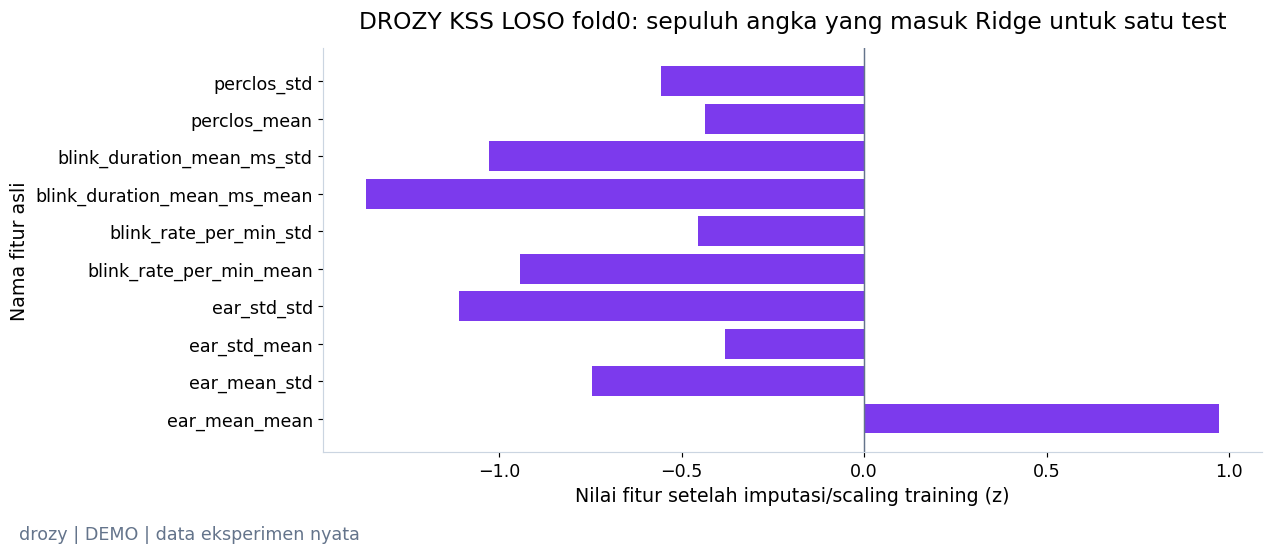

**Yang terlihat:** Nilai berasal dari transform pipeline fold0 tersimpan; median dan scaler tidak belajar dari subjek test.

**Artinya:** Ridge menggabungkan angka ini untuk menghasilkan satu prediksi KSS per test.

**Perlu diingat:** Skala z bukan skala KSS; aggregate memakai keseluruhan test offline dan tidak mendukung klaim real-time.

*Sumber: `20261024T164409996849Z_seed42_ae9238` · REAL / CACHED; inference dihitung ulang.*

In [32]:
first_training_indices,first_test_indices = kss_folds[0]
first_training,first_test = kss_data.iloc[first_training_indices],kss_data.iloc[first_test_indices]
kss_pipeline = joblib.load(drozy_run.path/'models/ridge_alpha1_fold00.joblib')['model']
kss_input_view = inspect_model_input(kss_pipeline,first_training,first_test,kss_columns)
display(pd.DataFrame([{'Fold contoh':0,'X_train':str(kss_input_view['X_train_shape']),'y_train':str(kss_input_view['y_train_shape']),
                       'X_test':str(kss_input_view['X_test_shape']),'y_test':str(kss_input_view['y_test_shape']),
                       'Validation':'tidak ada; Ridge alpha=1 tetap','Overlap subjek':len(set(first_training.subject_id)&set(first_test.subject_id))}]))
display(kss_input_view['example_vector'].round(4))
display(kss_input_view['transformed_preview'].round(3))
fig,ax = plt.subplots(figsize=(12,4.8),layout='constrained')
values = kss_input_view['example_vector'].transformed.to_numpy()
ax.barh(kss_columns,values,color=COLORS['visual'])
ax.axvline(0,color=COLORS['secondary'],lw=1)
ax.set(xlabel='Nilai fitur setelah imputasi/scaling training (z)',ylabel='Nama fitur asli',title='DROZY KSS LOSO fold0: sepuluh angka yang masuk Ridge untuk satu test')
drozy_book.show(fig,'drozy_actual_model_input',
                'Nilai berasal dari transform pipeline fold0 tersimpan; median dan scaler tidak belajar dari subjek test.',
                'Ridge menggabungkan angka ini untuk menghasilkan satu prediksi KSS per test.',
                'Skala z bukan skala KSS; aggregate memakai keseluruhan test offline dan tidak mendukung klaim real-time.')

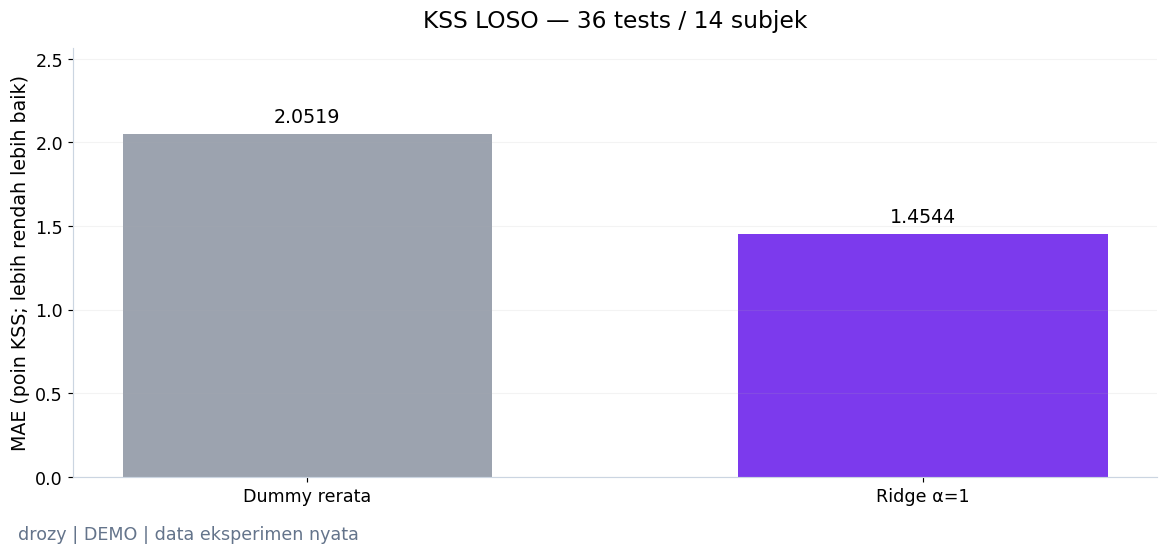

**Yang terlihat:** Ridge MAE 1.4544; Dummy 2.0519 poin KSS.

**Artinya:** MAE adalah rata-rata besar selisih prediksi terhadap label; nilainya dalam satuan poin KSS.

**Perlu diingat:** Angka ini tidak dapat dibandingkan langsung dengan Macro F1 klasifikasi MRL atau RAVDESS.

*Sumber: `20261024T164409996849Z_seed42_ae9238` · REAL / CACHED; inference dihitung ulang.*

In [33]:
fig = model_bars(kss_metrics['models'],'mae',f'KSS LOSO — {len(kss_data)} tests / {kss_data.subject_id.nunique()} subjek',
                 'MAE (poin KSS; lebih rendah lebih baik)',COLORS['visual'])
drozy_book.show(fig,'baseline_mae_kss',
                f"Ridge MAE {kss_metrics['models']['ridge_alpha1']['mae']:.4f}; Dummy {kss_metrics['models']['dummy_mean']['mae']:.4f} poin KSS.",
                'MAE adalah rata-rata besar selisih prediksi terhadap label; nilainya dalam satuan poin KSS.',
                'Angka ini tidak dapat dibandingkan langsung dengan Macro F1 klasifikasi MRL atau RAVDESS.')

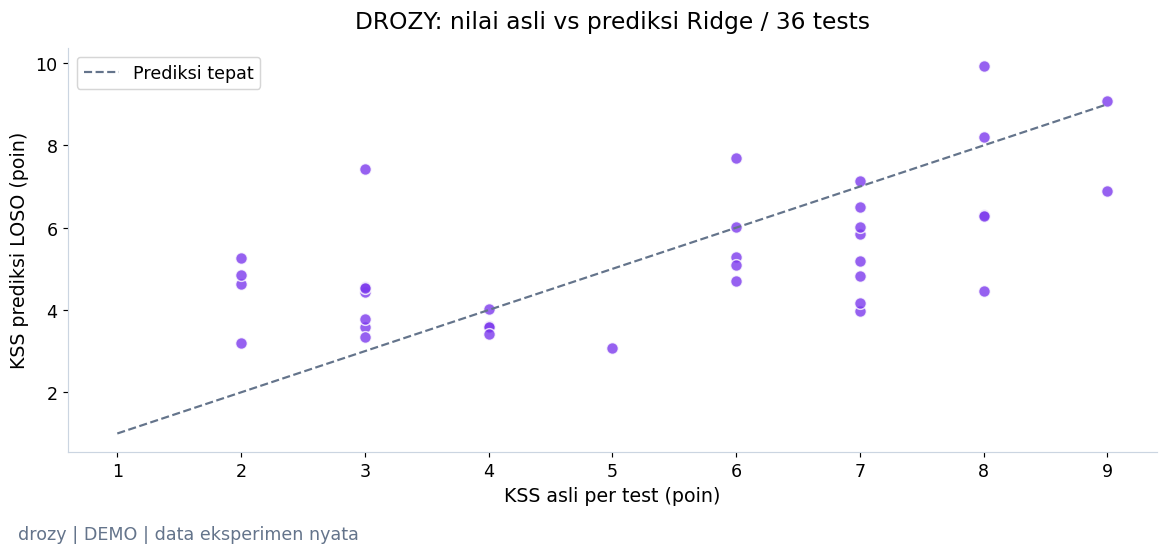

**Yang terlihat:** RMSE Ridge 1.8170 poin; titik di luar garis adalah error nyata.

**Artinya:** Jarak vertikal menunjukkan seberapa jauh prediksi tiap test dari penilaian subjek.

**Perlu diingat:** Prediksi regresi tidak dipotong ke 1–9; angka ekstrem tetap terlihat sebagai kegagalan.

*Sumber: `20261024T164409996849Z_seed42_ae9238` · REAL / CACHED; inference dihitung ulang.*

In [34]:
ridge_holdout = kss_predictions[kss_predictions.model.eq('ridge_alpha1')].copy()
ridge_holdout['residual'] = ridge_holdout.prediction-ridge_holdout.truth
fig,ax = plt.subplots(layout='constrained')
ax.scatter(ridge_holdout.truth,ridge_holdout.prediction,s=65,alpha=0.8,color=COLORS['visual'],edgecolor='white')
ax.plot([1,9],[1,9],'--',color=COLORS['secondary'],label='Prediksi tepat')
ax.set(xlabel='KSS asli per test (poin)',ylabel='KSS prediksi LOSO (poin)',
       title=f'DROZY: nilai asli vs prediksi Ridge / {len(ridge_holdout)} tests')
ax.legend()
drozy_book.show(fig,'aktual_vs_prediksi_kss',
                f"RMSE Ridge {kss_metrics['models']['ridge_alpha1']['rmse']:.4f} poin; titik di luar garis adalah error nyata.",
                'Jarak vertikal menunjukkan seberapa jauh prediksi tiap test dari penilaian subjek.',
                'Prediksi regresi tidak dipotong ke 1–9; angka ekstrem tetap terlihat sebagai kegagalan.')

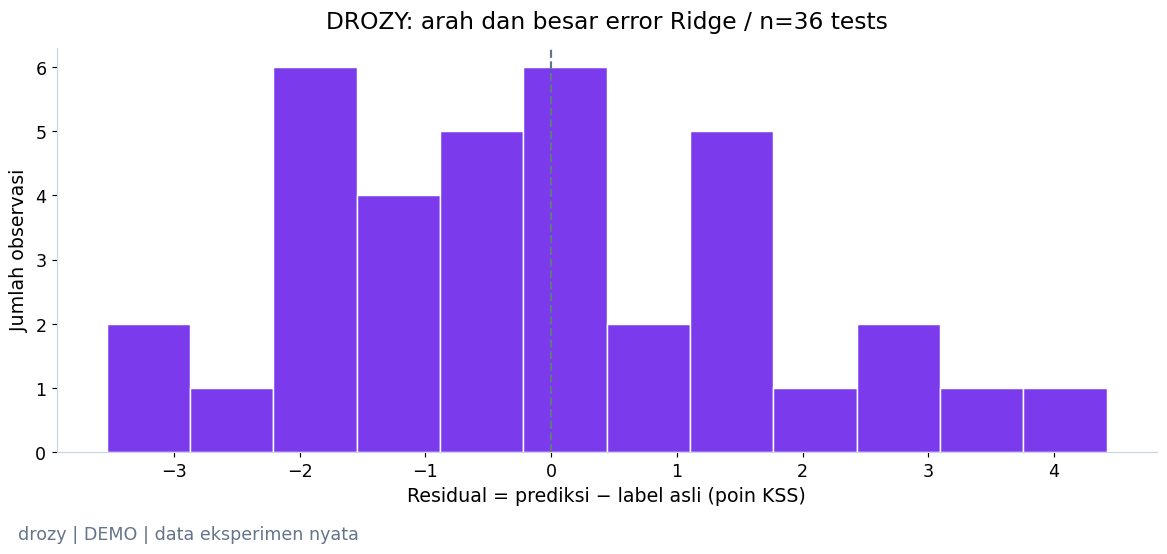

**Yang terlihat:** Residual rerata -0.085 poin; residual negatif berarti kantuk diperkirakan terlalu rendah.

**Artinya:** Distribusi error membantu melihat bias arah yang tidak tampak pada MAE saja.

**Perlu diingat:** Ukuran sampel kecil dan tests berulang membuat histogram ini deskriptif, bukan bukti kalibrasi.

*Sumber: `20261024T164409996849Z_seed42_ae9238` · REAL / CACHED; inference dihitung ulang.*

In [35]:
fig = histogram(ridge_holdout.residual.to_numpy(float),'Residual = prediksi − label asli (poin KSS)',
                f'DROZY: arah dan besar error Ridge / n={len(ridge_holdout)} tests',COLORS['visual'],bins=12)
fig.axes[0].axvline(0,color=COLORS['secondary'],ls='--')
drozy_book.show(fig,'residual_kss',
                f'Residual rerata {ridge_holdout.residual.mean():.3f} poin; residual negatif berarti kantuk diperkirakan terlalu rendah.',
                'Distribusi error membantu melihat bias arah yang tidak tampak pada MAE saja.',
                'Ukuran sampel kecil dan tests berulang membuat histogram ini deskriptif, bukan bukti kalibrasi.')

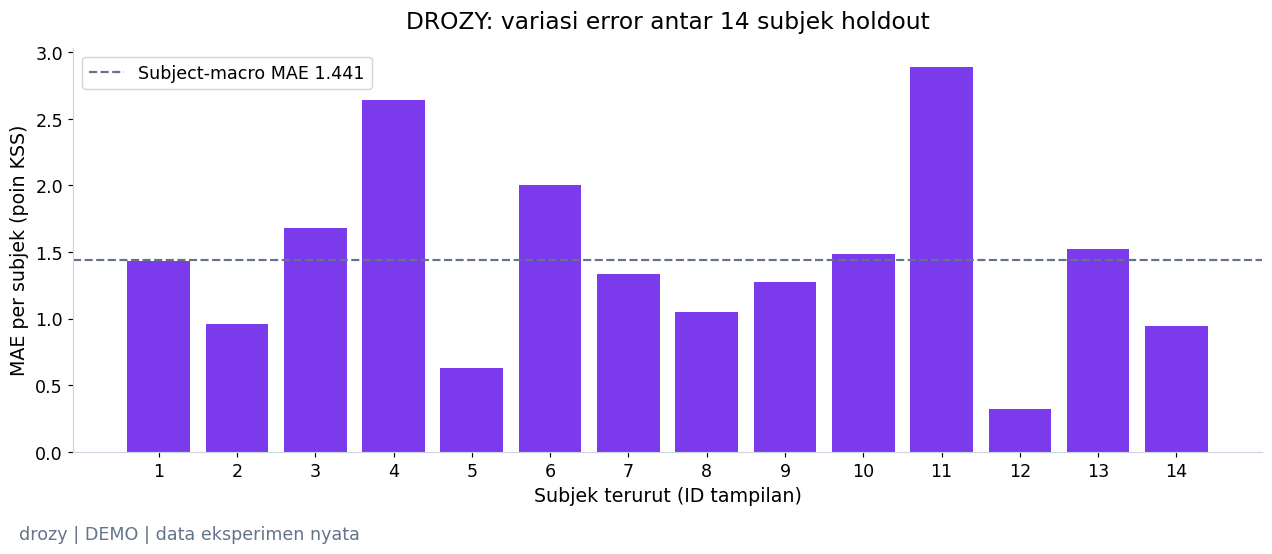

**Yang terlihat:** MAE per subjek berkisar 0.322–2.887 poin.

**Artinya:** Subject-macro MAE memberi bobot sama pada setiap orang, meski jumlah tests berbeda.

**Perlu diingat:** Variasi ini belum merupakan interval keyakinan generalisasi ke populasi ATC.

*Sumber: `20261024T164409996849Z_seed42_ae9238` · REAL / CACHED; inference dihitung ulang.*

,KSS asli,Prediksi,Residual (poin)
56,3.0,7.418879,4.418879
51,8.0,4.464907,-3.535093
55,2.0,5.254549,3.254549
5,7.0,3.986133,-3.013867
65,2.0,4.850213,2.850213


In [36]:
subject_mae = ridge_holdout.assign(error=ridge_holdout.residual.abs()).groupby('subject_id').error.mean().sort_index()
fig,ax = plt.subplots(figsize=(12,4.8),layout='constrained')
ax.bar(range(1,len(subject_mae)+1),subject_mae,color=COLORS['visual'])
ax.axhline(subject_mae.mean(),color=COLORS['secondary'],ls='--',label=f'Subject-macro MAE {subject_mae.mean():.3f}')
ax.set(xlabel='Subjek terurut (ID tampilan)',ylabel='MAE per subjek (poin KSS)',
       title='DROZY: variasi error antar 14 subjek holdout',xticks=range(1,len(subject_mae)+1))
ax.legend()
drozy_book.show(fig,'mae_per_subjek_kss',
                f'MAE per subjek berkisar {subject_mae.min():.3f}–{subject_mae.max():.3f} poin.',
                'Subject-macro MAE memberi bobot sama pada setiap orang, meski jumlah tests berbeda.',
                'Variasi ini belum merupakan interval keyakinan generalisasi ke populasi ATC.')
display(ridge_holdout.assign(error=ridge_holdout.residual.abs()).sort_values('error',ascending=False)
        [['truth','prediction','residual']].head(5).rename(columns={'truth':'KSS asli','prediction':'Prediksi','residual':'Residual (poin)'}))

### 2.5 Feature ablation: kelompok informasi mana yang membantu?

Ablation mengulangi protokol LOSO yang sama sambil membatasi kolom input: EAR (4), blink (4), closure fraction (2),
dan gabungan (10), ditambah Dummy mean. Setiap fold membuat imputer/scaler baru dari training saja.
Semua model memakai 36 test dan 14 peserta yang sama. Ridge alpha=1 ditetapkan tetap;
kita tidak memilih parameter berdasarkan skor test, dan skor buruk tetap ditampilkan.

In [37]:
ablation_columns = {'dummy_mean':kss_columns,
    'ear_only':[name for name in kss_columns if name.startswith(('ear_mean_','ear_std_'))],
    'blink_only':[name for name in kss_columns if name.startswith(('blink_rate_','blink_duration_'))],
    'closure_only':[name for name in kss_columns if name.startswith('perclos_')],
    'combined':kss_columns}
if RUN_MODE == 'FULL':
    ablation_run = Run.create('drozy_feature_ablation','02_visual_analysis.ipynb',config,kss_data,
                              'test-aggregate-v1;fixed-alpha1-group-ablation',drozy_rights,drozy_limits+['feature-group comparison exploratory; no tuning'])
    ablation_run.features(kss_data,kss_columns,'test-aggregate-v1;fixed-alpha1-group-ablation')
    ablation_run.write('parent_experiments.json',{'test_features_run':drozy_run.manifest['run_id'],'groups':ablation_columns,'ridge_alpha':1.0})
    ablation_predictions_parts,ablation_splits,ablation_folds = [],[],[]
    for fold,(training_indices,test_indices) in enumerate(kss_folds):
        training,holdout = kss_data.iloc[training_indices],kss_data.iloc[test_indices]
        assert not set(training.subject_id)&set(holdout.subject_id)
        ablation_folds.append({'fold':fold,'train_subjects':sorted(training.subject_id.unique()),'test_subjects':sorted(holdout.subject_id.unique())})
        for partition,subset in [('train',training),('test',holdout)]:
            ablation_splits.append(subset[['sample_id','subject_id','session_id','target_value']].assign(fold=fold,split=partition))
        for name,columns in ablation_columns.items():
            estimator = DummyRegressor() if name=='dummy_mean' else Ridge(alpha=1.0)
            model = make_pipeline(SimpleImputer(strategy='median',keep_empty_features=True),StandardScaler(),estimator)
            model.fit(training[columns],training.target_value)
            predicted = save_model(ablation_run,f'{name}_fold{fold:02d}',model,columns,holdout)
            ablation_predictions_parts.append(prediction_table(holdout,predicted,name,fold=fold))
    ablation_predictions = pd.concat(ablation_predictions_parts,ignore_index=True)
    ablation_predictions.to_csv(ablation_run.file('predictions/holdout_predictions.csv'),index=False)
    pd.concat(ablation_splits).to_csv(ablation_run.file('split_manifest.csv'),index=False)
    ablation_run.write('folds.json',ablation_folds)
    ablation_scores = {name:regression_metrics(group) for name,group in ablation_predictions.groupby('model')}
    ablation_metrics = metrics_base(ablation_run,ablation_scores,{'train':{'per_fold':[len(a) for a,b in kss_folds]},'test':len(kss_data)},
                                    {'KSS':'original per-test 1–9'},'dummy_mean')
else:
    ablation_run,ablation_metrics = cached_run('drozy_feature_ablation',config)
    ablation_predictions = pd.read_csv(ablation_run.path/'predictions/holdout_predictions.csv',dtype={'subject_id':str})
    for name in ablation_columns:
        verify_cached_predictions(ablation_run,first_test,ablation_predictions[ablation_predictions.fold.eq(0)],name,f'{name}_fold00')
ablation_book = FigureBook(ablation_run,RUN_MODE,config)

,mae,rmse,subject_macro_mae
blink_only,1.536241,1.903313,1.5422
closure_only,1.910911,2.104043,1.955211
combined,1.45444,1.817016,1.44051
dummy_mean,2.051866,2.270424,2.108202
ear_only,1.350839,1.652438,1.35706


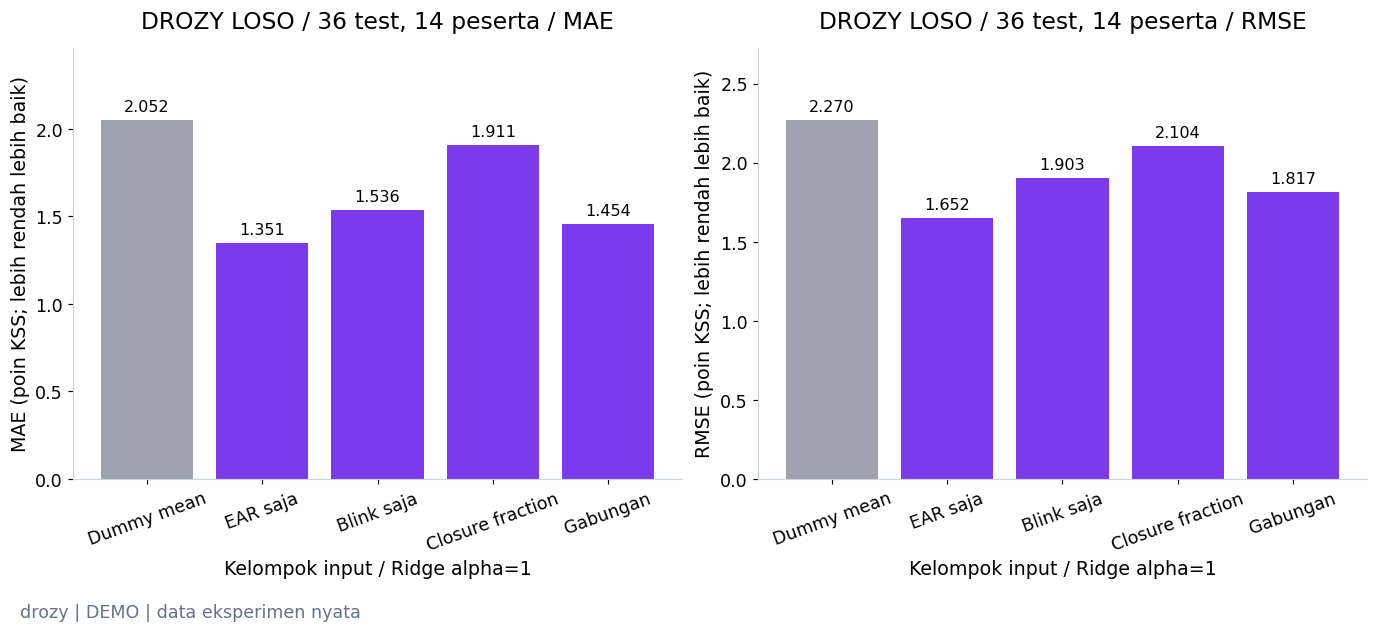

**Yang terlihat:** Lima metode dinilai pada fold/target/unit test yang sama; kelompok fitur masing-masing memuat 4/4/2/10 angka.

**Artinya:** Perbandingan menguji nilai informasi kelompok fitur dengan model dan protokol tetap, bukan membuktikan sebab kantuk.

**Perlu diingat:** Korpus kecil, threshold belum dikalibrasi, dan perbandingan eksploratif; tidak dilakukan tuning test.

*Sumber: `20261024T164441991561Z_seed42_1fbd3f` · REAL / CACHED; inference dihitung ulang.*

**Yang terlihat:** EAR-only MAE 1.351 versus combined 1.454 poin KSS. **Artinya:** menambahkan blink/closure features tidak otomatis memperbaiki prediksi; noise landmark, threshold dan kecilnya data dapat berpengaruh. **Perlu diingat:** kelompok model ini exploratory pada subjek yang telah dipakai pengembangan; hasil bukan alasan memilih model final berdasarkan test error. Ridge tidak dibatasi ke1–9, sehingga prediksi dapat keluar rentang KSS; nilai tidak di-clip untuk memperbaiki skor.

In [38]:
ablation_labels = {'dummy_mean':'Dummy mean','ear_only':'EAR saja','blink_only':'Blink saja','closure_only':'Closure fraction','combined':'Gabungan'}
display(pd.DataFrame(ablation_metrics['models']).T[['mae','rmse','subject_macro_mae']].round(4))
fig,axes = plt.subplots(1,2,figsize=(13,5.5),layout='constrained')
for axis,metric in zip(axes,['mae','rmse']):
    names = list(ablation_columns);values = [ablation_metrics['models'][name][metric] for name in names]
    bars = axis.bar([ablation_labels[name] for name in names],values,color=[COLORS['baseline']]+[COLORS['visual']]*4)
    axis.bar_label(bars,fmt='%.3f',padding=4,fontsize=11)
    axis.set(xlabel='Kelompok input / Ridge alpha=1',ylabel=metric.upper()+' (poin KSS; lebih rendah lebih baik)',
             title='DROZY LOSO / 36 test, 14 peserta / '+metric.upper(),ylim=(0,max(values)*1.2))
    axis.tick_params(axis='x',labelrotation=20)
ablation_book.show(fig,'drozy_feature_ablation',
                   'Lima metode dinilai pada fold/target/unit test yang sama; kelompok fitur masing-masing memuat 4/4/2/10 angka.',
                   'Perbandingan menguji nilai informasi kelompok fitur dengan model dan protokol tetap, bukan membuktikan sebab kantuk.',
                   'Korpus kecil, threshold belum dikalibrasi, dan perbandingan eksploratif; tidak dilakukan tuning test.')
np.testing.assert_allclose(ablation_metrics['models']['combined']['mae'],kss_metrics['models']['ridge_alpha1']['mae'],rtol=1e-12,atol=1e-12)
ablation_book.finish()
if RUN_MODE == 'FULL':
    ablation_run.complete(ablation_metrics,{'evaluation_rows':len(kss_data),'subjects':int(kss_data.subject_id.nunique()),
       'folds':len(kss_folds),'checkpoints':len(kss_folds)*len(ablation_columns),'subject_overlap':0,
       'test_level_targets_only':True,'no_test_hyperparameter_tuning':True},warning_records)
ear_mae = ablation_metrics['models']['ear_only']['mae']
combined_mae = ablation_metrics['models']['combined']['mae']
display(Markdown(f'**Yang terlihat:** EAR-only MAE {ear_mae:.3f} versus combined {combined_mae:.3f} poin KSS. '
    '**Artinya:** menambahkan blink/closure features tidak otomatis memperbaiki prediksi; noise landmark, threshold dan kecilnya data dapat berpengaruh. '
    '**Perlu diingat:** kelompok model ini exploratory pada subjek yang telah dipakai pengembangan; hasil bukan alasan memilih model final berdasarkan test error. '
    'Ridge tidak dibatasi ke1–9, sehingga prediksi dapat keluar rentang KSS; nilai tidak di-clip untuk memperbaiki skor.'))


### 2.6 RQ1 — Apakah urutan mata membantu memperkirakan KSS?

Ridge di atas meringkas seluruh test menjadi sepuluh angka. Ringkasan tersebut tidak menyimpan **urutan**: apakah perubahan mata muncul di awal atau akhir, dan bagaimana pola tetangga waktunya. **Temporal 1D CNN** adalah jaringan kecil yang menggeser filter sepanjang urutan untuk mempelajari pola lokal tersebut.

**Hipotesis yang diuji, bukan hasil yang dijanjikan:** informasi temporal mungkin membantu; dengan hanya 36 test dari 14 orang, jaringan juga mudah *overfit*, yaitu mempelajari kebetulan training yang tidak berlaku pada orang lain. Kita mempertahankan Ridge EAR-only, Ridge gabungan, dan Dummy sebagai pembanding pada **test dan fold yang persis sama**.

Dua representasi dibekukan sebelum melihat skor CNN:

| Varian | Satu langkah waktu | Tensor sebelum mask | Yang dipertahankan |
| :--- | :--- | :--- | :--- |
| A1 | 60 detik | `[36, 10, 5]` | Urutan sepuluh window, bukan hanya mean/std seluruh test |
| A2 | 1 detik dari EAR native | `[36, 600, 5]` | Perubahan lebih cepat; bukan memasukkan semua frame native |

Lima channel ialah EAR mean, EAR standard deviation, blink/minute, mean blink duration (ms), serta operational closure fraction. A2 memakai fungsi ekstraksi dan aturan event yang sama dengan baseline. **Tidak ada interpolasi** melewati data yang hilang. KSS tetap satu label per test, sehingga 600 posisi tidak berubah menjadi 600 label independen.

Seluruh analisis ini **exploratory**: peserta DROZY pernah digunakan dalam pengembangan terdahulu. Pemisahan orang mencegah leakage training, tetapi tidak menjadikan dataset ini holdout eksternal yang belum pernah dilihat. [Konfigurasi tetap](../../configs/visual_temporal.json).

In [39]:
from types import SimpleNamespace
from atc_fatigue.research.temporal_runs import train_temporal, load_temporal, replay_temporal
from atc_fatigue.research.temporal import CHANNELS
from atc_fatigue.research import temporal_plots as temporal_viz

temporal_config = json.loads(Path('configs/visual_temporal.json').read_text())
if RUN_MODE == 'FULL':
    temporal_path, temporal_metrics, temporal_predictions = train_temporal(drozy_run.path)
else:
    temporal_path, temporal_metrics, temporal_predictions = load_temporal(verify=True)
    for representation in temporal_config['representations_ms']:
        replay_temporal(temporal_path, representation, seed=42, fold=0)
temporal_manifest = json.loads((temporal_path/'run_manifest.json').read_text())
temporal_folds = json.loads((temporal_path/'folds.json').read_text())
temporal_arrays = np.load(temporal_path/'features/sequences.npz',allow_pickle=False)
temporal_tests = pd.read_csv(temporal_path/'test_manifest.csv',dtype={'subject_id':str})
temporal_origin = 'REAL / FRESH extraction + nested training' if RUN_MODE=='FULL' else 'REAL / CACHED; FRESH checkpoint inference fold0 kedua CNN'
# Presentation files get a separate directory; completed experiment artifacts remain untouched.
presentation_root = Path('runs/presentation') / os.environ.get('ATC_NOTEBOOK_SESSION',__import__('uuid').uuid4().hex)
temporal_view = SimpleNamespace(path=presentation_root/'drozy_temporal',manifest=temporal_manifest)
temporal_book = FigureBook(temporal_view,RUN_MODE,config)
display(Markdown(f"**{temporal_origin}** · run `{temporal_manifest['run_id']}` · target KSS · {temporal_metrics['tests']} test / {temporal_metrics['subjects']} peserta. Tidak ada download otomatis."))

**REAL / CACHED; FRESH checkpoint inference fold0 kedua CNN** · run `20261024T164444510164Z_seed42_47f50c` · target KSS · 36 test / 14 peserta. Tidak ada download otomatis.

#### 2.6.1 Periksa jam pengukuran sebelum mempelajari urutan

**Input:** timestamp dan EAR hasil landmark otomatis yang sudah diproses pada bagian sebelumnya. **Output:** interval antar-frame, jumlah gap, serta coverage bin. Sampling median sekitar 33 atau 67 ms tidak boleh dianggap sebagai satu FPS yang sama untuk seluruh test. Semua test berlangsung sekitar sepuluh menit.

Interval >150 ms dikeluarkan dari durasi teramati. Bin dengan coverage <80% tetap berada pada posisi waktunya tetapi ditandai invalid. Durasi blink yang tidak terdefinisi—misalnya tidak ada blink lengkap—tetap missing, bukan dianggap blink berdurasi nol.

,frames,median_interval_ms,max_gap_ms,gaps_over_150ms,valid_bins,bins
count,36.00,36.00,36.00,36.00,36.00,36.0
mean,13822.47,47.97,528.64,28.92,573.47,600.0
std,4616.91,16.98,253.84,45.30,44.72,0.0
min,7912.00,33.00,84.00,0.00,423.00,600.0
25%,8874.00,33.00,407.75,8.00,581.50,600.0
50%,17862.00,33.00,446.00,11.50,591.00,600.0
75%,17891.25,67.00,548.00,21.25,594.00,600.0
max,17922.00,67.00,1257.00,179.00,600.00,600.0


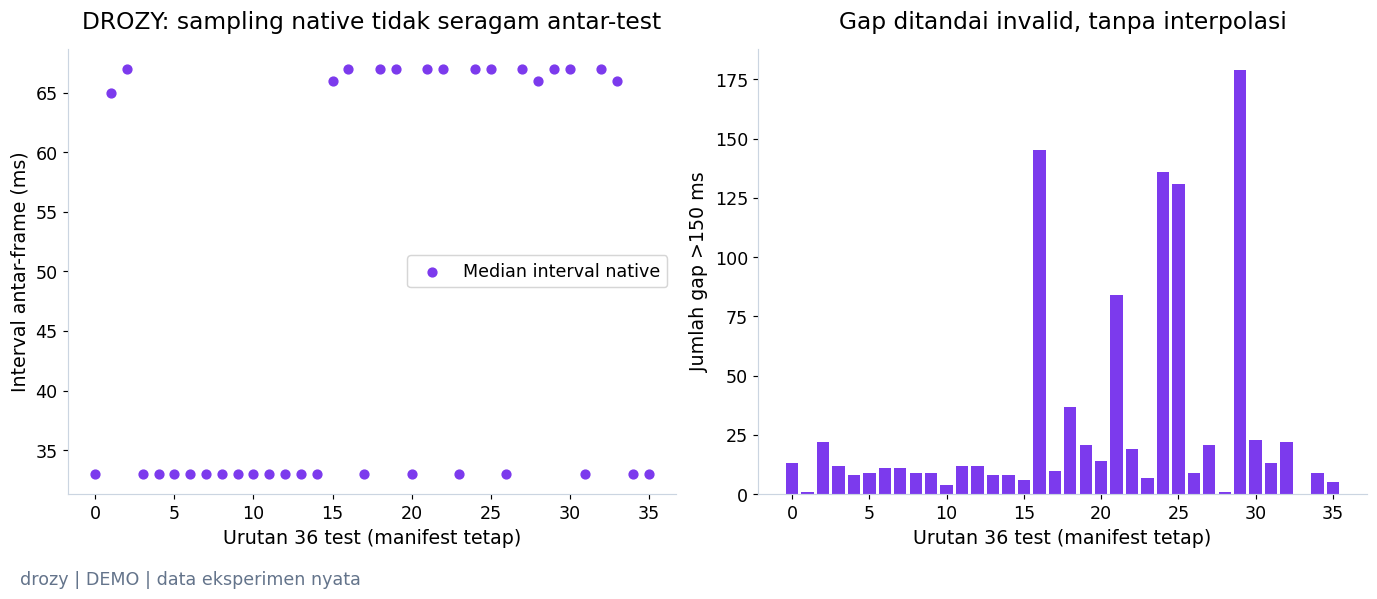

**Yang terlihat:** 1041 gap >150 ms ditemukan pada 36 test; gap terbesar 1257 ms.

**Artinya:** Waktu asli menentukan durasi dan coverage; model tidak menerima sampel hasil interpolasi untuk menutupi gap.

**Perlu diingat:** Finite EAR tidak menjamin landmark akurat. Perbedaan FPS berkaitan dengan test dan berpotensi menjadi confound.

*Sumber: `20261024T164444510164Z_seed42_47f50c` · REAL / CACHED; FRESH checkpoint inference fold0 kedua CNN.*

In [40]:
native_qc = pd.read_csv(temporal_path/'native_sampling_qc.csv')
display(native_qc[['frames','median_interval_ms','max_gap_ms','gaps_over_150ms','valid_bins','bins']].describe().round(2))
temporal_book.show(temporal_viz.sampling_figure(temporal_path),'native_sampling_audit',
    f"{int(native_qc.gaps_over_150ms.sum())} gap >150 ms ditemukan pada 36 test; gap terbesar {native_qc.max_gap_ms.max():.0f} ms.",
    'Waktu asli menentukan durasi dan coverage; model tidak menerima sampel hasil interpolasi untuk menutupi gap.',
    'Finite EAR tidak menjamin landmark akurat. Perbedaan FPS berkaitan dengan test dan berpotensi menjadi confound.',origin=temporal_origin)

#### 2.6.2 Lihat angka yang benar-benar masuk CNN

**Raw feature space** memakai satuan asli: EAR tanpa satuan, blink/minute, durasi ms, dan closure fraction 0–1. Nilai dengan satuan berbeda tidak langsung sebanding.

Pada setiap fold, median mengisi fitur yang tidak tersedia dan standardisasi membentuk nilai **z** relatif terhadap training. Posisi invalid/padding tetap nol setelah transformasi dan dikecualikan dari pooling. Lima *observed masks* menandai fitur yang benar-benar teramati, dan satu *valid-step mask* menandai posisi yang layak. Dengan demikian input jaringan menjadi **11 channel = 5 nilai + 5 mask fitur + 1 mask posisi**. Nilai imputasi tidak diklaim sebagai pengamatan nyata.

Tabel berikut memakai test holdout pertama pada fold0/seed42, sesuai checkpoint model. ID peserta, nama file, sesi, timestamp dan target **tidak menjadi channel prediktor**. Timestamp hanya menentukan urutan/coverage. Mask kualitas juga bisa membawa confound akuisisi; bukan ukuran fatigue.

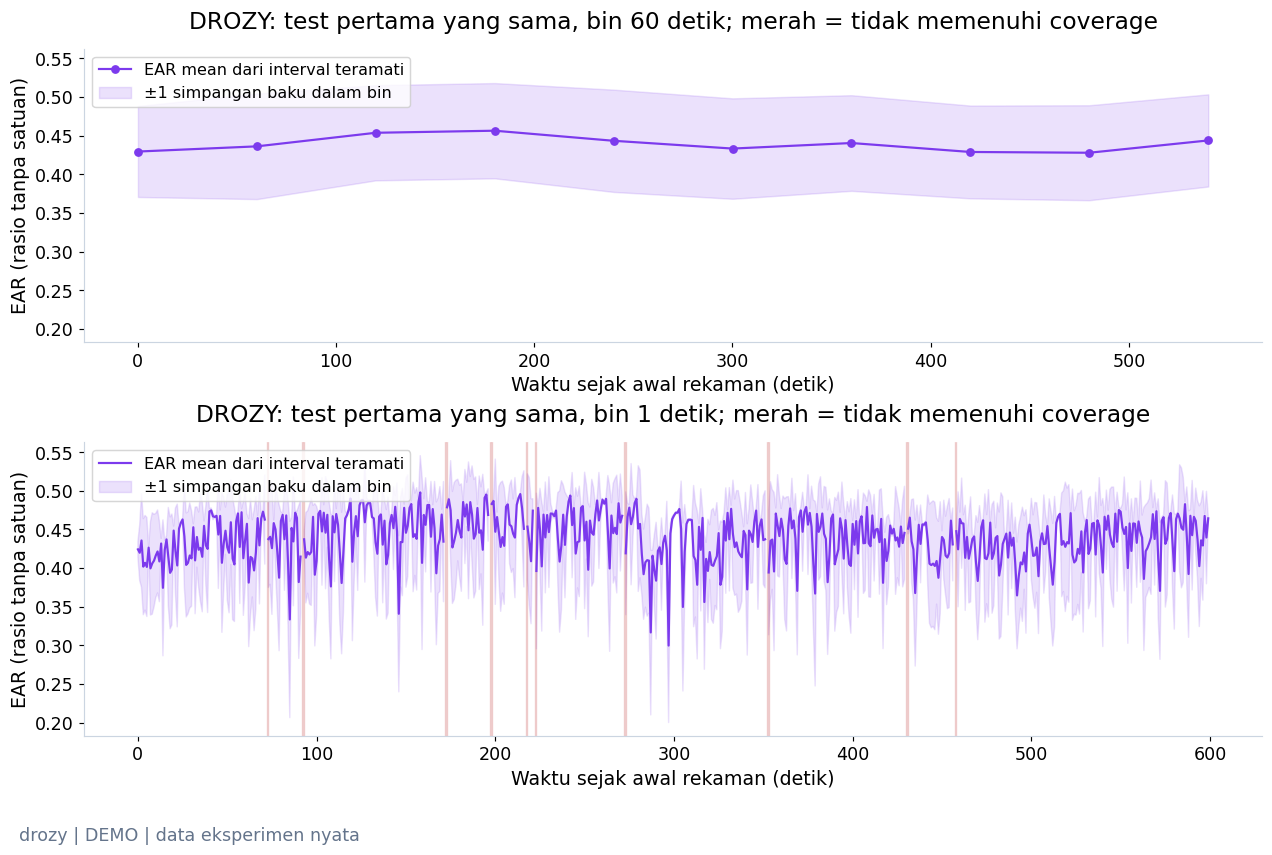

**Yang terlihat:** Kedua panel berasal dari test pertama yang sama; bin 1 detik memperlihatkan variasi yang diratakan oleh window 60 detik.

**Artinya:** Urutan posisi tetap dipertahankan, termasuk posisi invalid; ±std merangkum variasi dalam bin, bukan interval keyakinan.

**Perlu diingat:** A2 masih ringkasan per detik dan kehilangan urutan subdetik. Semua test dipakai offline sampai akhir.

*Sumber: `20261024T164444510164Z_seed42_47f50c` · REAL / CACHED; FRESH checkpoint inference fold0 kedua CNN.*

,Channel,Raw langkah pertama,Setelah imputasi/scaling,Observed mask
0,ear_mean,0.4242,0.5466,1.0
1,ear_std,0.0102,-0.8472,1.0
2,blink_rate_per_min,0.0000,-0.6798,1.0
3,blink_duration_mean_ms,NaN,-0.0471,0.0
4,perclos,0.0000,-0.1515,1.0


,ear_mean,ear_std,blink_rate_per_min,blink_duration_mean_ms,perclos,ear_mean_observed,ear_std_observed,blink_rate_per_min_observed,blink_duration_mean_ms_observed,perclos_observed,valid_step
0,0.547,-0.847,-0.680,-0.047,-0.152,1.0,1.0,1.0,0.0,1.0,1.0
1,0.491,-0.238,-0.680,-0.047,-0.152,1.0,1.0,1.0,0.0,1.0,1.0
2,0.691,0.334,-0.680,-0.047,-0.152,1.0,1.0,1.0,0.0,1.0,1.0
3,0.265,0.375,0.947,-1.467,-0.152,1.0,1.0,1.0,1.0,1.0,1.0
4,0.327,0.353,-0.680,-0.047,-0.152,1.0,1.0,1.0,0.0,1.0,1.0
5,0.260,0.420,0.947,-1.467,-0.152,1.0,1.0,1.0,1.0,1.0,1.0


,Representasi,X inner train,X inner validation,X outer test,y seluruh test,Missing raw cells
0,cnn_60s,"(25, 11, 10)","(8, 11, 10)","(3, 11, 10)","(36,)",80
1,cnn_1s,"(25, 11, 600)","(8, 11, 600)","(3, 11, 600)","(36,)",18277


,ear_mean,ear_std,blink_rate_per_min,blink_duration_mean_ms,perclos
0,0.358432,0.087285,60.0,65.0,0.0
1,0.377936,0.096253,60.0,100.0,0.0
2,0.368381,0.090773,60.0,69.0,0.0
3,0.433693,0.003345,0.0,NaN,0.0


In [41]:
temporal_book.show(temporal_viz.sequence_figure(temporal_path),'same_test_two_resolutions',
    'Kedua panel berasal dari test pertama yang sama; bin 1 detik memperlihatkan variasi yang diratakan oleh window 60 detik.',
    'Urutan posisi tetap dipertahankan, termasuk posisi invalid; ±std merangkum variasi dalam bin, bukan interval keyakinan.',
    'A2 masih ringkasan per detik dan kehilangan urutan subdetik. Semua test dipakai offline sampai akhir.',origin=temporal_origin)
raw_sequence,cnn_input,cnn_example_index = temporal_viz.transformed_sequence(temporal_path)
feature_preview = pd.DataFrame({'Channel':CHANNELS,'Raw langkah pertama':raw_sequence[0],
    'Setelah imputasi/scaling':cnn_input[0,:5],'Observed mask':cnn_input[0,5:10]})
display(feature_preview.round(4))
display(pd.DataFrame(cnn_input[:6],columns=CHANNELS+[name+'_observed' for name in CHANNELS]+['valid_step']).round(3))
first_nested_fold = temporal_folds[0]
display(pd.DataFrame([{'Representasi':name,'X inner train':str((len(first_nested_fold['inner_train']),11,temporal_arrays[name].shape[1])),
    'X inner validation':str((len(first_nested_fold['inner_validation']),11,temporal_arrays[name].shape[1])),
    'X outer test':str((len(first_nested_fold['outer_test']),11,temporal_arrays[name].shape[1])),
    'y seluruh test':str(temporal_arrays['y'].shape),'Missing raw cells':int(np.isnan(temporal_arrays[name]).sum())}
    for name in temporal_config['representations_ms']]))
display(pd.DataFrame(temporal_arrays['cnn_1s'][first_nested_fold['inner_train'][0],:4],columns=CHANNELS))

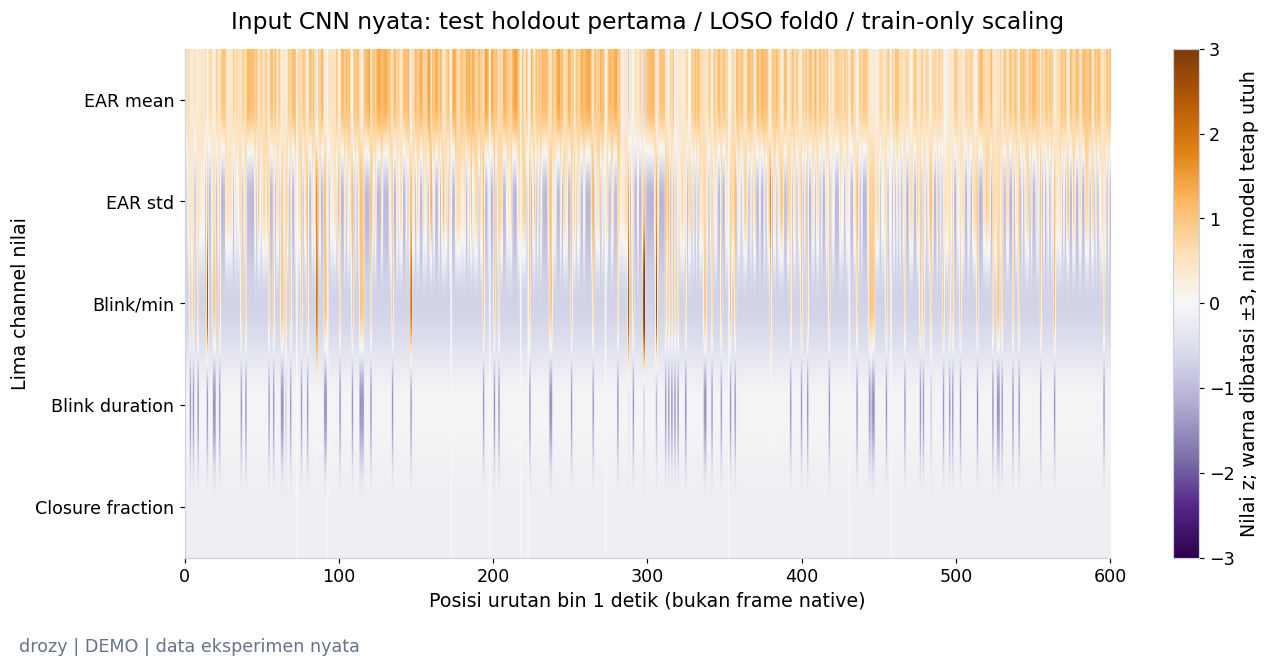

**Yang terlihat:** Heatmap menampilkan lima channel nilai dari tensor holdout yang sama dengan input checkpoint fold0/seed42.

**Artinya:** Warna membandingkan nilai relatif terhadap skala training; lima mask fitur dan satu mask posisi tetap masuk jaringan meski tidak dicampur ke colorbar z.

**Perlu diingat:** Warna saturasi ±3 hanya untuk keterbacaan. Nilai model tidak di-clip; imputasi dan kualitas landmark tetap merupakan keterbatasan.

*Sumber: `20261024T164444510164Z_seed42_47f50c` · REAL / CACHED; FRESH checkpoint inference fold0 kedua CNN.*

In [42]:
temporal_book.show(temporal_viz.input_figure(temporal_path),'actual_cnn_input',
    'Heatmap menampilkan lima channel nilai dari tensor holdout yang sama dengan input checkpoint fold0/seed42.',
    'Warna membandingkan nilai relatif terhadap skala training; lima mask fitur dan satu mask posisi tetap masuk jaringan meski tidak dicampur ke colorbar z.',
    'Warna saturasi ±3 hanya untuk keterbacaan. Nilai model tidak di-clip; imputasi dan kualitas landmark tetap merupakan keterbatasan.',origin=temporal_origin)

#### 2.6.3 Arsitektur kecil dan evaluasi dua lapis

**Conv1D** menggabungkan beberapa posisi tetangga. Dua filter kernel3 mempunyai receptive field lokal lima posisi (sekitar lima detik atau lima window), kemudian *masked mean pooling* merangkum posisi valid. Model ini tidak mempelajari seluruh ketergantungan sepuluh menit seperti recurrent network; desain sederhana membantu membatasi parameter.

**Outer LOSO:** satu dari 14 orang hanya untuk evaluasi. Di dalam 13 orang training, **tiga orang dipilih untuk inner validation**, tanpa melihat label; sepuluh lainnya untuk inner training. Median, skala fitur dan skala target tahap ini hanya dipelajari dari inner training.

**Early stopping** memilih epoch berdasarkan MAE yang memberi bobot sama pada tiga orang inner validation. Batas150 epoch, patience15, minimum10 epoch pengamatan, Adam lr0.001, weight decay0.001, dropout0.15. Arsitektur/learning rate tetap, tidak dicari berdasarkan skor outer test.

Sesudah epoch terpilih, model baru diinisialisasi dan dilatih ulang pada seluruh 13 orang outer training selama jumlah epoch tersebut. Preprocessing di-fit ulang hanya pada 13 orang ini. Barulah satu prediksi dibuat untuk setiap test peserta outer holdout. Seed42 adalah analisis utama;43 dan44 hanya mengukur sensitivitas, bukan memilih seed pemenang.

,Fold,Peserta inner train,Peserta inner validation,Peserta outer refit,Peserta outer test,Tests uji
0,0,10,3,13,1,3
1,1,10,3,13,1,2
2,2,10,3,13,1,3
3,3,10,3,13,1,1
4,4,10,3,13,1,2
5,5,10,3,13,1,3
6,6,10,3,13,1,3
7,7,10,3,13,1,3
8,8,10,3,13,1,3
9,9,10,3,13,1,3


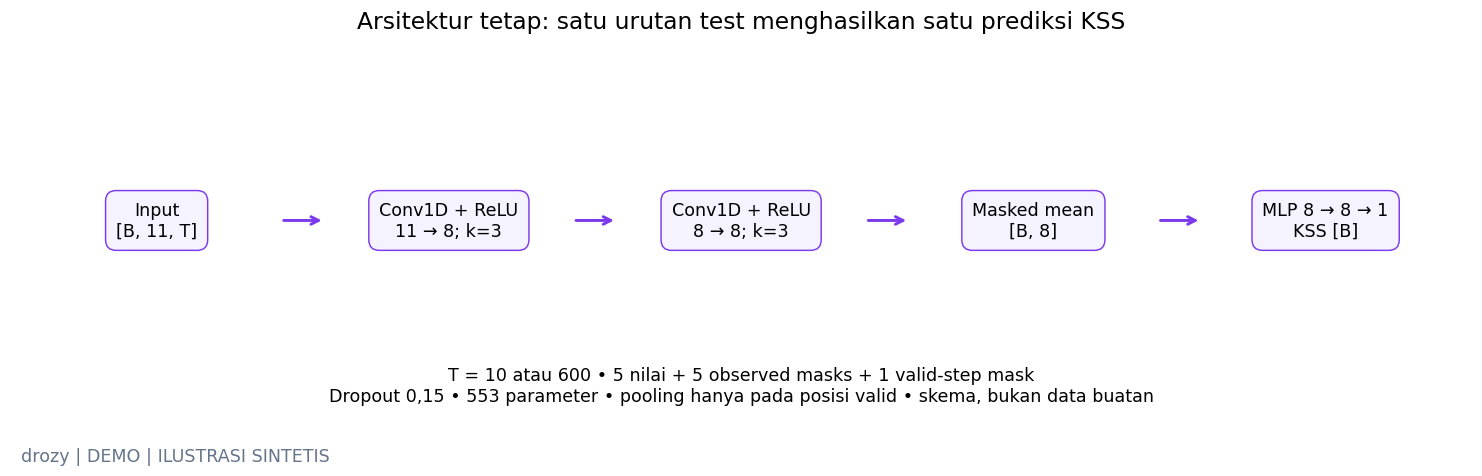

**Yang terlihat:** Jaringan mempunyai 553 parameter; output [B] berisi satu KSS untuk masing-masing test dalam batch.

**Artinya:** Mask menghalangi padding/posisi invalid menjadi bukti teramati dan mengecualikannya dari rata-rata temporal.

**Perlu diingat:** Diagram konseptual, bukan sinyal sintetis atau bukti peningkatan skor; 553 parameter tetap banyak untuk sekitar 30 test training.

*Sumber: `20261024T164444510164Z_seed42_47f50c` · SCHEMATIC / architecture actually trained.*

In [43]:
for nested_fold in temporal_folds:
    assert not set(nested_fold['inner_train_subjects']) & set(nested_fold['inner_validation_subjects'])
    assert nested_fold['outer_subject'] not in nested_fold['outer_train_subjects']
display(pd.DataFrame([{'Fold':f['fold'],'Peserta inner train':len(f['inner_train_subjects']),
    'Peserta inner validation':len(f['inner_validation_subjects']),'Peserta outer refit':len(f['outer_train_subjects']),
    'Peserta outer test':1,'Tests uji':len(f['outer_test'])} for f in temporal_folds]))
temporal_book.show(temporal_viz.architecture_figure(),'cnn_architecture',
    f"Jaringan mempunyai {temporal_metrics['neural_parameters']} parameter; output [B] berisi satu KSS untuk masing-masing test dalam batch.",
    'Mask menghalangi padding/posisi invalid menjadi bukti teramati dan mengecualikannya dari rata-rata temporal.',
    'Diagram konseptual, bukan sinyal sintetis atau bukti peningkatan skor; 553 parameter tetap banyak untuk sekitar 30 test training.',
    synthetic=True,origin='SCHEMATIC / architecture actually trained')

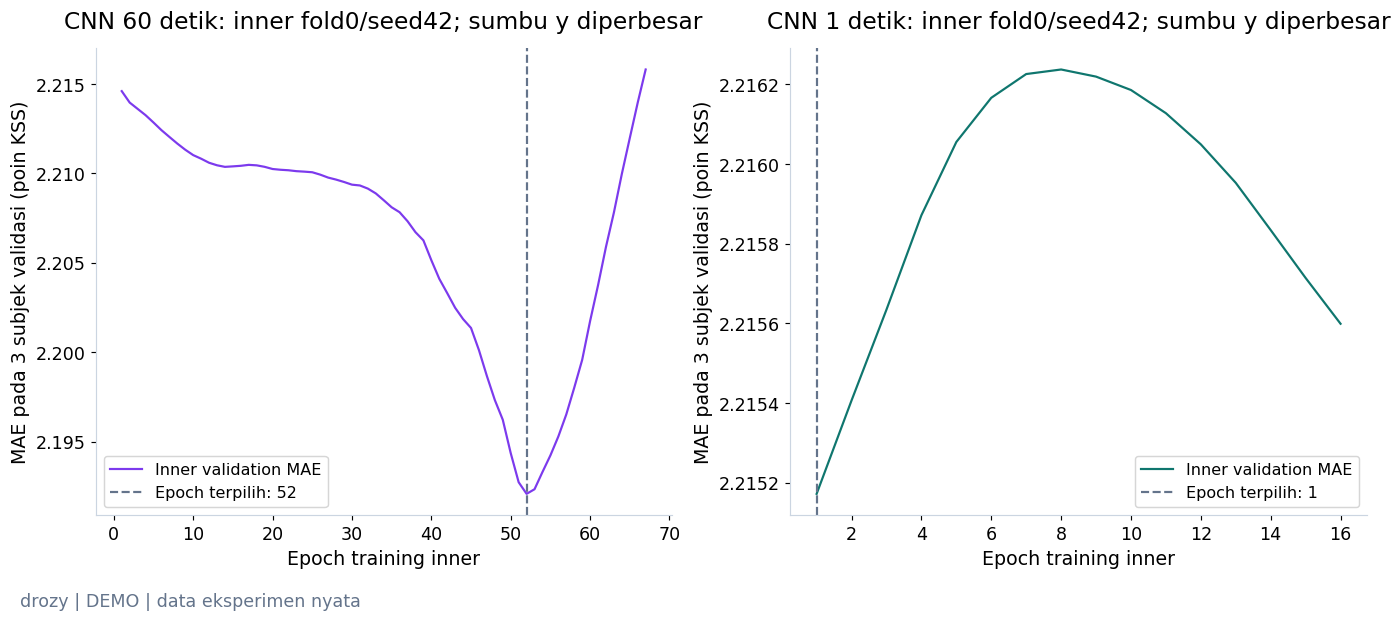

**Yang terlihat:** Kurva berasal dari fold0/seed42 yang dipilih deterministik; garis vertikal menunjukkan epoch dari inner validation.

**Artinya:** Ketika error validasi tidak membaik, menambah epoch tidak otomatis membantu orang yang tidak masuk training.

**Perlu diingat:** Sumbu y diperbesar untuk memperlihatkan perubahan kecil; bukan bukti perbaikan besar. Hanya satu contoh fold dan tiga orang validation; seluruh84log inner tersimpan.

*Sumber: `20261024T164444510164Z_seed42_47f50c` · REAL / CACHED; FRESH checkpoint inference fold0 kedua CNN.*

In [44]:
temporal_book.show(temporal_viz.learning_figure(temporal_path),'inner_validation_curves',
    'Kurva berasal dari fold0/seed42 yang dipilih deterministik; garis vertikal menunjukkan epoch dari inner validation.',
    'Ketika error validasi tidak membaik, menambah epoch tidak otomatis membantu orang yang tidak masuk training.',
    'Sumbu y diperbesar untuk memperlihatkan perubahan kecil; bukan bukti perbaikan besar. Hanya satu contoh fold dan tiga orang validation; seluruh84log inner tersimpan.',origin=temporal_origin)

#### 2.6.4 Hasil: apakah CNN mengalahkan Ridge pada orang baru?

MAE adalah rerata besar selisih prediksi dan KSS asli; RMSE memberi penalti lebih besar pada kesalahan ekstrem. Keduanya dalam poin KSS dan **lebih kecil lebih baik**. Subject-macro MAE memberi setiap orang bobot sama meskipun jumlah test berbeda.

Ridge dan Dummy dilatih ulang pada 36 test/14 fold yang sama, lalu dicek terhadap angka historis. Tidak ada pemotongan prediksi ke rentang1–9 untuk memperbaiki skor. Tabel seluruh seed dan grafik seed utama menjawab pertanyaan yang berbeda;108 prediksi dari tiga seed tetap berasal dari36 test yang sama.

,model,seed,mae,rmse,subject_macro_mae
0,cnn_1s,42,1.7771,2.1266,1.7438
1,cnn_1s,43,1.8864,2.0906,1.8937
2,cnn_1s,44,2.0239,2.3474,2.0082
3,cnn_60s,42,1.8704,2.1420,1.8857
4,cnn_60s,43,1.9658,2.1427,2.0002
5,cnn_60s,44,1.9999,2.2704,2.0254
6,dummy_mean,42,2.0519,2.2704,2.1082
7,ridge_combined,42,1.4544,1.8170,1.4405
8,ridge_ear,42,1.3508,1.6524,1.3571


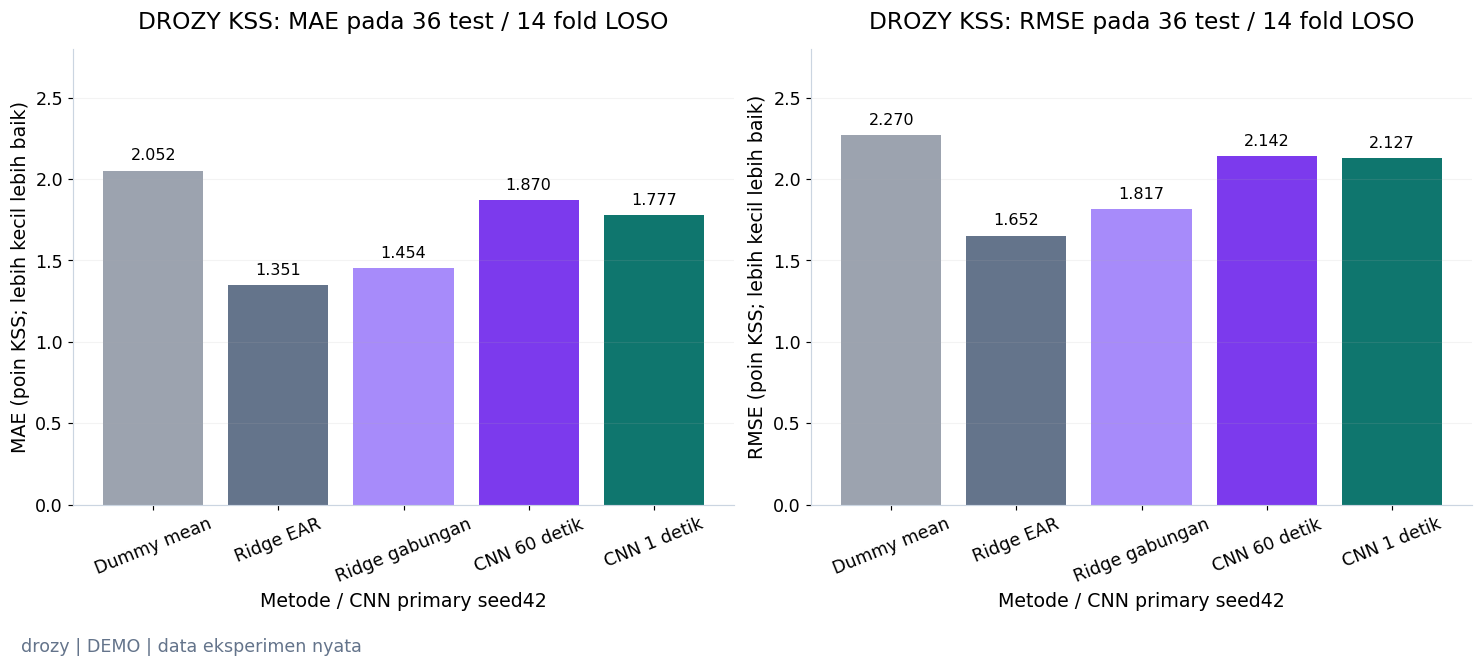

**Yang terlihat:** MAE seed42: Ridge EAR 1.351, CNN60s 1.870, CNN1s 1.777 poin.

**Artinya:** Pada protokol tetap ini CNN belum memperbaiki baseline EAR; tambahan resolusi/parameter tidak otomatis memperbaiki generalisasi.

**Perlu diingat:** LOSO mencegah overlap orang dalam fold, tetapi korpus kecil dan sudah dipakai pengembangan; ini feasibility study, bukan validasi eksternal.

*Sumber: `20261024T164444510164Z_seed42_47f50c` · REAL / CACHED; FRESH checkpoint inference fold0 kedua CNN.*

In [45]:
temporal_scores = pd.DataFrame(temporal_metrics['models'])
primary_scores = temporal_scores[temporal_scores.seed.eq(42)].set_index('model')
np.testing.assert_allclose(primary_scores.loc['ridge_ear','mae'],ablation_metrics['models']['ear_only']['mae'],rtol=1e-12,atol=1e-12)
np.testing.assert_allclose(primary_scores.loc['ridge_combined','mae'],kss_metrics['models']['ridge_alpha1']['mae'],rtol=1e-12,atol=1e-12)
display(temporal_scores[['model','seed','mae','rmse','subject_macro_mae']].round(4))
temporal_book.show(temporal_viz.comparison_figure(temporal_metrics),'ridge_vs_temporal_cnn',
    f"MAE seed42: Ridge EAR {primary_scores.loc['ridge_ear','mae']:.3f}, CNN60s {primary_scores.loc['cnn_60s','mae']:.3f}, CNN1s {primary_scores.loc['cnn_1s','mae']:.3f} poin.",
    'Pada protokol tetap ini CNN belum memperbaiki baseline EAR; tambahan resolusi/parameter tidak otomatis memperbaiki generalisasi.',
    'LOSO mencegah overlap orang dalam fold, tetapi korpus kecil dan sudah dipakai pengembangan; ini feasibility study, bukan validasi eksternal.',origin=temporal_origin)

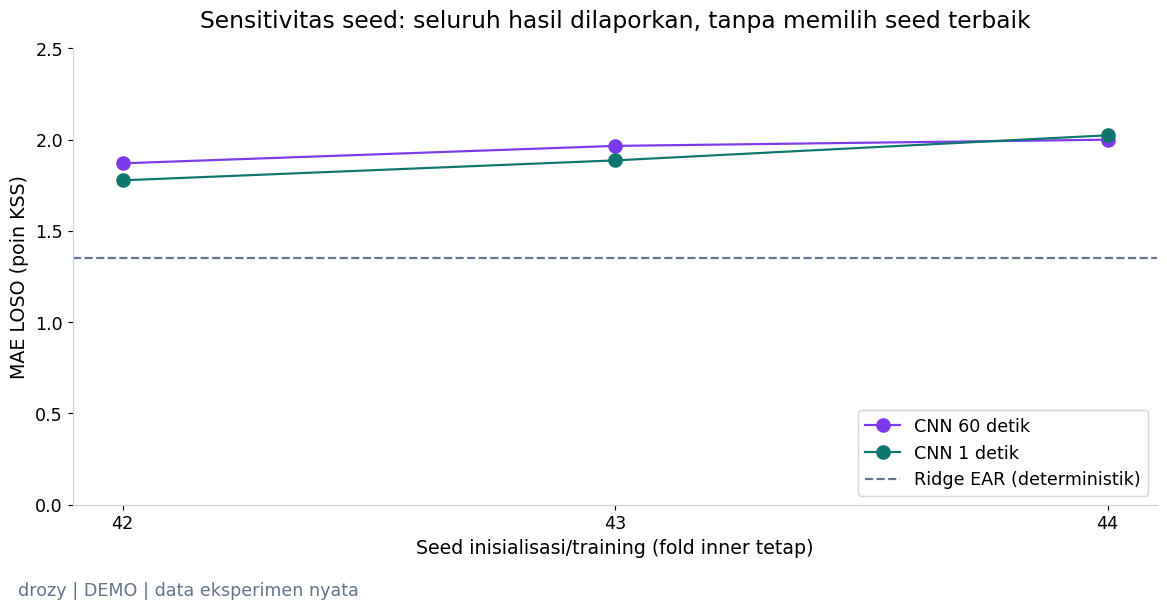

**Yang terlihat:** Ketiga seed yang ditetapkan sebelum eksperimen ditampilkan, dengan fold inner yang identik antar-seed.

**Artinya:** Variasi inisialisasi/training menunjukkan bahwa satu skor jaringan dapat tidak stabil pada dataset kecil.

**Perlu diingat:** Tiga seed bukan tiga dataset independen; tidak memilih seed berdasarkan outer test dan tidak menambah jumlah peserta.

*Sumber: `20261024T164444510164Z_seed42_47f50c` · REAL / CACHED; FRESH checkpoint inference fold0 kedua CNN.*

mae                            rmse                        
           mean     std     min     max    mean     std     min     max
model                                                                  
cnn_1s   1.8958  0.1236  1.7771  2.0239  2.1882  0.1390  2.0906  2.3474
cnn_60s  1.9454  0.0671  1.8704  1.9999  2.1850  0.0739  2.1420  2.2704

,Final CNN checkpoints,Inner fits,Parameter per CNN,Median selected epochs,Total extraction/training/evaluation seconds,CPU threads,GPU digunakan,PyTorch worker,Semua checkpoint replay
0,84,84,553,70.5,71.6,2,False,1.13.1+cu116,True


In [46]:
temporal_book.show(temporal_viz.seed_figure(temporal_metrics),'cnn_seed_sensitivity',
    'Ketiga seed yang ditetapkan sebelum eksperimen ditampilkan, dengan fold inner yang identik antar-seed.',
    'Variasi inisialisasi/training menunjukkan bahwa satu skor jaringan dapat tidak stabil pada dataset kecil.',
    'Tiga seed bukan tiga dataset independen; tidak memilih seed berdasarkan outer test dan tidak menambah jumlah peserta.',origin=temporal_origin)
display(temporal_scores[temporal_scores.model.str.startswith('cnn')].groupby('model')[['mae','rmse']].agg(['mean','std','min','max']).round(4))
training_info = pd.DataFrame(temporal_metrics['training'])
display(pd.DataFrame([{'Final CNN checkpoints':len(training_info),'Inner fits':len(training_info),
    'Parameter per CNN':temporal_metrics['neural_parameters'],'Median selected epochs':training_info.selected_epochs.median(),
    'Total extraction/training/evaluation seconds':round(temporal_metrics['seconds'],1),
    'CPU threads':temporal_metrics['environment']['threads'],'GPU digunakan':False,
    'PyTorch worker':temporal_metrics['environment']['torch'],'Semua checkpoint replay':training_info.checkpoint_replay_verified.all()}]))

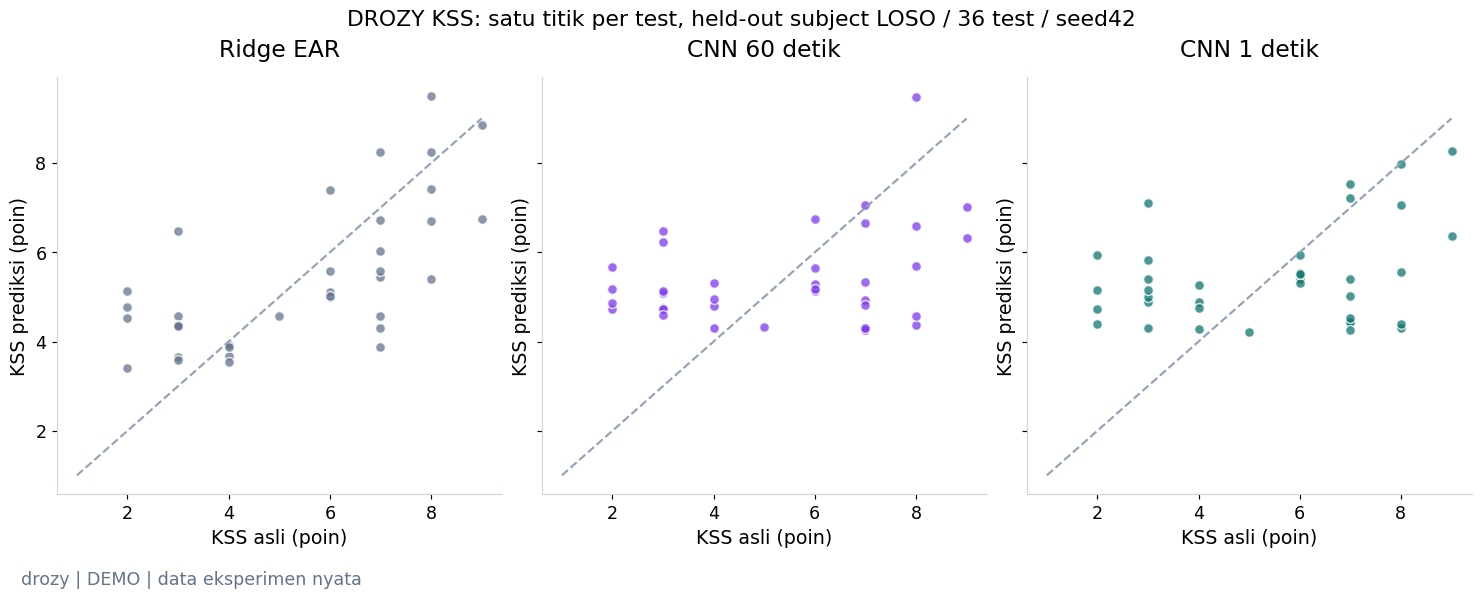

**Yang terlihat:** Seluruh36test ditampilkan pada setiap model; titik jauh dari diagonal adalah kesalahan yang benar-benar terjadi.

**Artinya:** Plot memperlihatkan apakah prediksi menyusut ke rerata atau melewatkan KSS tinggi, yang dapat tertutup oleh skor agregat.

**Perlu diingat:** Target subjektif, test berulang dan landmark otomatis membatasi interpretasi; ini sleepiness offline, bukan deteksi fatigue ATC.

*Sumber: `20261024T164444510164Z_seed42_47f50c` · REAL / CACHED; FRESH checkpoint inference fold0 kedua CNN.*

model,sample_id,truth,ridge_ear,ridge_combined,cnn_60s,cnn_1s
0,drozy_test_1-1,3.0,3.653,3.586,4.746,5.396


Kasus dipilih deterministik: test pertama menurut ID dan test pertama dengan error CNN1s≥2poin jika ada. Pilihan ini memperlihatkan kegagalan, bukan estimasi frekuensi kegagalan; seluruh36prediksi tetap ditampilkan pada scatter dan file prediksi.

In [47]:
temporal_book.show(temporal_viz.prediction_figure(temporal_predictions),'actual_vs_predicted_temporal',
    'Seluruh36test ditampilkan pada setiap model; titik jauh dari diagonal adalah kesalahan yang benar-benar terjadi.',
    'Plot memperlihatkan apakah prediksi menyusut ke rerata atau melewatkan KSS tinggi, yang dapat tertutup oleh skor agregat.',
    'Target subjektif, test berulang dan landmark otomatis membatasi interpretasi; ini sleepiness offline, bukan deteksi fatigue ATC.',origin=temporal_origin)
# Kasus pertama dan kegagalan pertama >=2 poin, terurut ID; tidak dipilih karena model unggul.
prediction_walkthrough = temporal_predictions[temporal_predictions.seed.eq(42)].pivot(
    index=['sample_id','truth'],columns='model',values='prediction').reset_index().sort_values('sample_id')
walkthrough_ids = [prediction_walkthrough.sample_id.iloc[0]]
large_errors = prediction_walkthrough[(prediction_walkthrough.cnn_1s-prediction_walkthrough.truth).abs().ge(2)]
if len(large_errors):
    walkthrough_ids.append(large_errors.sample_id.iloc[0])
display(prediction_walkthrough[prediction_walkthrough.sample_id.isin(walkthrough_ids)]
        [['sample_id','truth','ridge_ear','ridge_combined','cnn_60s','cnn_1s']].round(3))
display(Markdown('Kasus dipilih deterministik: test pertama menurut ID dan test pertama dengan error CNN1s≥2poin jika ada. '
    'Pilihan ini memperlihatkan kegagalan, bukan estimasi frekuensi kegagalan; seluruh36prediksi tetap ditampilkan pada scatter dan file prediksi.'))

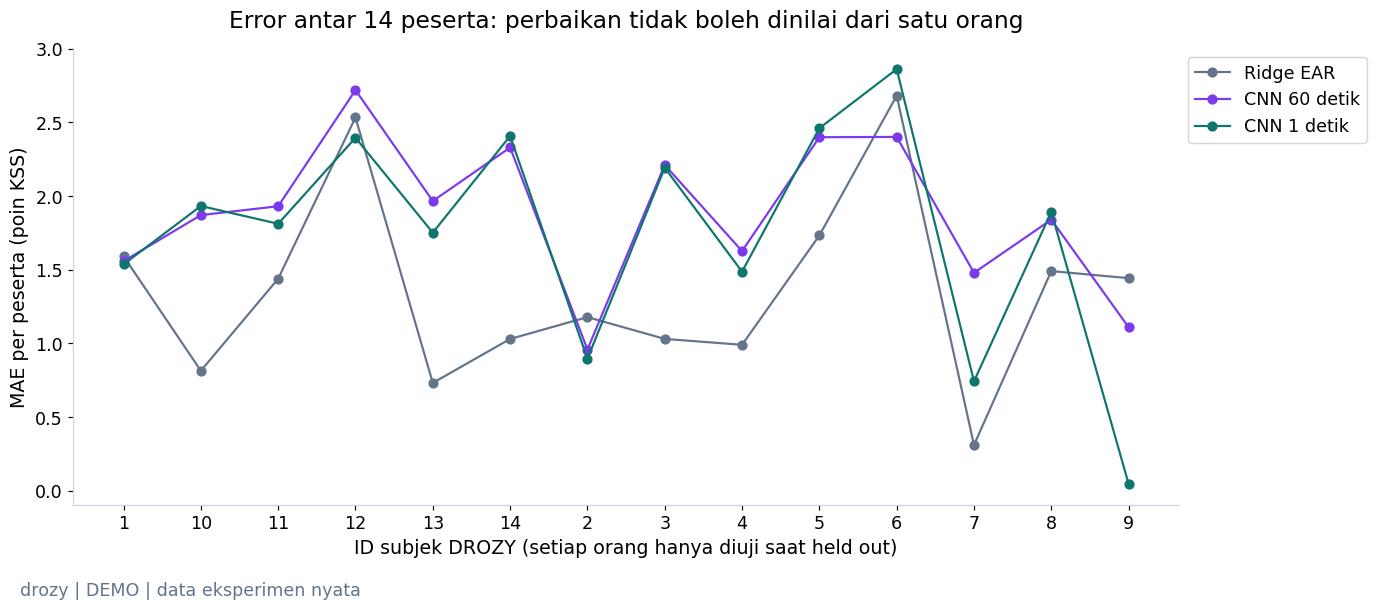

**Yang terlihat:** Error diringkas per14orang; setiap titik hanya memakai prediksi saat orang tersebut ditahan dari training.

**Artinya:** Pembaca dapat melihat apakah perubahan skor konsisten antarorang atau didominasi beberapa peserta.

**Perlu diingat:** Fold LOSO berbagi sebagian besar peserta training sehingga error fold tidak sepenuhnya independen.

*Sumber: `20261024T164444510164Z_seed42_47f50c` · REAL / CACHED; FRESH checkpoint inference fold0 kedua CNN.*

,model,baseline,subjects,subject_macro_mae_difference,descriptive_cluster_bootstrap_95,draws,seed,unit,caveat
0,cnn_60s,ridge_ear,14,0.528591,"[0.22290995895543955, 0.798481647035142]",2000,42,subject; negative difference favors CNN,14 people; overlapping LOSO training sets; exp...
1,cnn_1s,ridge_ear,14,0.386778,"[-0.0007800366180131427, 0.7110037632925321]",2000,42,subject; negative difference favors CNN,14 people; overlapping LOSO training sets; exp...


In [48]:
subject_error_figure, temporal_subject_errors = temporal_viz.subject_figure(temporal_predictions)
temporal_book.show(subject_error_figure,'subject_wise_temporal_errors',
    'Error diringkas per14orang; setiap titik hanya memakai prediksi saat orang tersebut ditahan dari training.',
    'Pembaca dapat melihat apakah perubahan skor konsisten antarorang atau didominasi beberapa peserta.',
    'Fold LOSO berbagi sebagian besar peserta training sehingga error fold tidak sepenuhnya independen.',origin=temporal_origin)
display(pd.DataFrame(temporal_metrics['bootstrap']))

#### 2.6.5 Makna, ketidakpastian, dan keputusan penelitian

Bootstrap di atas mengambil ulang **peserta**, bukan window atau klip. Selisihnya ialah subject-macro MAE CNN minus Ridge EAR; nilai positif berarti error CNN lebih besar. Interval tersebut deskriptif:14 orang sedikit dan model antar-fold berbagi training. Ini tidak dipakai untuk klaim signifikansi atau memilih model berdasarkan test.

**Kesimpulan RQ1:** jaringan temporal dapat dilatih, disimpan dan dievaluasi tanpa overlap orang, tetapi konfigurasi kecil yang dibekukan ini **belum mendukung peningkatan terhadap Ridge EAR-only**. Mengapa? Kemungkinan yang perlu diuji terpisah meliputi jumlah label terlalu sedikit, ketidakakuratan landmark, perubahan sampling, mask kualitas yang membawa confound, serta pooling yang membatasi pola jangka panjang. Hasil ini tidak membuktikan semua CNN gagal dan tidak membenarkan pencarian arsitektur berulang pada test yang sama.

**Batas A2:** bin1 detik mempertahankan urutan antardetik, tetapi bukan seluruh dinamika frame/subdetik. Event blink dihitung dari timestamp native sebelum diringkas. Tidak ada data palsu di gap; imputasi hanya untuk kebutuhan numerik model dengan mask eksplisit. Penyebab missingness dapat berkaitan dengan kondisi pengukuran dan perlu audit lanjutan.

**Reproduksi:** `.venv` melakukan persiapan/evaluasi; training dijalankan sebagai subprocess pada interpreter PyTorch yang sudah tersedia. Set `ATC_TORCH_PYTHON` bila perlu. Environment tidak dicampur dan paket shared tidak diganti. CPU dua thread cukup; GPU tidak digunakan untuk dataset sekecil ini. Model, log inner, normalisasi, fold, konfigurasi, prediksi dan checksum disimpan pada run baru.

In [49]:
temporal_book.finish()
display(Markdown(f"Artifact lokal: `{temporal_path}`. Status: **{temporal_manifest['status']}**. "
    "DEMO memverifikasi checksum dan menjalankan inference ulang fold0 keduaCNN; FULL membuat eksperimen baru. "
    "Anotasi/landmark dan checkpoint tetap lokal. [Laporan temporal](../../reports/visual_temporal_research.md)."))

Artifact lokal: `runs/drozy_temporal/20261024T164444510164Z_seed42_47f50c`. Status: **completed**. DEMO memverifikasi checksum dan menjalankan inference ulang fold0 keduaCNN; FULL membuat eksperimen baru. Anotasi/landmark dan checkpoint tetap lokal. [Laporan temporal](../../reports/visual_temporal_research.md).

## 3. Interpretasi dan hubungan ke riset ATC

MRL menunjukkan kemampuan mengenali keadaan mata pada gambar. DROZY menunjukkan perhitungan fitur temporal serta hubungan prediktif awal terhadap sleepiness KSS. Tidak ada model yang mengubah dua label tersebut menjadi fatigue ATC.

Landmark otomatis dan threshold belum tervalidasi luas; whole-test aggregation belum cocok untuk peringatan dini. Validasi berikutnya membutuhkan anotasi event/closure, protokol waktu label, video berkualitas, dan data ATC yang sah. Kita tidak membuat pasangan MRL–DROZY atau ATCOSIM–DROZY untuk memperoleh skor gabungan.

### 3.1 Provenance dan reproduksi

MRL dan DROZY memiliki run, schema, model, split/fold, prediksi dan grafik masing-masing. Model disimpan dengan urutan fitur dan reload diverifikasi. KSS mempertahankan 36 original test rows, bukan 360 observasi berlabel independen.

In [50]:
drozy_book.finish()
if RUN_MODE=='FULL':
    drozy_run.complete(kss_metrics,{'evaluation_rows':len(kss_data),'subjects':int(kss_data.subject_id.nunique()),
                                   'windows':len(drozy_windows),'usable_windows':int(drozy_windows.video_available.sum()),
                                   'subject_overlap':0,'whole_test_offline':True},warning_records)
display(pd.DataFrame([{'Eksperimen':'MRL eye state','Run ID':mrl_run.manifest['run_id'],'Mode':RUN_MODE,
                       'Artifact':str(mrl_run.path.relative_to(ROOT))},
                      {'Eksperimen':'DROZY KSS','Run ID':drozy_run.manifest['run_id'],'Mode':RUN_MODE,
                       'Artifact':str(drozy_run.path.relative_to(ROOT))}]))

,Eksperimen,Run ID,Mode,Artifact
0,MRL eye state,20261024T164355883823Z_seed42_91ed89,DEMO,runs/mrl_eye_state/20261024T164355883823Z_seed...
1,DROZY KSS,20261024T164409996849Z_seed42_ae9238,DEMO,runs/drozy_kss/20261024T164409996849Z_seed42_a...


## 4. BAGIAN C — CogBeacon: audit cognitive fatigue tanpa memaksakan classifier

**Research question:** apakah event self-report dapat dipetakan menjadi label fatigue per window visual?
[Repository sumber](https://github.com/MikeMpapa/CogBeacon-MultiModal_Dataset_for_Cognitive_Fatigue) dan
[publikasi](https://www.mdpi.com/2227-7080/7/2/46) menjelaskan tugas kognitif dengan landmark wajah,
EEG, performa respons, dan tombol ketika peserta merasa kesulitan mengikuti tugas.
Kita mengunduh hanya landmark, laporan tombol, dan performa; **EEG tidak diunduh atau dianalisis**.

| Pertanyaan audit | Temuan dan konsekuensi |
| :--- | :--- |
| Unit anotasi | CSV menyimpan hitungan tombol kumulatif per ronde tugas; selisihnya adalah jumlah tekan baru per ronde |
| Label binary tiap frame? | Tidak. Tidak ada tombol tidak membuktikan tidak fatigue; tidak ada aturan label window tervalidasi |
| Waktu | Nama file berisi indeks frame lokal yang reset per ronde; belum ada timeline absolut terverifikasi |
| Performa | `Time` adalah waktu respons tugas, bukan timestamp sinkronisasi video |
| Resolusi visual | Nominal 2 FPS; tidak cukup untuk klaim blink duration/PERCLOS |
| Identitas | Akhiran `b` menunjukkan hari kedua orang yang sama; tidak boleh dipisah menjadi orang baru |
| Lisensi | LICENSE MIT menyebut software; paper menyatakan persetujuan berbagi data/IRB. Tidak dianggap izin otomatis redistribusi biometrik |
| Status supervisi | Analisis deskriptif; tidak melatih classifier dan tidak mengarang fatigue score |

**Input → output:** NPZ landmark dan CSV asli → validasi bentuk/finite values serta alignment ronde → ringkasan jumlah frame dan event.
Koordinat wajah tidak ditampilkan atau dikomit. Confound meliputi jenis stimulus, variasi tugas, pembelajaran dan hari pengukuran.

In [51]:
from atc_fatigue.research.data import audit_cogbeacon, cumulative_event_increments
cog_root = Path(config['additional_datasets']['cogbeacon_root'])
if RUN_MODE == 'FULL' and not cog_root.exists():
    raise FileNotFoundError('Arsip CogBeacon belum dipersiapkan; lihat docs/datasets.md. Tidak ada download otomatis.')
if RUN_MODE == 'FULL':
    cog_sessions,cog_rounds,cog_summary = audit_cogbeacon(cog_root)
    cog_rights = {'source':'https://github.com/MikeMpapa/CogBeacon-MultiModal_Dataset_for_Cognitive_Fatigue',
                  'variant':'current GitHub archives; face_keypoints + fatigue_self_report + user_performance',
                  'rights':'MIT software; study data-sharing approval reported; local analysis, public aggregate only'}
    cog_run = Run.create('cogbeacon_audit','02_visual_analysis.ipynb',config,cog_sessions,
                         'native-round-event-audit-v1',cog_rights,
                         ['event counts are not validated binary window fatigue labels','2 FPS cannot validate blink duration/PERCLOS',
                          'round-local indices lack verified absolute timestamps','77 sessions/20 numeric IDs differ from documented76/19'])
    cog_run.features(cog_sessions,['rounds','button_presses','landmark_records'],'native-round-event-audit-v1')
    cog_rounds.to_parquet(cog_run.file('features/rounds.parquet'),index=False)
    cog_run.write('source_audit.json',cog_summary)
    from atc_fatigue.utils.runtime import checksum
    cog_run.write('source_archives.json',{str(path):checksum(path) for path in sorted(cog_root.parent.glob('*.tar.xz'))})
else:
    cog_run,cog_metrics = cached_run('cogbeacon_audit',config)
    cog_sessions = pd.read_parquet(cog_run.path/'features/features.parquet')
    cog_rounds = pd.read_parquet(cog_run.path/'features/rounds.parquet')
    cog_summary = json.loads((cog_run.path/'source_audit.json').read_text())
cog_book = FigureBook(cog_run,RUN_MODE,config)
run_card(cog_run,RUN_MODE,'N/A — event counts bukan label fatigue tervalidasi')
display(pd.DataFrame([cog_summary]).drop(columns='issues'))
display(Markdown(f'**Perbedaan provenance:** arsip saat ini memiliki **{len(cog_sessions)} sesi / {cog_sessions.subject_id.nunique()} ID numerik**; '
                 'paper/README menyebut **76 sesi / 19 peserta**. ID numerik tidak otomatis jumlah peserta terverifikasi. '
                 'Seluruh sesi dipertahankan; verifikasi penulis diperlukan sebelum supervisi.'))

| Identitas run | Nilai |
| :--- | :--- |
| Mode | **DEMO / CACHED — hasil FULL terverifikasi; inference checkpoint dihitung ulang, tanpa training baru** |
| Run ID sumber | `20261024T164613827795Z_seed42_be9da7` |
| Status eksperimen sumber | completed |
| Dataset / target | cogbeacon / tidak ada label fatigue |
| Sampel / subjek | 77 / 20 |
| Unit evaluasi | task_session; repeated within source ID |
| Hasil utama | N/A — event counts bukan label fatigue tervalidasi |

,observed_sessions,observed_numeric_source_ids,documented_sessions,documented_participants,rounds,button_presses,event_rounds,landmark_records,invalid_landmark_records,nominal_landmark_fps,verified_absolute_timestamps,supervised_fatigue_labels_validated,count_discrepancy
0,77,20,76,19,6972,79,79,68118,0,2,False,False,current archive has 77 sessions / 20 numeric I...


**Perbedaan provenance:** arsip saat ini memiliki **77 sesi / 20 ID numerik**; paper/README menyebut **76 sesi / 19 peserta**. ID numerik tidak otomatis jumlah peserta terverifikasi. Seluruh sesi dipertahankan; verifikasi penulis diperlukan sebelum supervisi.

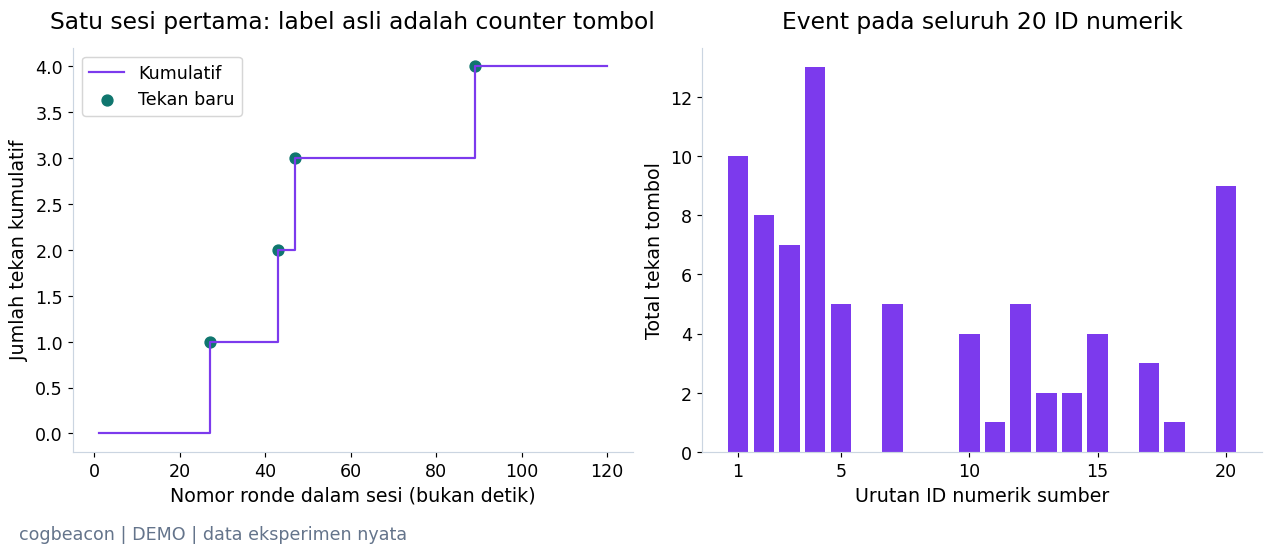

**Yang terlihat:** 79 tekan tercatat pada 6972 ronde; grafik kiri memakai hitungan asli sesi pertama (source/cache ditandai).

**Artinya:** Counter perlu di-difference untuk mengetahui ronde dengan tekan baru; nilainya bukan derajat fatigue kontinu.

**Perlu diingat:** Tidak ada tekan bukan label non-fatigue; durasi sebelum/sesudah tekan yang boleh dilabeli belum tervalidasi.

*Sumber: `20261024T164613827795Z_seed42_be9da7` · CACHED native counts + FRESH increments + CACHED audit seluruh arsip.*

In [52]:
cog_example = cog_sessions.sort_values('session_id').iloc[0]
native_counts = (np.loadtxt(cog_root/'fatigue_self_report'/f'{cog_example.session_id}.csv',ndmin=1) if USE_SOURCE_MEDIA else
                 cog_rounds[cog_rounds.session_id.eq(cog_example.session_id)].sort_values('round_id').cumulative_reports.to_numpy())
native_increments = cumulative_event_increments(native_counts)
example_rounds = cog_rounds[cog_rounds.session_id.eq(cog_example.session_id)].sort_values('round_id')
np.testing.assert_array_equal(native_increments,example_rounds.event_increments)
fig,axes = plt.subplots(1,2,figsize=(12,4.8),layout='constrained')
axes[0].step(example_rounds['round_id'],native_counts,where='post',color=COLORS['visual'],label='Kumulatif')
pressed = native_increments>0
axes[0].scatter(example_rounds.loc[pressed,'round_id'],native_counts[pressed],color=COLORS['fusion'],s=55,label='Tekan baru')
axes[0].set(xlabel='Nomor ronde dalam sesi (bukan detik)',ylabel='Jumlah tekan kumulatif',title='Satu sesi pertama: label asli adalah counter tombol')
axes[0].legend(loc='upper left')
per_subject = cog_sessions.groupby('subject_id').button_presses.sum().sort_index(key=lambda x:x.astype(int))
axes[1].bar(np.arange(1,len(per_subject)+1),per_subject.values,color=COLORS['visual'])
axes[1].set(xlabel='Urutan ID numerik sumber',ylabel='Total tekan tombol',title=f'Event pada seluruh {len(per_subject)} ID numerik',xticks=[1,5,10,15,20])
cog_book.show(fig,'cog_native_event_counts',
              f'{cog_summary["button_presses"]} tekan tercatat pada {cog_summary["rounds"]} ronde; grafik kiri memakai hitungan asli sesi pertama (source/cache ditandai).',
              'Counter perlu di-difference untuk mengetahui ronde dengan tekan baru; nilainya bukan derajat fatigue kontinu.',
              'Tidak ada tekan bukan label non-fatigue; durasi sebelum/sesudah tekan yang boleh dilabeli belum tervalidasi.',origin=('FRESH CSV example + ' if USE_SOURCE_MEDIA else 'CACHED native counts + FRESH increments + ')+('FRESH audit seluruh arsip' if RUN_MODE=='FULL' else 'CACHED audit seluruh arsip'))

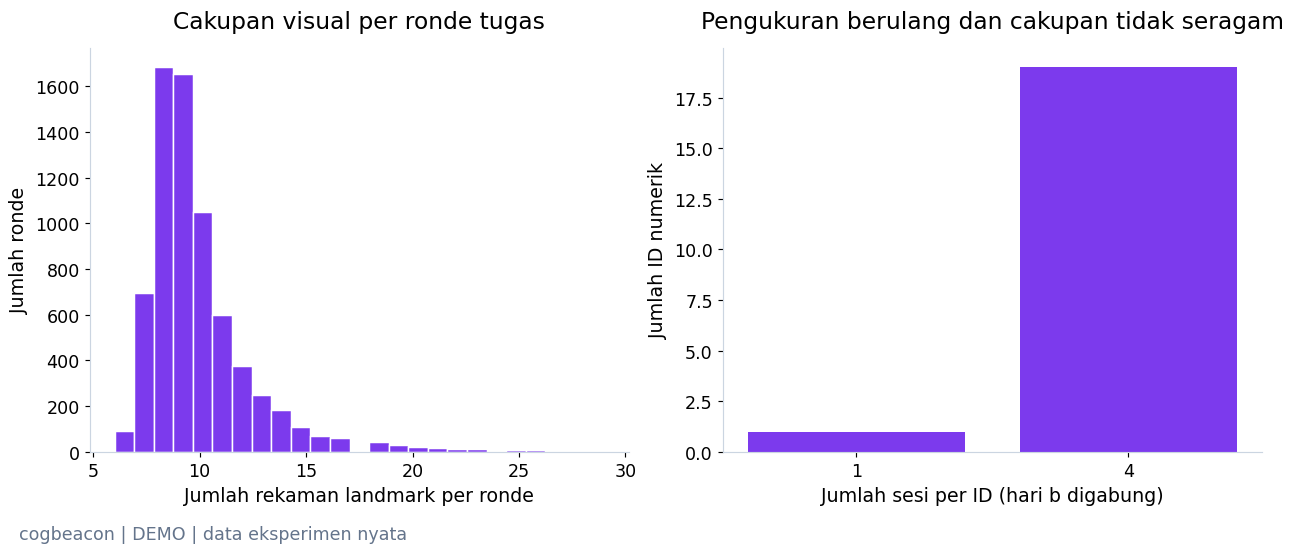

**Yang terlihat:** 68,118 NPZ diperiksa; 0 rekaman invalid menurut schema finite140angka.

**Artinya:** Keberadaan landmark dan alignment ronde bisa diaudit tanpa menganggap semua frame memiliki target fatigue.

**Perlu diingat:** Finite values bukan bukti landmark akurat; urutan koordinat dan clock absolut perlu validasi sebelum fitur fisiologis.

*Sumber: `20261024T164613827795Z_seed42_be9da7` · REAL / CACHED; inference dihitung ulang.*

In [53]:
fig,axes = plt.subplots(1,2,figsize=(12,4.8),layout='constrained')
axes[0].hist(cog_rounds.landmark_records,bins=25,color=COLORS['visual'],edgecolor='white')
axes[0].set(xlabel='Jumlah rekaman landmark per ronde',ylabel='Jumlah ronde',title='Cakupan visual per ronde tugas')
cog_session_counts = cog_sessions.groupby('subject_id').size().value_counts().sort_index()
axes[1].bar(cog_session_counts.index.astype(str),cog_session_counts.values,color=COLORS['visual'])
axes[1].set(xlabel='Jumlah sesi per ID (hari b digabung)',ylabel='Jumlah ID numerik',title='Pengukuran berulang dan cakupan tidak seragam')
cog_book.show(fig,'cog_coverage_dan_sessions',
              f'{cog_summary["landmark_records"]:,} NPZ diperiksa; {cog_summary["invalid_landmark_records"]} rekaman invalid menurut schema finite140angka.',
              'Keberadaan landmark dan alignment ronde bisa diaudit tanpa menganggap semua frame memiliki target fatigue.',
              'Finite values bukan bukti landmark akurat; urutan koordinat dan clock absolut perlu validasi sebelum fitur fisiologis.')
cog_book.finish()
if RUN_MODE == 'FULL':
    cog_metrics = metrics_base(cog_run,{}, {},{},None)
    cog_metrics['scope'] = 'descriptive_cognitive_fatigue_event_audit; no_supervised_score'
    cog_run.complete(cog_metrics,{'evaluation_rows':len(cog_sessions),**cog_summary},warning_records)
warning_context.__exit__(None,None,None)

### Apa yang sudah dan belum dapat disimpulkan dari CogBeacon?

**Yang didukung:** arsip dapat dibaca, identitas hari kedua dapat digabung, dan counter tombol dapat dibandingkan dengan ronde tugas.
**Yang belum didukung:** klasifikasi fatigue tiap frame/window, durasi blink dari sampling 2 FPS, dan PERCLOS.
Tidak ada confusion matrix atau F1 karena belum ada target supervisi yang sah. Tahap berikutnya adalah mengklarifikasi
jumlah peserta, sinkronisasi clock, makna tombol serta protokol validasi label dengan penulis dataset.

## 5. RQ2 — UTA-RLDD: klasifikasi tiga kondisi drowsiness

**Pertanyaan:** apakah pola mata membedakan Alert, Low Vigilance, dan Drowsy pada orang yang tidak masuk training?

Menurut [dokumentasi resmi](https://sites.google.com/view/utarldd/home),60 peserta membuat180 video RGB (~10 menit/video; ~30 jam). Code **0=Alert,5=Low Vigilance,10=Drowsy** adalah kategori, **bukan nilai KSS**. Peserta memilih kondisi dominan video berdasarkan panduan KSS; label tidak menjamin keadaan yang sama di setiap frame.

Audit HTTP berhasil membuka folder Google Drive dan menemukan10arsipZIP, total resmi111,3GB. **Tidak ada video UTA-RLDD lokal dan tidak ada download besar otomatis.** Lisensi redistribusi umum belum ditemukan; hanya36/60 peserta mengizinkan publikasi wajah, sehingga daftar orang yang sah harus diperiksa sebelum preview publik.

**Status eksperimen B1/B2: `NOT RUN — DATA UNAVAILABLE`.** Implementasi saat ini adalah adapter ingestion offline, bukan classifier yang telah dilatih. Adapter membaca metadata kontainer, checksum, kode kelas, IDpeserta dan folder arsip; menolak video duplikat/identitas ambigu. Tes adapter memakai fixture sintetis yang jelas berlabel engineering, tanpa menghasilkan skor penelitian.

Jika data sah tersedia: pertahankan lima fold resmi12 orang, pisahkan inner validation berdasarkan peserta, ekstrak landmark memakai detector/versi yang divalidasi, lalu bandingkan Dummy, Logistic Regression/SVM dan CNN dengan split yang sama. Laporkan MacroF1, balanced accuracy, recall/precision dan confusion matrix pada unit video. Jika melatih dari klip, labelnya weak supervision dan seluruh klip satu video harus tetap dalam fold peserta yang sama.

**Perlu diingat:** device, FPS, cahaya, waktu rekam dan proporsi51 pria/9 wanita dapat mengacaukan prediksi. Keberhasilan UTA-RLDD kelak menunjukkan drowsiness pada korpus tersebut, bukan fatigue ATC atau targetKSS numerik.

In [54]:
from atc_fatigue.io.visual_candidates import UTA_LABELS

candidate_audit = json.loads(Path('reports/visual_dataset_feasibility.json').read_text())
candidate_table = pd.DataFrame(candidate_audit['datasets'])
display(candidate_table[['dataset','target','ground_truth_quality','status']])
display(pd.DataFrame([{'Kode asli':code,'Kelas resmi':label,'Unit target':'predominant state per original video'}
                     for code,label in UTA_LABELS.items()]))
print('UTA-RLDD B1/B2: NOT RUN — DATA UNAVAILABLE. Tidak ada training, confusion matrix, atau skor fiktif.')

,dataset,target,ground_truth_quality,status
0,UTA-RLDD,video-level predominant drowsiness self-report,"drowsiness, weak video-level supervision; no g...",NOT RUN — DATA UNAVAILABLE
1,FatigueView,Awake/Fatigue directory categories; drowsiness...,"Yawning is a behavioral event, insufficient fo...",NOT RUN — DATA UNAVAILABLE
2,DriverFatigueDetection,sleep-deprivation condition vs sufficient-slee...,Fatigue-related induction condition; substanti...,NOT RUN — DATA UNAVAILABLE
3,LFD / DLFD (facial_fatigue),Observer-rated facial fatigue appearance with ...,"Observer-rated appearance, not independently v...",NOT RUN — DATA UNAVAILABLE
4,CCT / RVT mental-fatigue clinical study,Mental fatigue measured using18-item visual an...,Closer to measured mental fatigue than appeara...,NOT RUN — DATA UNAVAILABLE
5,CogBeacon,"Task difficulty/fatigue-related button events,...",Weak event proxy; absent button presses do not...,AUDIT ONLY — NO VALID DENSE TARGET


,Kode asli,Kelas resmi,Unit target
0,0,Alert,predominant state per original video
1,5,Low Vigilance,predominant state per original video
2,10,Drowsy,predominant state per original video


UTA-RLDD B1/B2: NOT RUN — DATA UNAVAILABLE. Tidak ada training, confusion matrix, atau skor fiktif.


## 6. RQ3 — FatigueView: apa yang bisa diaudit tanpa video?

[Project resmi](https://fatigueview.github.io/) menyediakan RGB/IR dari lima posisi kamera. [README dataset](https://github.com/FatigueView/fatigueview/tree/main/dataset) menggambarkan folder Awake/Fatigue dan menunjuk video melalui Baidu. GitHub sendiri tidak menyimpan video sumber. Gate Baidu terbuka, tetapi daftar aset/ukuran, video, identitas peserta dan hak penggunaan sumber belum terverifikasi.

**Yang benar-benar diperiksa:**20 JSON yawning dari repository resmi berhasil dibaca;266pasang indeks start/end lolos pemeriksaan numerik/urutan. Tidak ada blinkingJSON pada tree yang diaudit. Indeks belum dianggap milidetik atau frame sebelum clock/sourceFPS diverifikasi. **Yawn event bukan fatigue label** dan interval tanpa yawn bukan bukti non-fatigue.

**Status cross-camera/RGB–IR classifier: `NOT RUN — DATA UNAVAILABLE`.** Adapter offline mempertahankan view, modality, kategori, recording group, checksum dan metadata kontainer. Untuk mencegah leakage, adapter memerlukan pemetaan IDpeserta/sesi yang diverifikasi; folder `id_00XX` tidak otomatis dianggap orang independen. Beberapa kamera dari orang/sesi yang sama harus tetap bersama dalam partisi.

**Protokol yang layak nanti:** bekukan split peserta, latih pada kamera A hanya memakai training people, lalu evaluasi A dan B pada **orang holdout yang sama**. Perbandingan RGB/IR harus memakai populasi, label dan waktu yang sebanding. Pasangan kamera tidak menambah jumlah subjek independen. MIT pada repository adalah izin software/dokumentasi; izin video biometrik belum diasumsikan otomatis. Nama kategori Fatigue tidak setara pengukuran occupational fatigue.

,JSON diperiksa,Event yawning,Schema invalid,Source videos diunduh,Unit indeks
0,20,266,0,0,belum terverifikasi; tidak dikonversi ke durasi


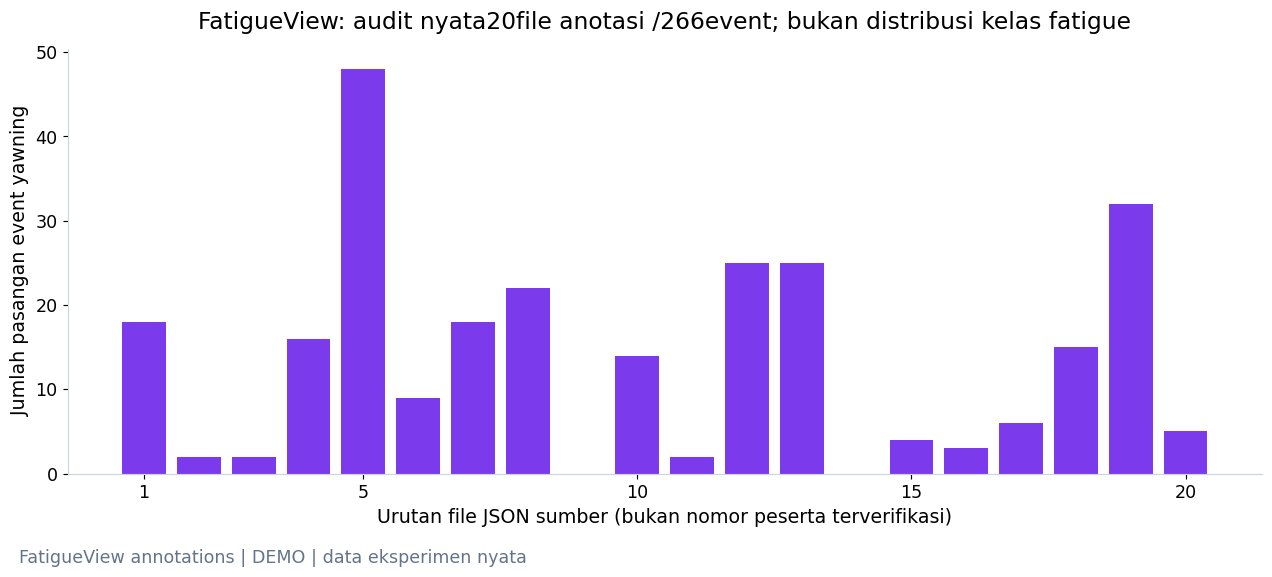

**Yang terlihat:** Grafik menghitung isi JSON resmi yang benar-benar diunduh; beberapa file tidak mempunyai event.

**Artinya:** Anotasi event dapat diaudit walaupun video belum tersedia; jumlah event berbeda dari jumlah klip/subjek berlabel fatigue.

**Perlu diingat:** Hanya20file kategoriFatigue tersedia; clock dan identitas belum terverifikasi. Tidak ada hasil klasifikasi.

*Sumber: `20261024T163204505429Z` · REAL / CACHED official JSON audit; FRESH count figure.*

In [55]:
dataset_pointer = json.loads(Path('reports/visual_dataset_audit_pointer.json').read_text())
annotation_audit = json.loads((Path(dataset_pointer['path'])/'fatigueview_annotation_audit.json').read_text())
annotation_counts = pd.DataFrame(annotation_audit)
display(pd.DataFrame([{'JSON diperiksa':len(annotation_counts),'Event yawning':int(annotation_counts.events.sum()),
    'Schema invalid':int((~annotation_counts.schema_valid).sum()),'Source videos diunduh':0,
    'Unit indeks':'belum terverifikasi; tidak dikonversi ke durasi'}]))
fig,ax = plt.subplots(figsize=(12,5),layout='constrained')
ax.bar(np.arange(1,len(annotation_counts)+1),annotation_counts.events,color=COLORS['visual'])
ax.set(xticks=[1,5,10,15,20],xlabel='Urutan file JSON sumber (bukan nomor peserta terverifikasi)',ylabel='Jumlah pasangan event yawning',
       title='FatigueView: audit nyata20file anotasi /266event; bukan distribusi kelas fatigue')
temporal_audit_view = SimpleNamespace(path=presentation_root/'visual_dataset_audit',
    manifest={'run_id':Path(dataset_pointer['path']).name,'experiment':'visual_dataset_audit','dataset':'FatigueView annotations'})
audit_book = FigureBook(temporal_audit_view,RUN_MODE,config)
audit_book.show(fig,'fatigueview_actual_annotation_counts',
    'Grafik menghitung isi JSON resmi yang benar-benar diunduh; beberapa file tidak mempunyai event.',
    'Anotasi event dapat diaudit walaupun video belum tersedia; jumlah event berbeda dari jumlah klip/subjek berlabel fatigue.',
    'Hanya20file kategoriFatigue tersedia; clock dan identitas belum terverifikasi. Tidak ada hasil klasifikasi.',
    origin='REAL / CACHED official JSON audit; FRESH count figure')
audit_book.finish()

## 7. RQ4 — Dataset mana yang benar-benar mengukur fatigue?

| Kandidat | Definisi target dan kekuatan bukti | Keputusan saat ini |
| :--- | :--- | :--- |
| [DriverFatigueDetection](https://github.com/ChenDelong1999/DriverFatigueDetection) |17 driver,251fatigue+245non-fatigue video ~100 detik. [Paper](https://doi.org/10.1016/j.engappai.2022.105399) membedakan sleep deprivation dan sufficient sleep. Ini kondisi induksi terkait fatigue/sleepiness, belum bukti skala fatigue tervalidasi per video. | Download harus meminta penulis; identitas, instrumen label dan izin perlu dikonfirmasi. **NOT RUN — DATA UNAVAILABLE**. |
| [LFD/DLFD](https://github.com/zykev/facial_fatigue) |[Paper](https://arxiv.org/abs/2104.10420):32 orang/375 video. Tiga penilai memberi skor1–5 berdasar tampilan audiovisual dengan konteks self-evaluation; mean dinormalisasi0–1. Ini **observer-rated appearance**, bukan pengukuran occupational fatigue independen. | Data melalui penulis; README5–60 detik berbeda dengan paper5 detik–2 menit. Ambang kategori dan participant mapping belum diaudit. **NOT RUN — DATA UNAVAILABLE**. |
| [CCT/RVT mental fatigue](https://arxiv.org/abs/2304.12470) |24 orang/111 sesi;18-item visual analogue scale sebelum/sesudah tugas, ditelaah bersama reaction time. Lebih dekat dengan **mental fatigue yang diukur**, tetapi supervisi hanya endpoint sesi. | Paper membatasi data untuk personel dalam IRB. Tidak dapat dianggap open dataset; populasi lansia dengan mild cognitive impairment berbeda dari ATC. **NOT RUN — DATA UNAVAILABLE**. |
| CogBeacon, bagian4 |Event kesulitan/fatigue-related task; counter kumulatif, bukan fatigue setiap window. Sampling2 FPS tidak memadai untuk blink duration. | Audit deskriptif dipertahankan; tidak memaksakan classifier. |

[Audit terstruktur](../../reports/visual_dataset_feasibility.json) mencatat sumber, akses aktual, label, lisensi, pengukuran berulang, split feasibility dan confounds masing-masing. [Panduan ingestion dan provenance](../../docs/visual_dataset_feasibility.md) menjelaskan langkah akses tanpa mengirim permintaan kepada orang lain secara otomatis.

**Kesimpulan RQ4:** belum ada dataset visual fatigue-specific tambahan yang tersedia lokal dengan label dan hak penggunaan cukup jelas untuk baseline baru. Menyebut semua foto bermata tertutup sebagai fatigue akan mengubah pertanyaan penelitian dan menyesatkan. Karena itu tidak ada angka performa buatan.

## 8. Apa keputusan penelitian setelah eksperimen ini?

- **Terimplementasi dan dijalankan:** baseline MRL/DROZY lama tetap tersedia; CNN DROZY A1/A2 memakai36 test/14 orang, inner subject validation dan3 seed. Checkpoint dan prediksi benar-benar dihasilkan.
- **Terimplementasi dan diuji secara engineering:** adapter UTA-RLDD/FatigueView, guard duplikasi/identitas dan audit eventJSON; fixture pengujian bukan data benchmark.
- **Belum dijalankan karena akses/data:** B1/B2 UTA, cross-camera FatigueView, baseline fatigue-specific. **Tidak diimplementasikan:** video-CNN besar opsional dan transfer learning UTA→DROZY; sumber encoder belum tersedia, sehingga belum ada transfer checkpoint.
- **Langkah berikutnya:** tentukan subset UTA yang sah beserta batas download, audit detector/timestamp, klarifikasi label/identitas FatigueView, dan pertimbangkan pengumpulan ATC berizin dengan instrumen fatigue yang tervalidasi. Pertahankan hasil negatif CNN sebagai temuan, bukan mengejar skor dengan tuning berulang pada test.

Temuan saat ini menjawab kelayakan pipeline serta batas pendekatan temporal kecil. Kita **belum mendeteksi fatigue operator ATC**, dan tidak menyamakan drowsiness, KSS sleepiness, eye state, dan observer-rated fatigue.

**Kesimpulan:** gambar dan urutan mata dapat diproses, baseline dapat dilatih, dan kegagalan dapat ditelusuri. Skor tetap terpisah menurut target. Lanjut ke [notebook fusion](03_multimodal_fusion.ipynb) untuk menguji audio-video yang benar-benar berpasangan. [Petunjuk FULL/DEMO](README.md).

---
# UTA-RLDD — Pretrained Deep Learning for Drowsiness Classification

**Pertanyaan penelitian:** apakah fitur gambar pretrained yang dibekukan, fitur yang diadaptasi, atau fitur video pretrained paling baik mengenali kondisi kantuk pada **peserta yang belum pernah dilihat model**?

Bagian tambahan ini berdiri sendiri. Seluruh sel MRL, DROZY, dan CogBeacon di atas dipertahankan persis seperti sebelumnya, termasuk hasil dan metadata. Tidak ada training ulang DROZY.

Alur kita: **video asli → timestamp dan rotasi → wajah → klip berurutan → fitur pretrained → training pada peserta train → satu prediksi per rekaman → evaluasi peserta test**. Gambar wajah dan video UTA tetap lokal; grafik di sini memperlihatkan angka eksperimen nyata tanpa menampilkan identitas biometrik.

**Navigasi:** 1 Data dan label · 2 Sampling · 3 Representasi · 4 Frozen ResNet · 5 Fine-tuning · 6 X3D · 7 Evaluasi · 8 Perbandingan · 9 Kesalahan · 10 Makna penelitian.


### Status eksekusi: pilot nyata, bukan benchmark penuh

**COMPLETED — ENGINEERING PILOT:** 4 arsip / 24 peserta / 72 rekaman asli tersedia. Train peserta 01–12 (36 rekaman), validation 13–18 (18), test 19–24 (18). Ketiga model dibandingkan pada **18 rekaman dari enam peserta test yang sama**. Semua data seorang peserta tetap pada satu partisi.

**NOT RUN — DATA UNAVAILABLE:** benchmark resmi 60 peserta / lima outer fold. Keenam arsip Fold3–Fold5 mengembalikan *Google Drive Quota exceeded* saat unduhan penuh diminta. Inspeksi central directory berhasil sebelumnya, tetapi itu tidak menjamin source videos dapat diunduh.

Protokol lima fold di bawah didokumentasikan sebagai **implementasi yang siap dijalankan ketika akses pulih**, bukan hasil yang telah selesai. Tidak ada klaim konsistensi antarfold atau model terbaik secara definitif. Angka hasil dan grafik pada appendix ini seluruhnya diberi status **PILOT**.

```bash
PYTHONPATH=src .venv/bin/python scripts/run_uta_pretrained_benchmark.py \
  --config configs/uta_pretrained_pilot.json \
  --index configs/manifests/uta_official_release.json --pilot
```


## 1. Dataset, provenance, dan arti label

[UTA-RLDD resmi](https://sites.google.com/view/utarldd/home) menyediakan 60 peserta dan nominal 180 rekaman sekitar sepuluh menit. Kondisi dominan ditentukan melalui **self-report**, dibantu panduan KSS; ini bukan anotasi fisiologis setiap frame.

| Kode asli | Kelas | Arti target |
|---|---|---|
| 0 | Alert | Kondisi dominan waspada |
| 5 | Low Vigilance | Kewaspadaan mulai menurun |
| 10 | Drowsy | Kondisi dominan mengantuk |

Kode **0/5/10 adalah kategori, bukan angka KSS untuk regresi**. Indeks internal 0/1/2 hanya dipakai menghitung cross entropy. Identitas peserta dan lima fold diambil dari struktur arsip resmi yang benar-benar diperiksa.

Audit release menemukan **182 file fisik**, karena rekaman Drowsy peserta 32 dan 49 masing-masing terbagi dua. Kedua bagian digabung sebagai satu unit peserta-kondisi: total tetap **180 unit evaluasi**. Timestamp antarfile tidak dianggap kontinu. Dua file M4V dan rotasi native juga ditangani secara eksplisit.

Data diakses untuk penelitian; izin publikasi wajah tidak berlaku untuk seluruh peserta. Tidak ada video, crop wajah, atau full feature cache UTA yang dibagikan di GitHub.


In [1]:
from pathlib import Path
import json
import sys

from IPython.display import Image, Markdown, display
import pandas as pd

UTA_ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
                if (path / "configs/uta_pretrained_benchmark.json").is_file())
sys.path.insert(0, str(UTA_ROOT / "src"))
from atc_fatigue.utils.runtime import checksum

uta_report = json.loads((UTA_ROOT / "reports/uta_pretrained_benchmark.json").read_text())
uta_config = uta_report["metrics"]["protocol"]
print("CACHED / REAL —", uta_report["status"])
print("Run ID:", uta_report["run_id"])
print("Sumber label: kondisi dominan per video; target drowsiness, bukan fatigue ATC.")
local_metrics = UTA_ROOT / uta_report["run_root"] / "metrics.json"
if local_metrics.exists():
    assert checksum(local_metrics) == uta_report["metrics_sha256"]
    print("Checksum hasil lokal cocok dengan ringkasan presentasi.")

def uta_show_figure(name):
    path = UTA_ROOT / "reports/figures/uta_pretrained" / name
    if not path.is_file():
        raise FileNotFoundError(f"Grafik tervalidasi belum tersedia: {name}")
    display(Image(filename=str(path)))

uta_coverage = pd.DataFrame(uta_report["coverage"])
uta_distribution = pd.DataFrame(uta_report["class_distribution"])
display(uta_distribution.pivot(index="official_fold", columns="label", values="recordings")
        .rename_axis(index="Fold resmi", columns="Kode kelas asli"))
display(uta_coverage.groupby("official_fold").agg(
    peserta=("subject_id", "nunique"), rekaman=("recording_group_id", "size"),
    rekaman_layak=("eligible", "sum"), coverage_rata_rata=("valid_frame_coverage", "mean")))


CACHED / REAL — COMPLETED ENGINEERING PILOT — official five-fold NOT RUN (source quota)
Run ID: 20261024T181239217688Z
Sumber label: kondisi dominan per video; target drowsiness, bukan fatigue ATC.
Checksum hasil lokal cocok dengan ringkasan presentasi.


Kode kelas asli,0,5,10
Fold resmi,,,
1,12,12,12
2,12,12,12


,peserta,rekaman,rekaman_layak,coverage_rata_rata
official_fold,,,,
1,12,36,36,0.995370
2,12,36,36,0.979167


**Yang terlihat:** tabel menghitung peserta, rekaman, kelas, dan coverage hasil ekstraksi sesungguhnya pada tiap fold.

**Artinya:** distribusi ini menentukan populasi yang boleh dibandingkan oleh ketiga model. Rekaman dengan deteksi wajah buruk tetap tercatat; semua model menggunakan cohort layak yang sama.

**Perlu diingat:** coverage di sini adalah proporsi klip terpilih yang valid, bukan persentase seluruh sepuluh menit yang berhasil dianalisis. Perbedaan pencahayaan, perangkat, pose, dan ciri peserta dapat menjadi confounder.


## 2. Preprocessing dan temporal sampling

Kita tidak memasukkan sepuluh menit video sekaligus ke GPU. Setiap unit rekaman memperoleh anggaran **12 klip × 1,6 detik × 4 frame** yang tersebar dari awal, tengah, sampai akhir. Untuk file yang terbagi dua, anggaran 12 klip dibagi berdasarkan durasi total; satu klip tidak melintasi batas file.

Decoder memakai **native presentation timestamps (PTS)**, yaitu waktu penayangan frame dari file. Metadata rotasi diterapkan sebelum deteksi wajah dengan YuNet. Empat frame per klip dipilih secara berurutan tanpa interpolasi; jeda besar dalam frame native membuat klip invalid.

Wajah harus terdeteksi tunggal pada seluruh frame terpilih. Median bounding box dengan margin 1,3 dipakai konsisten dalam klip, lalu di-resize menjadi 256×256 RGB. Tidak ada fallback seluruh frame yang menyembunyikan kegagalan detektor. Rekaman layak memerlukan minimal tiga klip valid dan cakupan awal/tengah/akhir.

**Weak supervision** berarti kita memakai label dominan satu video untuk melatih agregat klipnya. Kita tidak mengetahui apakah setiap klip benar-benar menunjukkan tingkat kantuk yang sama. Loss dan evaluasi tetap pada level rekaman, bukan frame/klip.


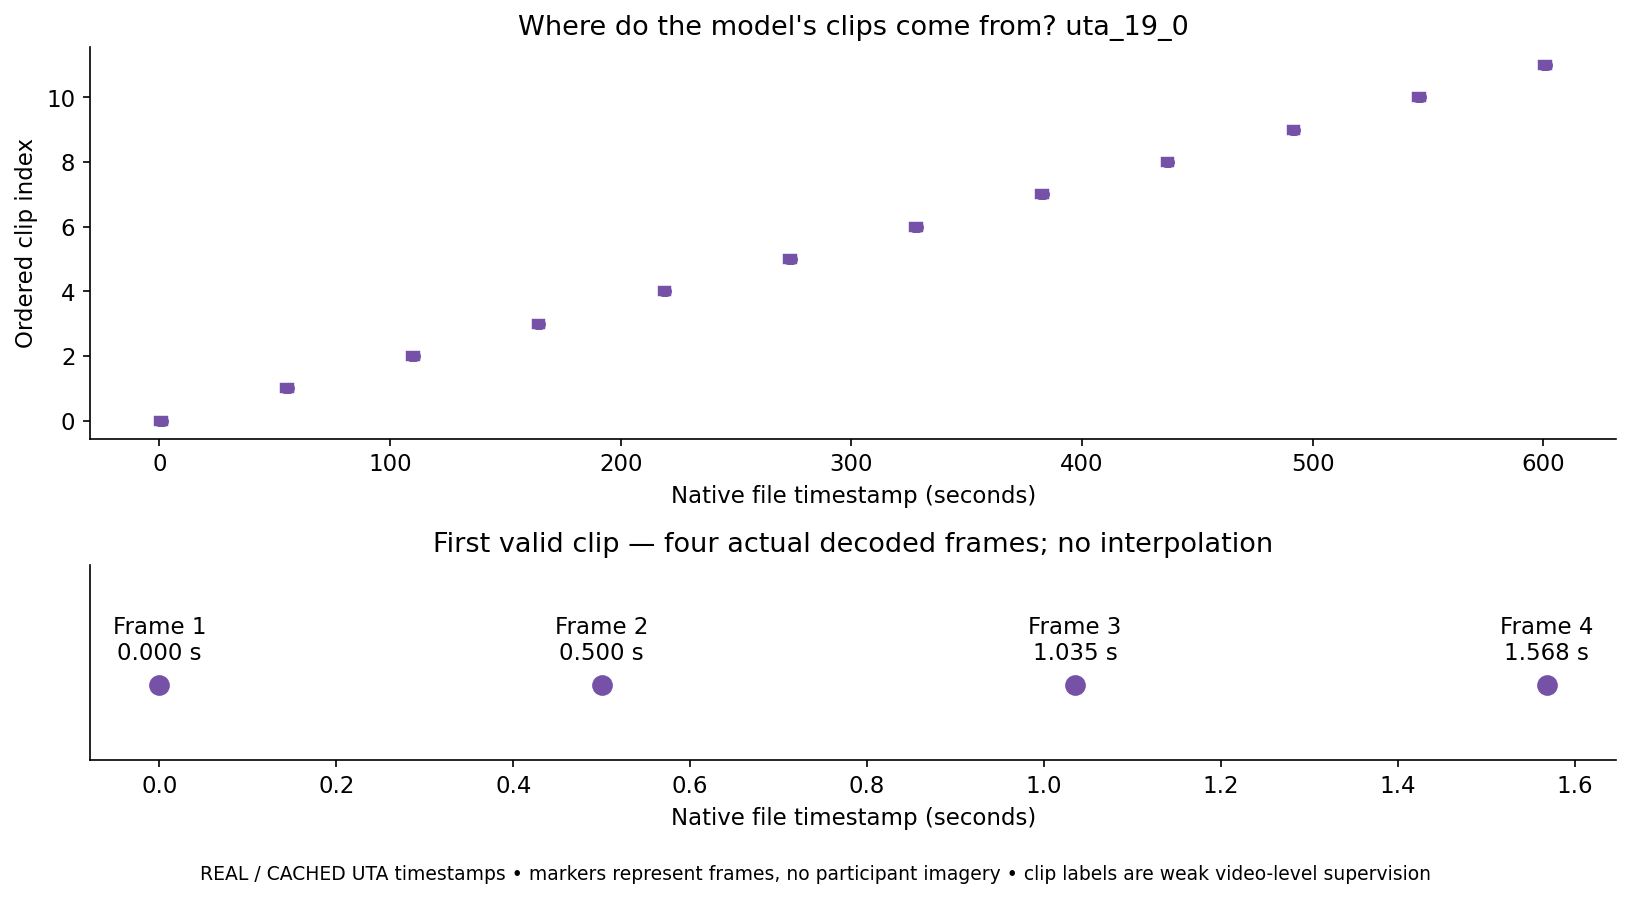

In [2]:
uta_show_figure("temporal_sampling.png")

**Yang terlihat:** setiap garis adalah interval klip pada timestamp sumber; titik-titik menunjukkan empat frame yang benar-benar didekode. Zoom memperlihatkan waktu frame pada klip valid pertama.

**Artinya:** urutan lokal dipertahankan. Representasi mengambil informasi dari beberapa bagian rekaman tanpa membentuk tensor sepuluh menit.

**Perlu diingat:** sampling empat frame dalam 1,6 detik terlalu jarang untuk mengukur blink duration atau PERCLOS fisiologis dengan presisi. Model ini mempelajari pola penampilan dan dinamika kasar, bukan pengganti ekstraksi EAR beresolusi tinggi. Rata-rata logit antar-klip juga tidak memodelkan urutan sepanjang sepuluh menit.


## 3. Angka apa yang masuk ke model?

**Skema konseptual — bukan hasil pengukuran:**

```text
Satu recording, maksimal 12 klip (semua kelas tetap 0 / 5 / 10)
             ↓
Face crops [n_valid_clips, 4, 256, 256, 3] uint8 RGB
       ┌─────┴─────────────────────────────┐
       ↓                                   ↓
ResNet official transforms             X3D official transforms
[clips,4,3,224,224]                     [clips,3,4,182,182]
       ↓                                   ↓
Frame embeddings [clips,4,512]          Clip embeddings [clips,2048]
       ↓                                   ↓
Temporal CNN + masked pooling           Linear classification head
       └──────────────┬────────────────────┘
                [clips,3] logits
                       ↓ mean valid-clip logits
                [3] video logits → softmax probabilities
```

**Logit** adalah nilai dukungan model sebelum diubah menjadi probabilitas. **Embedding** adalah vektor angka keluaran pretrained backbone yang merangkum pola visual. Participant ID, filename, timestamp, dan label tidak dimasukkan sebagai predictor. Timestamp hanya mengatur urutan sampling.

ResNet memakai resize 256, center crop 224, dan normalisasi ImageNet resmi. X3D memakai resep inference resmi PyTorchVideo: empat frame, crop 182, mean 0,45 dan standard deviation 0,225. Factory X3D menggunakan training crop 160; checkpoint yang sama mendukung inference crop 182 sesuai panduan resminya.


In [3]:
uta_representation_rows = []
for example in uta_report["representations"]:
    for name in ["frozen_resnet18", "x3d_xs"]:
        feature = example[name]
        uta_representation_rows.append({
            "recording": example["recording_group_id"], "model": name,
            "raw_shape": str(example["raw_clip_shape"]),
            "feature_shape": str(feature["feature_shape"]),
            "first_12_actual_values": [round(value, 4) for value in feature["first_12_values"]],
            "min": feature["min"], "max": feature["max"],
            "mean": feature["mean"], "std": feature["std"],
            "finite_fraction": feature["finite_fraction"],
        })
display(pd.DataFrame(uta_representation_rows))
print("REAL / CACHED pretrained embeddings; cuplikan 12 angka, bukan seluruh cache.")


,recording,model,raw_shape,feature_shape,first_12_actual_values,min,max,mean,std,finite_fraction
0,uta_19_0,frozen_resnet18,"[12, 4, 256, 256, 3]","[12, 4, 512]","[1.7373, 0.1053, 0.6616, 1.4893, 0.7358, 0.045...",0.0,9.523438,0.780152,0.827667,1.0
1,uta_19_0,x3d_xs,"[12, 4, 256, 256, 3]","[12, 2048]","[0.0, 0.0, 0.0, 0.0, 0.0, 0.056, 0.0, 0.5996, ...",0.0,1.820312,0.138495,0.255820,1.0


REAL / CACHED pretrained embeddings; cuplikan 12 angka, bukan seluruh cache.


**Yang terlihat:** shape dan cuplikan nilai embedding berasal dari klip UTA yang benar-benar dipakai pipeline. Satu dimensi embedding bukan satu ukuran anatomi yang mudah diberi nama seperti EAR.

**Artinya:** head menerima representasi numerik sungguhan, bukan metadata atau ilustrasi. Frozen backbone menghasilkan fitur tetap; fine-tuning mengubah representasi layer4 berdasarkan peserta train pada setiap fold.

**Perlu diingat:** tabel menampilkan embedding frozen yang dapat diaudit secara ringkas. Embedding fine-tuned berbeda antarfold, sehingga tidak boleh dianggap sebagai satu cache global yang dilatih memakai semua peserta.


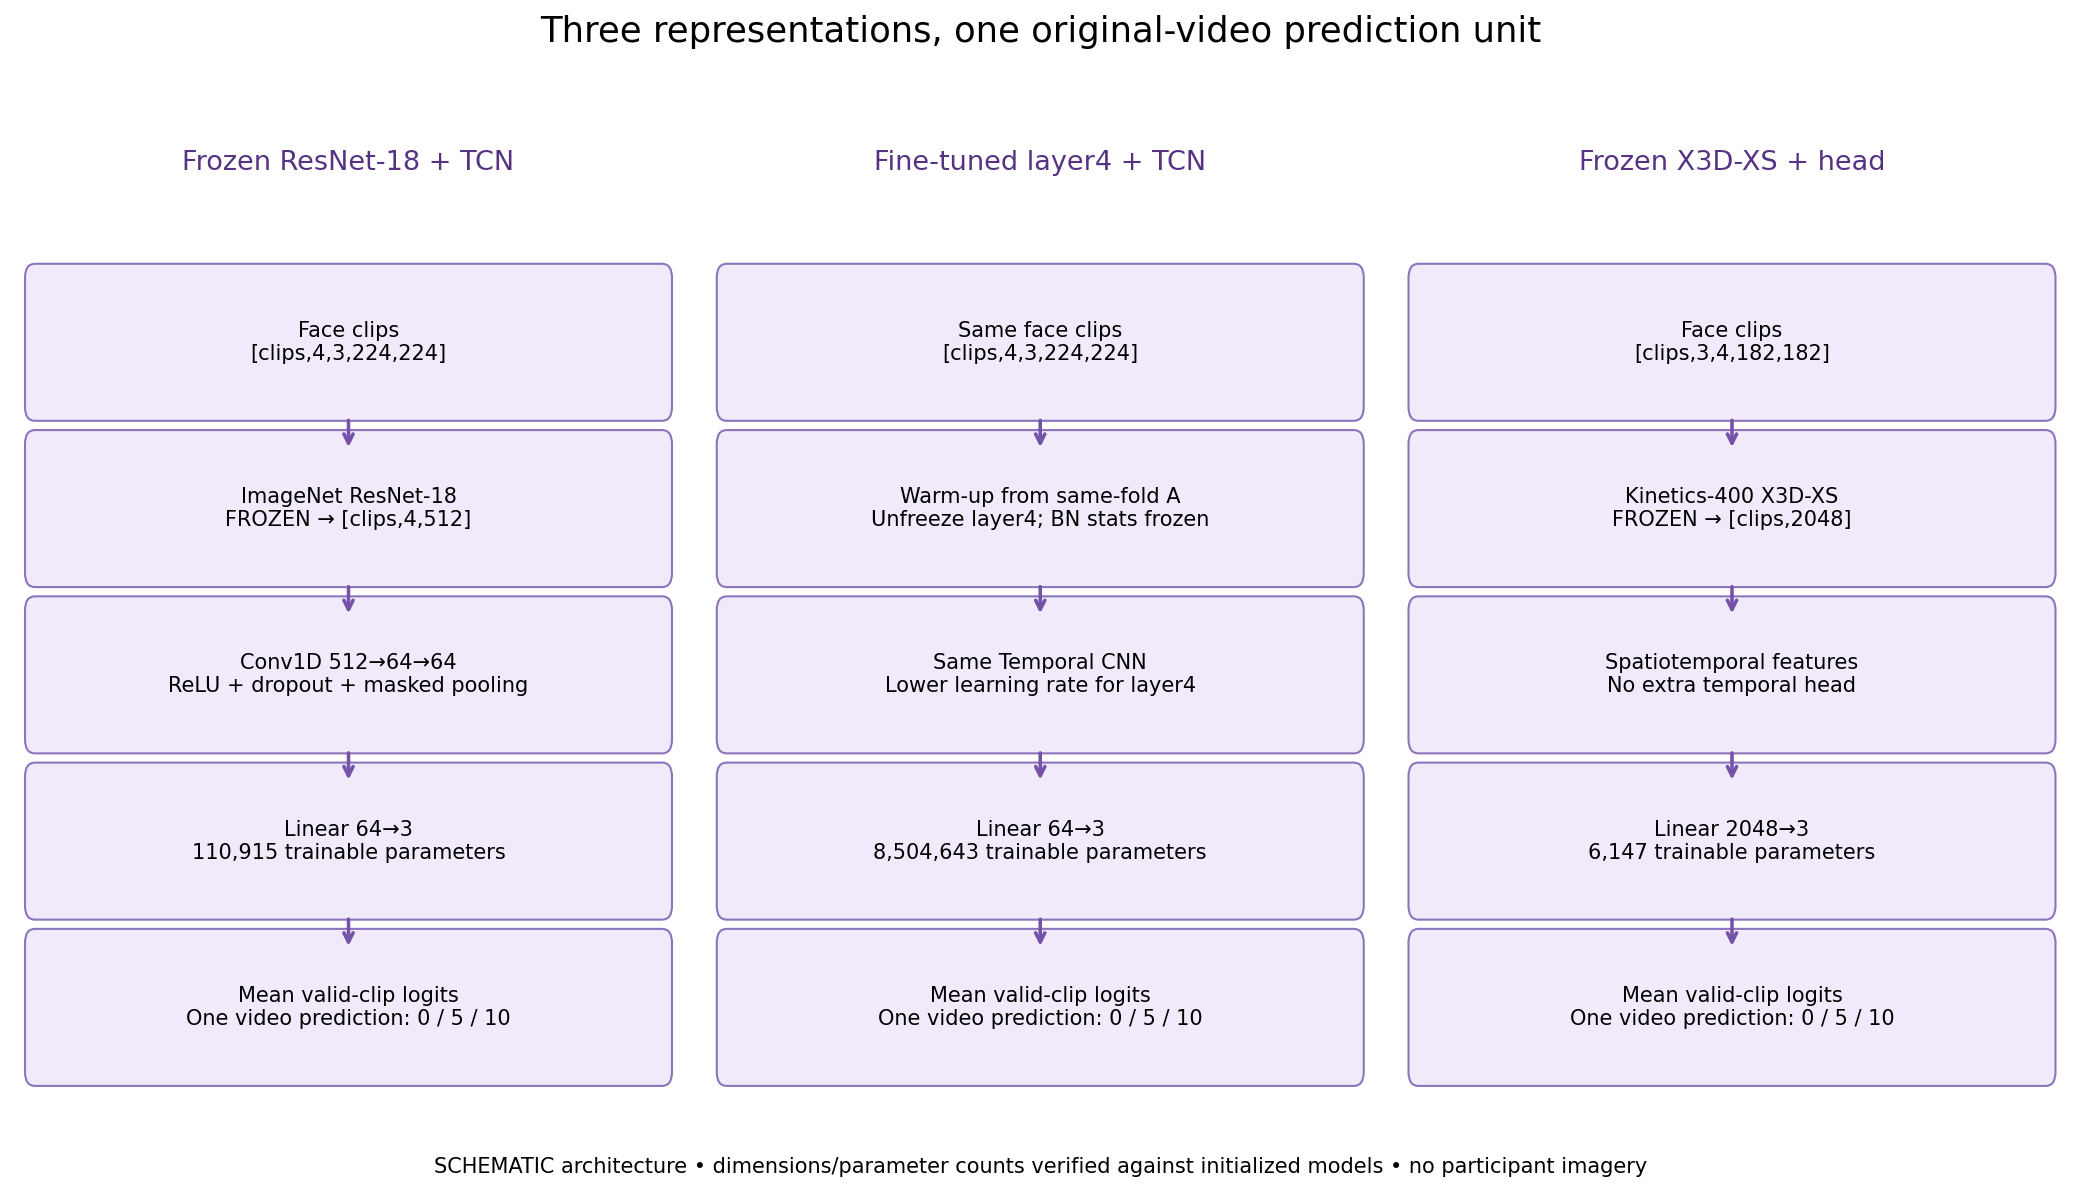

In [4]:
uta_show_figure("architectures.png")

**Yang terlihat:** diagram SCHEMATIC merangkum jalur tensor dan bagian yang dilatih pada ketiga model.

**Artinya:** seluruh jalur berakhir pada tiga logit per rekaman yang sama, walaupun representasi dan biaya adaptasinya berbeda.

**Perlu diingat:** panah adalah penjelasan arsitektur, bukan bukti akurasi; performa harus dibaca dari evaluasi peserta test di bagian berikutnya.


## 4. Experiment A — Frozen ResNet-18 + Temporal CNN

**Input:** urutan empat embedding 512 dimensi pada setiap klip. ResNet-18 ImageNet-1K dibekukan seluruhnya. Head menggunakan Conv1D(512→64, kernel 3), ReLU, dropout 0,25, Conv1D(64→64, kernel 3), ReLU, dropout, masked temporal pooling, lalu Linear(64→3).

**Apa yang dilatih?** Hanya 110.915 parameter temporal/classification head dari total 11.287.427 parameter. Fitur frozen dicache; validation dan test memakai satu versi clean. Training dapat memilih clean atau dua variasi brightness/contrast ringan yang deterministik.

Tujuannya menguji apakah representasi gambar generik sudah cukup tanpa menyesuaikan backbone. Pooling mengabaikan padding; tidak ada pengisian frame yang hilang seolah-olah merupakan pengamatan baru.


## 5. Experiment B — Partial fine-tuning ResNet-18 + Temporal CNN

Arsitektur dan populasi evaluasinya sama dengan A. **Stage 1** memakai checkpoint terbaik A dari outer fold yang sama sebagai frozen warm-up. **Stage 2** hanya membuka residual stage terakhir, `layer4`, bersama head: 8.504.643 parameter trainable.

Learning rate layer4 adalah 0,00001, sedangkan head 0,0001; optimizer AdamW memakai weight decay 0,0001. BatchNorm running statistics tetap frozen karena batch video kecil. Model tidak mengambil checkpoint A dari fold lain: peserta outer-test harus tetap berada di luar semua proses pembelajaran fold tersebut.

Pertanyaan ilmiahnya adalah apakah adaptasi spatial representation memperbaiki generalisasi. Lebih banyak parameter juga memperbesar risiko overfitting; nilai training yang membaik belum cukup sebagai bukti keberhasilan.


## 6. Experiment C — Kinetics-pretrained X3D-XS

X3D-XS memproses ruang dan waktu bersama melalui video CNN. Implementasi resmi PyTorchVideo dan checkpoint Kinetics-400 dimuat **strict** sebagai model 400 kelas sebelum head diganti. Tidak ada substitusi bobot random.

Encoder 2.974.674 parameter dibekukan, lalu sebuah Linear(2048→3) dengan 6.147 parameter trainable dipelajari pada UTA. Total model menjadi 2.980.821 parameter. Hasil tiap klip digabung dengan mean logits yang sama seperti A dan B.

Ini adalah baseline **frozen spatiotemporal feature extractor**, bukan full-network fine-tuning X3D. Kinetics berisi aktivitas umum, bukan kantuk. Perbedaan pretraining dan kapasitas head membatasi penafsiran perbandingan; skor tidak mengisolasi arsitektur sebagai satu-satunya penyebab.


## 7. Training dan participant-disjoint evaluation

Pada outer fold k, semua peserta fold k menjadi test; fold berikutnya secara siklik menjadi validation; tiga fold sisanya menjadi train. Dengan release lengkap, ini berarti **36 peserta train / 12 validation / 12 test**. Rekaman yang gagal quality control dikeluarkan secara seragam dari ketiga model dan tetap tercatat.

- Train: optimasi cross entropy satu kali per rekaman, maksimal 12 klip valid, gradient accumulation empat rekaman.
- Validation: pemilihan checkpoint berdasarkan Macro F1; jika seri, pilih cross entropy lebih rendah. Early stopping hanya memakai validation.
- Test: evaluasi checkpoint terpilih tanpa tuning berdasarkan skor test. Benchmark penuh dirancang menghasilkan prediksi lima outer fold, tetapi **belum dijalankan** karena enam arsip resmi terkena Google Drive Quota exceeded. Pilot saat ini menghasilkan satu held-out prediction per test recording.

A/C dibatasi 30 epoch; partial fine-tuning B dibatasi 20 epoch. Minimum lima epoch, patience lima, seed 42 dengan seed fold deterministik. Tidak ada unrestricted hyperparameter search. Augmentasi hanya pada peserta train.

**Menjalankan training sungguhan** adalah tindakan eksplisit lewat runner di bawah. Rerun bagian notebook ini hanya membaca artefak tervalidasi; tidak memakai GPU atau mengklaim training baru.

```bash
PYTHONPATH=src .venv/bin/python scripts/run_uta_pretrained_benchmark.py \
  --config configs/uta_pretrained_benchmark.json \
  --index configs/manifests/uta_official_release.json \
  --models frozen_resnet18 finetuned_resnet18 x3d_xs --all-folds
# Tambahkan --resume runs/uta_pretrained/<run_id> untuk melanjutkan run yang terinterupsi.
```


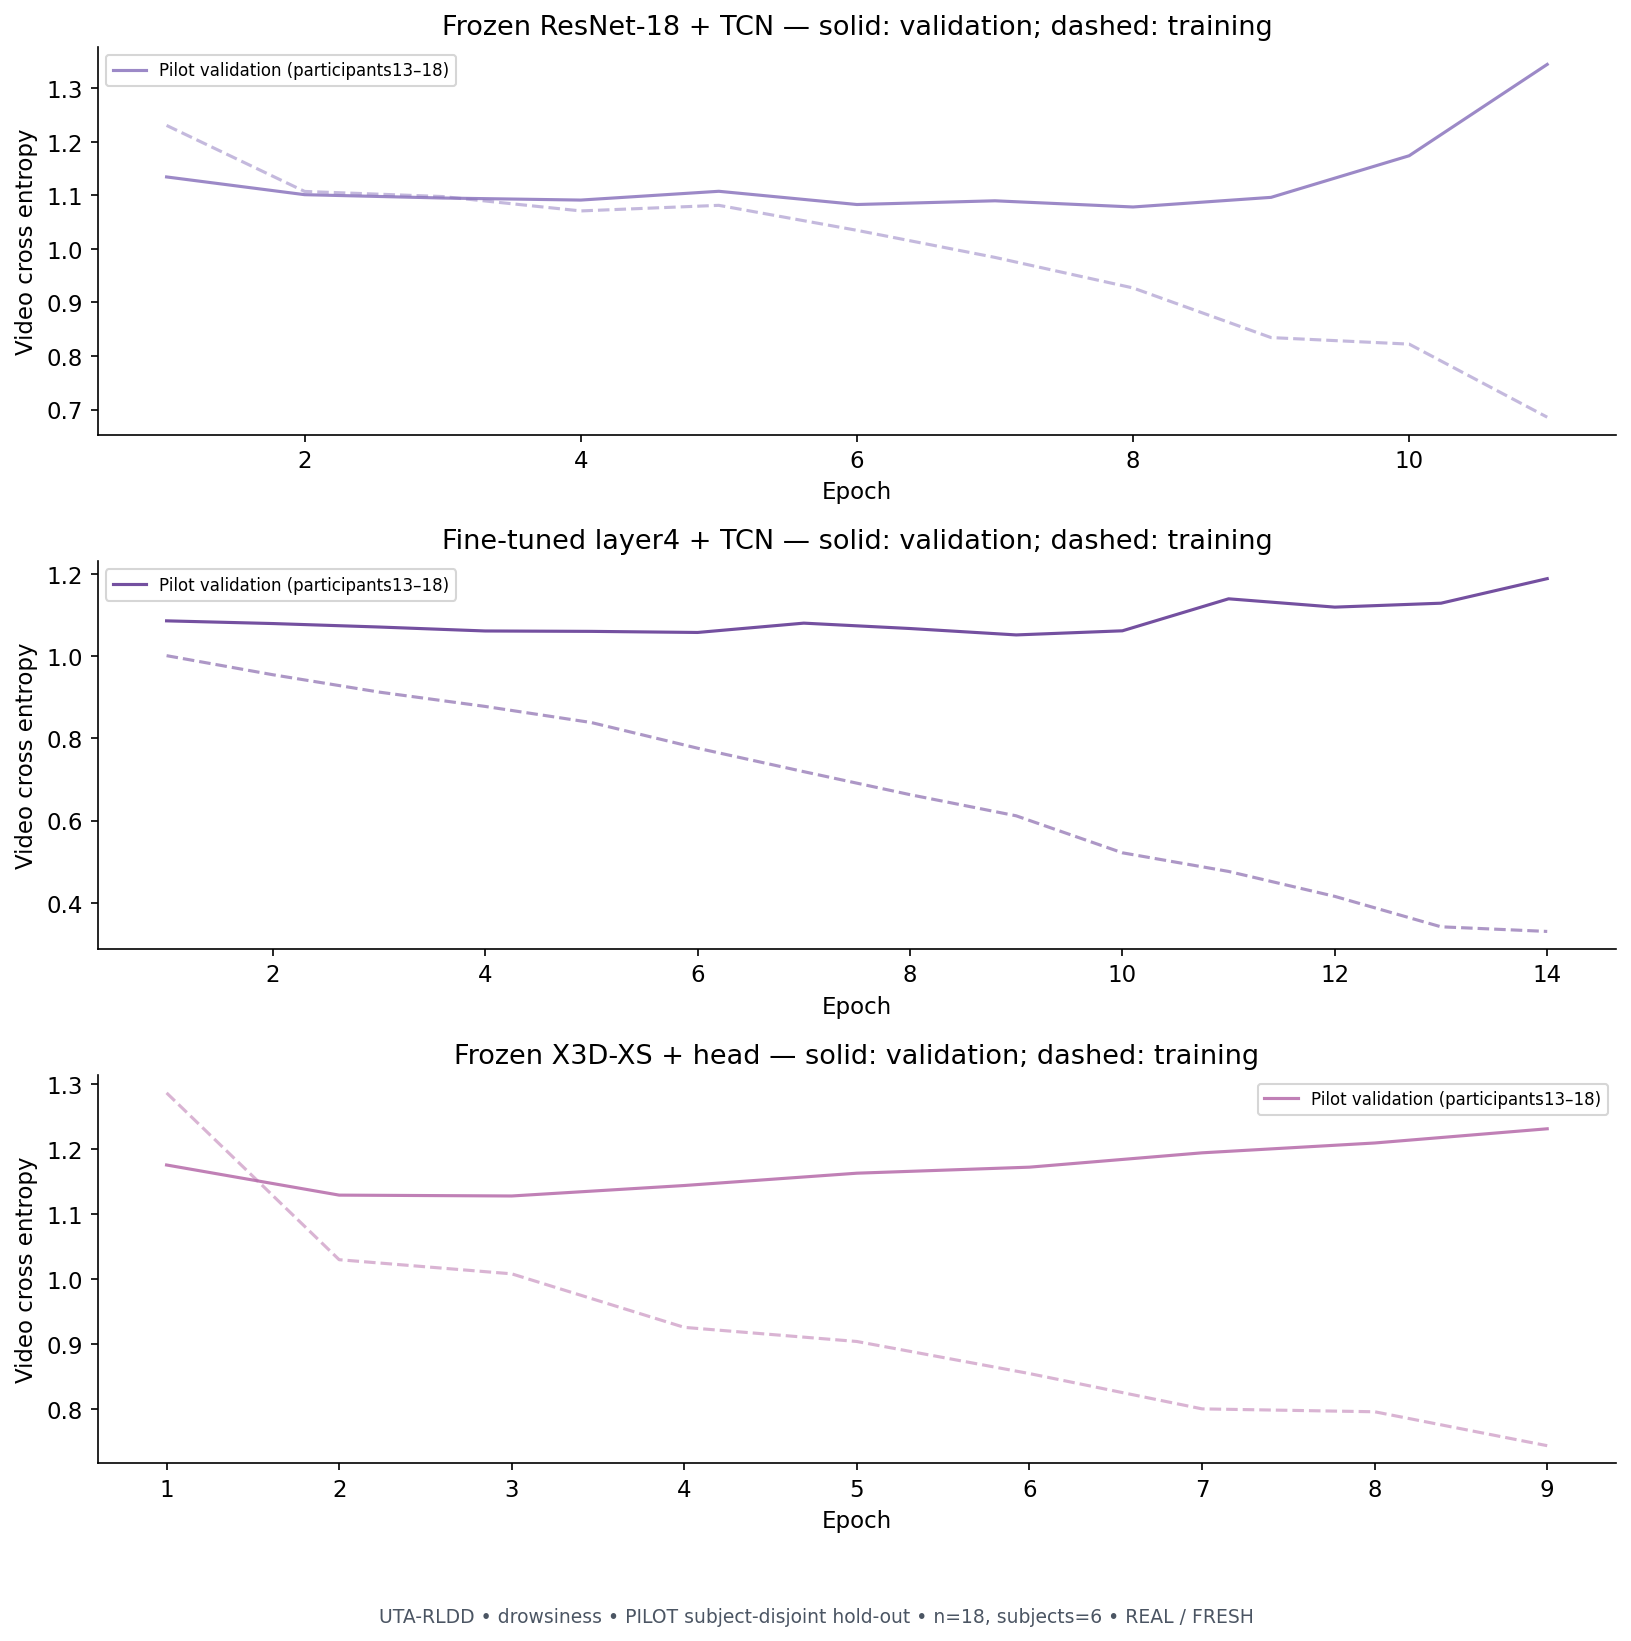

In [5]:
uta_show_figure("learning_curves.png")

**Yang terlihat:** garis putus-putus menunjukkan loss training, garis solid menunjukkan loss validation peserta terpisah. Pilot ini hanya memiliki satu validation split; variasi lima fold belum diukur.

**Artinya:** jarak antara training dan validation membantu melihat overfitting. Checkpoint dipilih lewat validation Macro F1, sehingga bukan otomatis epoch terakhir atau loss training terendah.

**Perlu diingat:** loss pada tiga kelas tidak sama dengan skor fatigue. Perbandingan biaya B juga mencakup ketergantungan warm-up A; waktu B yang ditampilkan adalah tahap fine-tuning tambahan.


**Hasil aktual pilot:** loss training terus turun, sementara loss validation tidak mengikuti penurunan itu secara konsisten. Checkpoint terpilih adalah epoch6 (A), epoch9 (B), dan epoch4 (C), bukan epoch terakhir. Pola ini mendukung kehati-hatian terhadap overfitting pada 36 rekaman train.

## 8. Perbandingan tiga model pada rekaman test yang sama

**Macro F1** memberi bobot sama pada ketiga kelas; **Balanced Accuracy** merata-ratakan recall tiap kelas; **Accuracy** menghitung proporsi semua prediksi benar. Confusion matrix memperlihatkan kelas mana yang tertukar. Ketiganya perlu dibaca bersama jumlah peserta dan rekaman.


In [6]:
display(pd.DataFrame(uta_report["model_comparison"]).drop(columns=["display"]).round(4))
display(pd.DataFrame(uta_report["per_fold"]).pivot(index="fold", columns="model", values="macro_f1").round(4))
print("Majority reference Macro F1:", round(uta_report["metrics"]["majority_reference"]["macro_f1"], 4))
print("Reference dihitung dari kelas mayoritas TRAIN tiap fold; bukan model CNN keempat.")


,model,macro_f1,balanced_accuracy,accuracy,trainable_parameters,total_parameters,seconds,peak_gpu_mib
0,frozen_resnet18,0.4333,0.4444,0.4444,110915,11287427,31.6268,367.8945
1,finetuned_resnet18,0.4777,0.5000,0.5000,8504643,11287427,118.8473,464.7656
2,x3d_xs,0.5536,0.5556,0.5556,6147,2980821,27.9127,157.8701


model,finetuned_resnet18,frozen_resnet18,x3d_xs
fold,,,
2,0.4777,0.4333,0.5536


Majority reference Macro F1: 0.1667
Reference dihitung dari kelas mayoritas TRAIN tiap fold; bukan model CNN keempat.


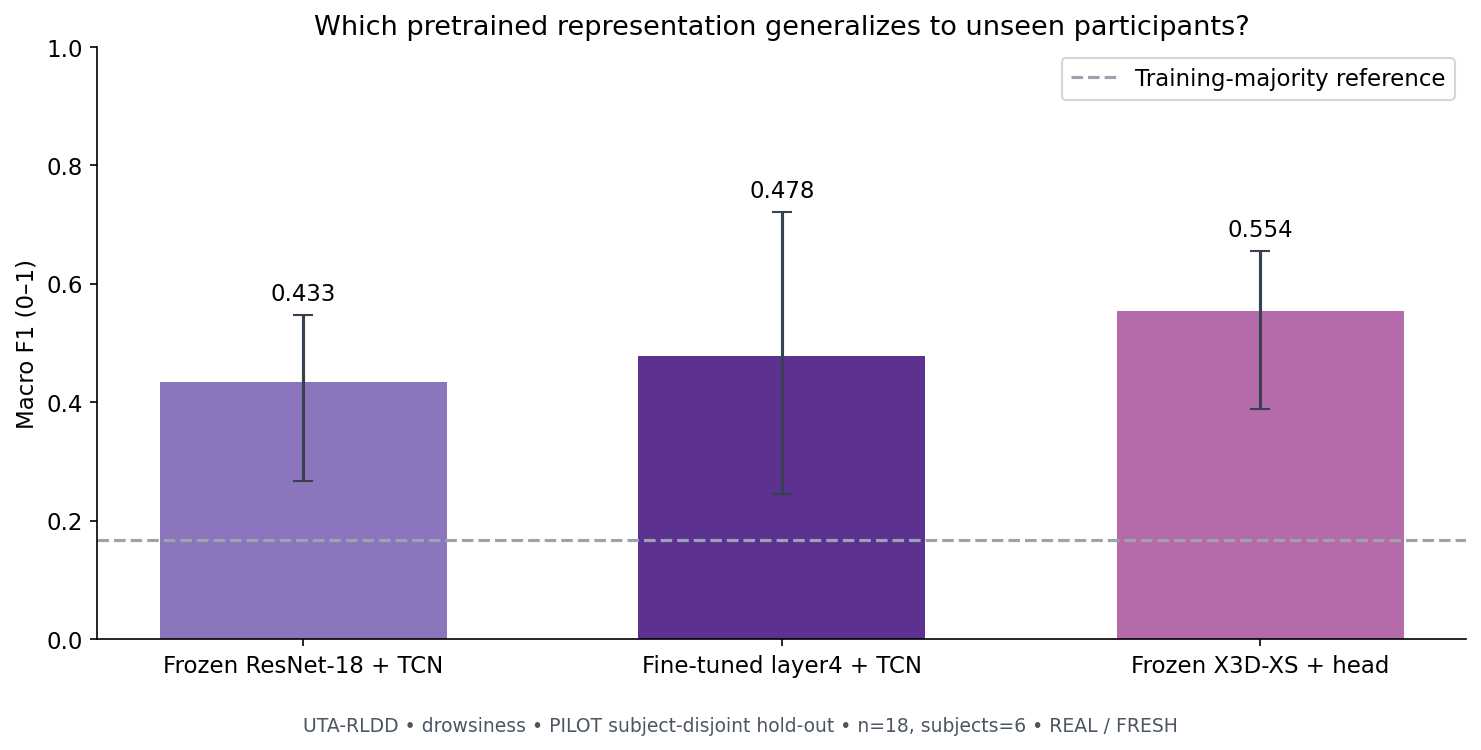

In [7]:
uta_show_figure("model_comparison.png")

**Yang terlihat:** Macro F1 held-out dihitung pada cohort test yang sama. Error bars merangkum bootstrap peserta: semua rekaman seorang peserta diambil bersama.

**Artinya:** perbedaan skor dapat dibandingkan secara paired. Majority reference menjadi pemeriksaan kewajaran sebelum menilai manfaat model kompleks.

**Perlu diingat:** interval ini bersifat deskriptif dari prediksi held-out, bukan ketidakpastian seluruh proses retraining. Lima model fold memiliki training sets yang saling bertumpang tindih; seed sensitivity dan external validation belum diuji dalam benchmark terbatas ini.


**Hasil aktual pilot:** Macro F1 frozen ResNet 0.4333, fine-tuned ResNet 0.4777, X3D-XS 0.5536. Selisih X3D versus frozen memiliki interval bootstrap peserta yang masih melintasi nol; ranking satu split belum membuktikan keunggulan yang konsisten.

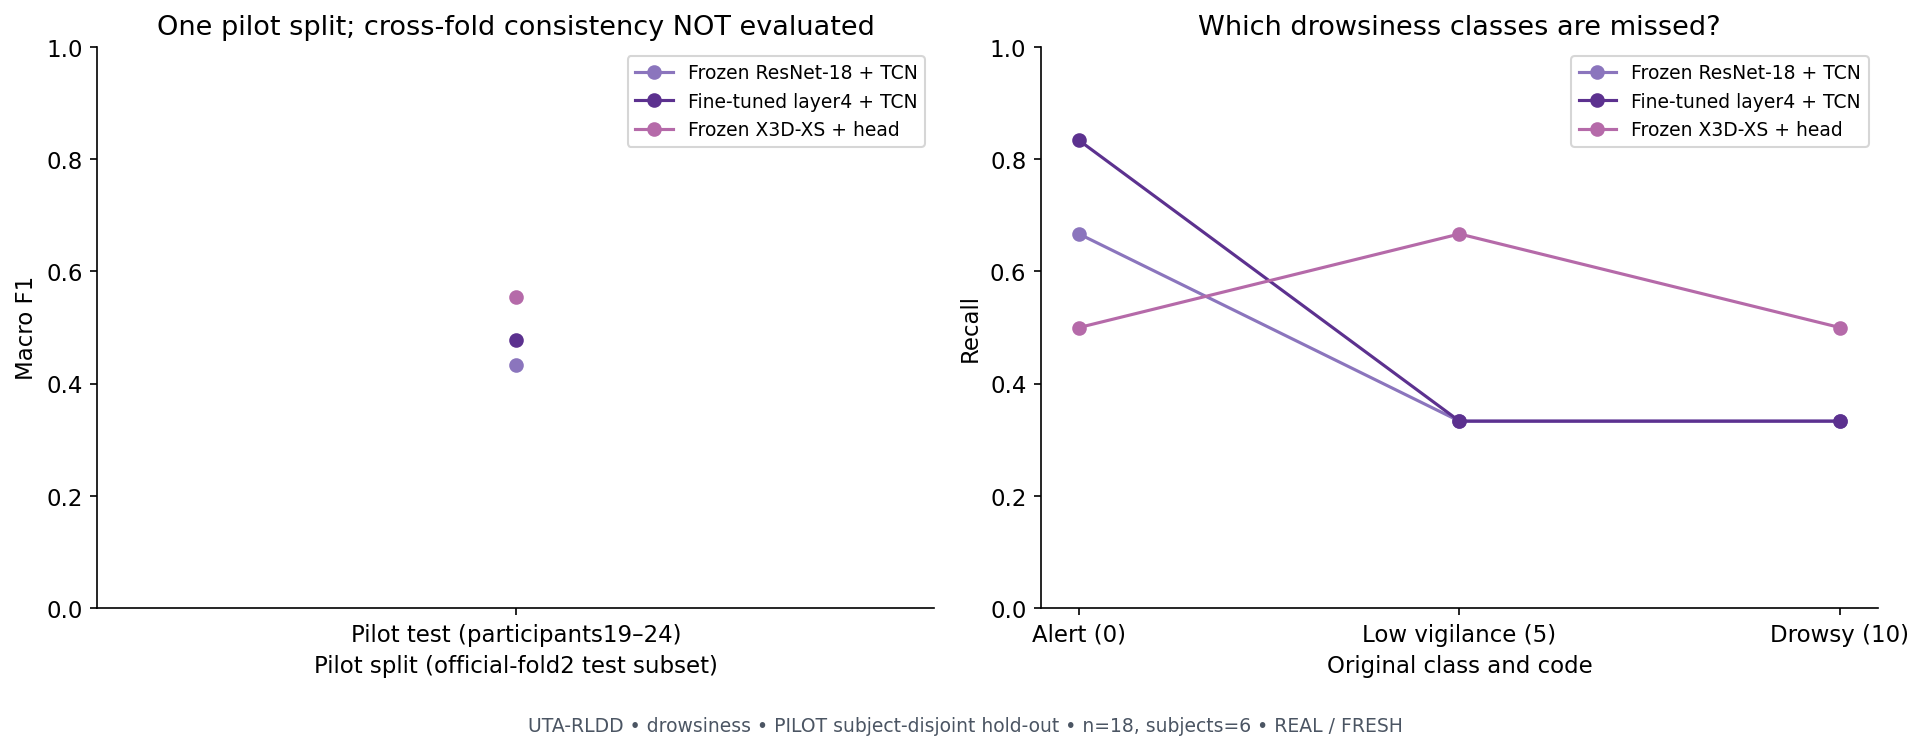

In [8]:
uta_show_figure("fold_and_class_performance.png")

**Yang terlihat:** panel kiri hanya menampilkan satu pilot split sehingga tidak mengukur konsistensi antarfold; panel kanan menunjukkan recall setiap kelas asli.

**Artinya:** model dengan skor gabungan tertinggi belum tentu unggul pada setiap kelompok peserta atau pada kelas Low Vigilance yang lebih ambigu. Konsistensi ini lebih berguna daripada memilih satu fold terbaik.

**Perlu diingat:** protokol full merencanakan 12 peserta test per fold, sedangkan pilot ini hanya memiliki 6 peserta test. Perbedaan wajah, lingkungan, dan label self-report dapat memengaruhi ranking tanpa membuktikan mekanisme fisiologis tertentu.


**Hasil aktual pilot:** recall Low Vigilance X3D adalah 4/6, sedangkan kedua ResNet 2/6. Fine-tuned ResNet mengenali Alert 5/6, tetapi Drowsy hanya 2/6. Jadi model terbaik pada skor agregat belum tentu terbaik di setiap kelas.

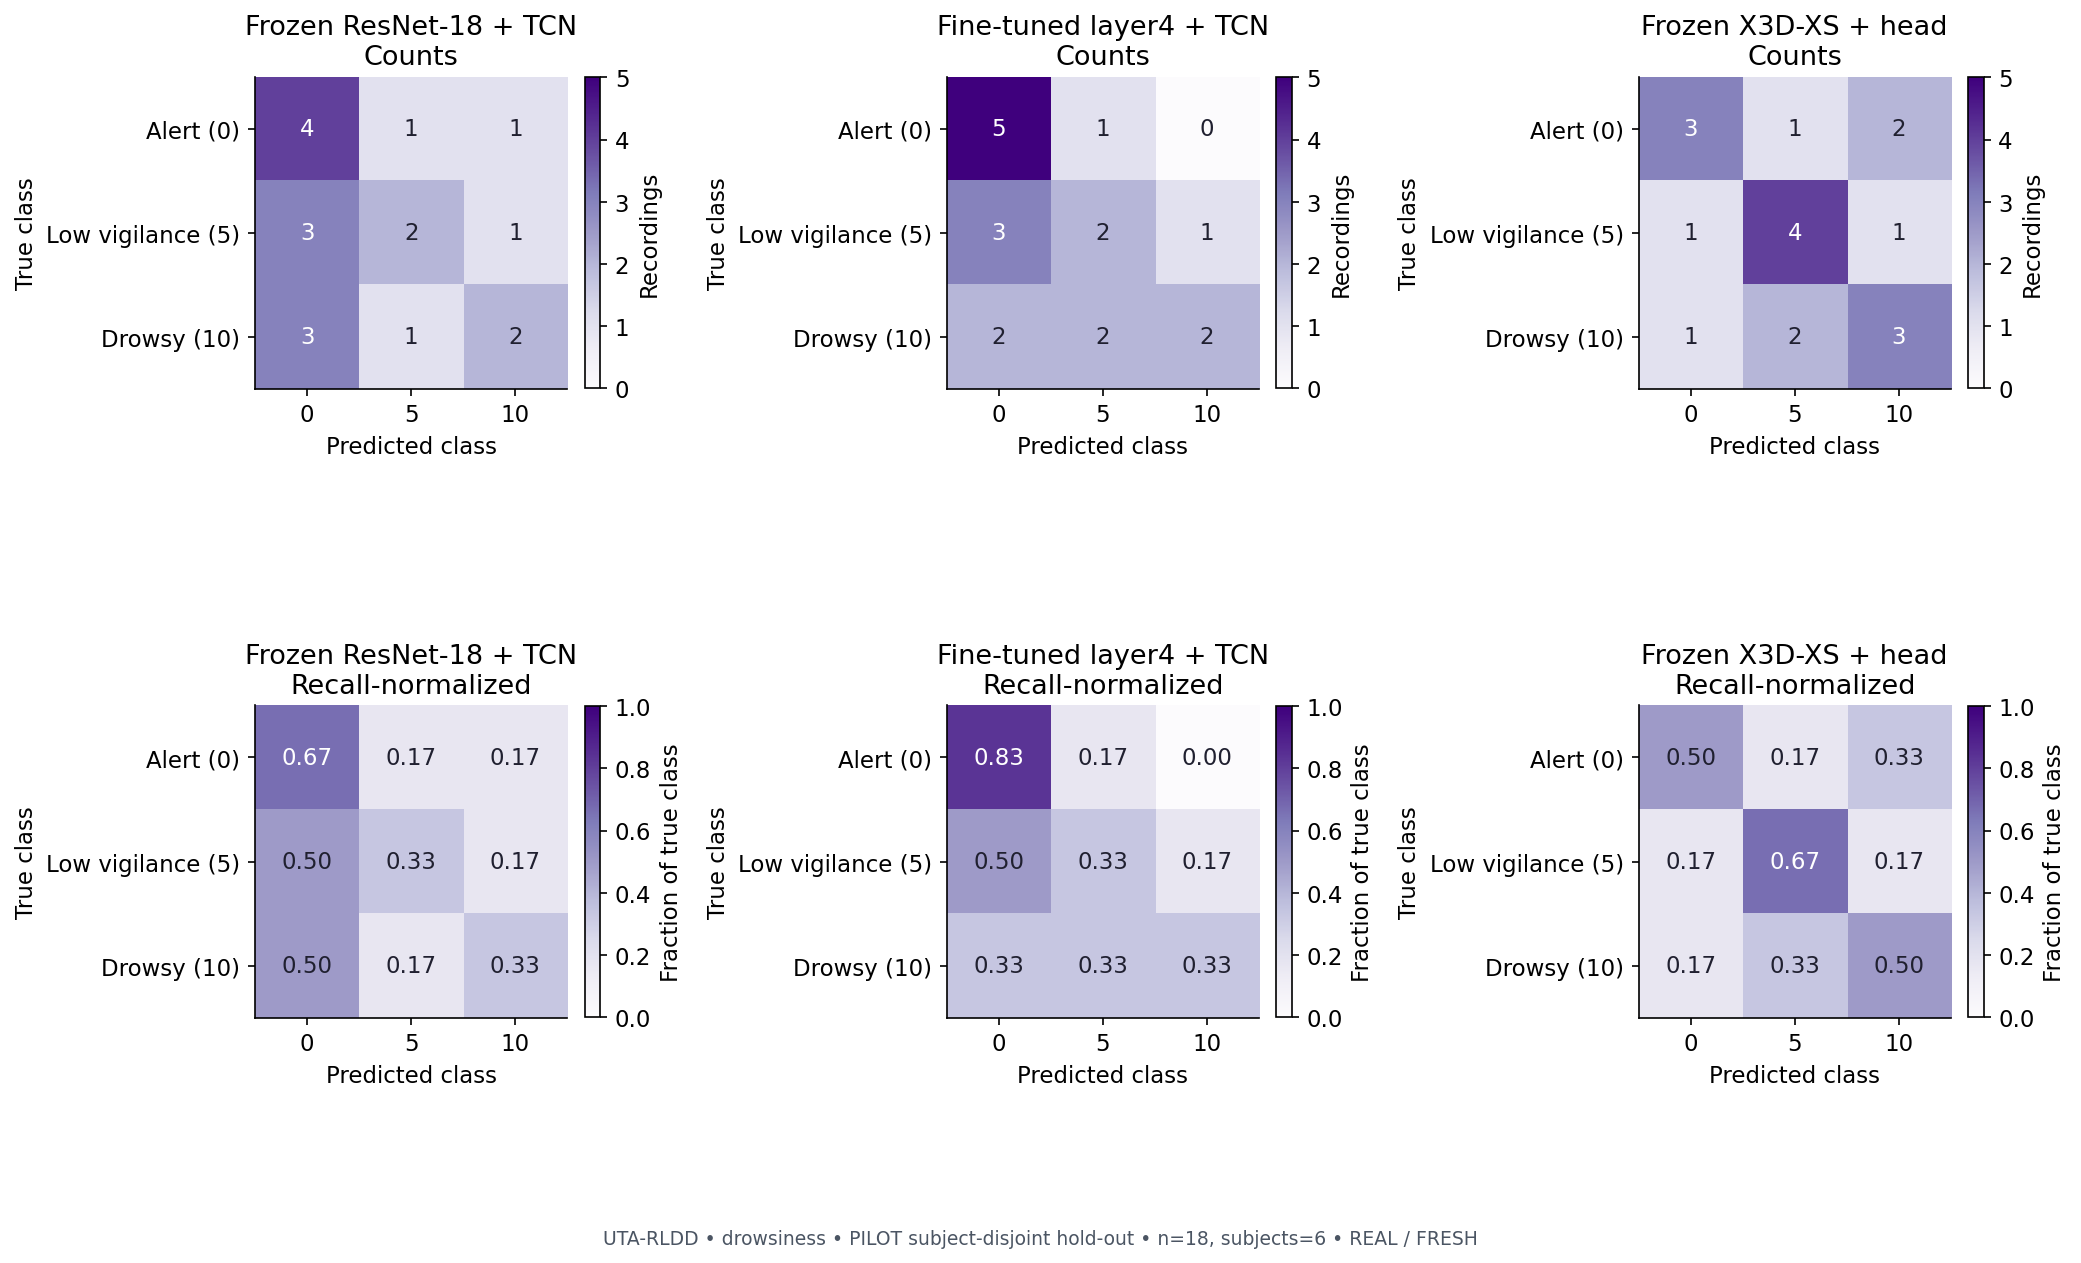

In [9]:
uta_show_figure("confusion_matrices.png")

**Yang terlihat:** baris pertama menghitung jumlah kesalahan; baris kedua menormalkan tiap kelas ground truth sehingga diagonalnya merupakan recall.

**Artinya:** kita dapat melihat apakah model membingungkan Low Vigilance dengan Alert atau Drowsy, dan apakah skor agregat menutupi recall kelas yang rendah.

**Perlu diingat:** label dominan video mengandung ketidakpastian waktu dan self-report. Confusion matrix mengevaluasi kesesuaian dengan label tersebut, bukan diagnosis kantuk setiap frame.


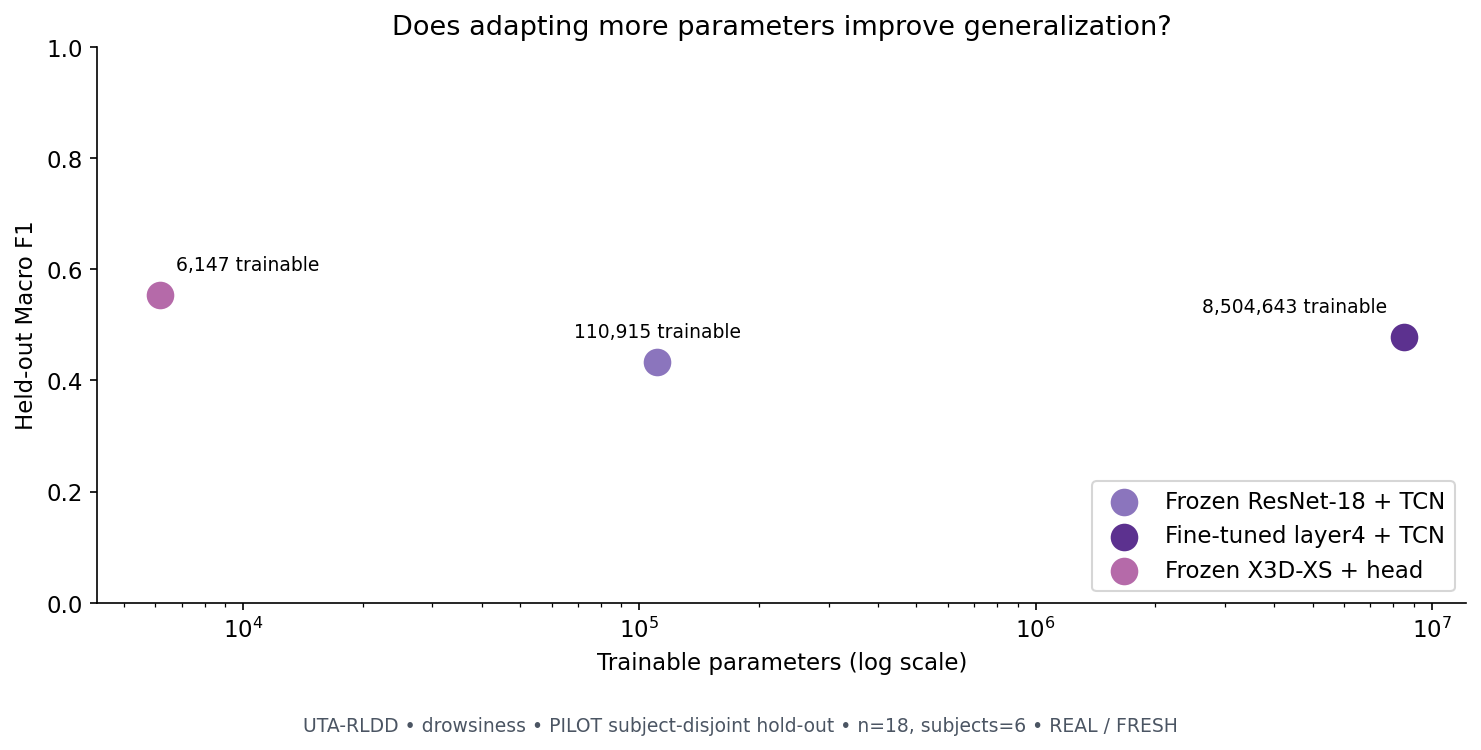

In [10]:
uta_show_figure("complexity_vs_performance.png")

**Yang terlihat:** sumbu horizontal logaritmik membandingkan jumlah parameter trainable dengan Macro F1 held-out. Total parameter dan biaya nyata tersedia pada tabel sebelumnya.

**Artinya:** adaptasi jutaan parameter perlu dibenarkan oleh validasi, bukan hanya kapasitas model. Frozen feature caching mengurangi komputasi training berulang untuk A/C.

**Perlu diingat:** jumlah parameter trainable tidak langsung setara dengan latency. Encoder frozen tetap memerlukan biaya ekstraksi fitur dan domain pretraining berbeda antara ResNet dan X3D.


## 9. Error analysis per rekaman dan peserta

Contoh pertama selalu ID terkecil pada test split pilot; contoh tambahan adalah ID kesalahan terkecil di seluruh held-out jika ada. Aturan ini deterministik dan tidak memilih hanya keberhasilan terbaik. Probabilitas softmax bukan jaminan bahwa keyakinan model sudah terkalibrasi.


In [11]:
uta_examples = []
for row in uta_report["examples"]:
    for model_probabilities in row["probabilities"]:
        model = model_probabilities["model"]
        uta_examples.append({"recording": row["recording_group_id"], "subject": row["subject_id"],
            "test_fold": row["fold"], "ground_truth": row["truth"], "model": model,
            "prediction": row[model], "correct": row[model] == row["truth"],
            **{key: value for key, value in model_probabilities.items() if key.startswith("probability_")}})
display(pd.DataFrame(uta_examples).round(4))
display(pd.DataFrame(uta_report["metrics"]["paired_differences_vs_frozen"]).T)


,recording,subject,test_fold,ground_truth,model,prediction,correct,probability_0,probability_5,probability_10
0,uta_19_0,19,2,0,frozen_resnet18,0,True,0.3724,0.3045,0.3230
1,uta_19_0,19,2,0,finetuned_resnet18,0,True,0.4150,0.3925,0.1925
2,uta_19_0,19,2,0,x3d_xs,10,False,0.2845,0.1976,0.5179


,lower,upper,draws,unit,scope
finetuned_resnet18,-0.146861,0.254762,1000,"participant, recordings retained together",descriptive held-out subject bootstrap; not in...
x3d_xs,-0.007937,0.294548,1000,"participant, recordings retained together",descriptive held-out subject bootstrap; not in...


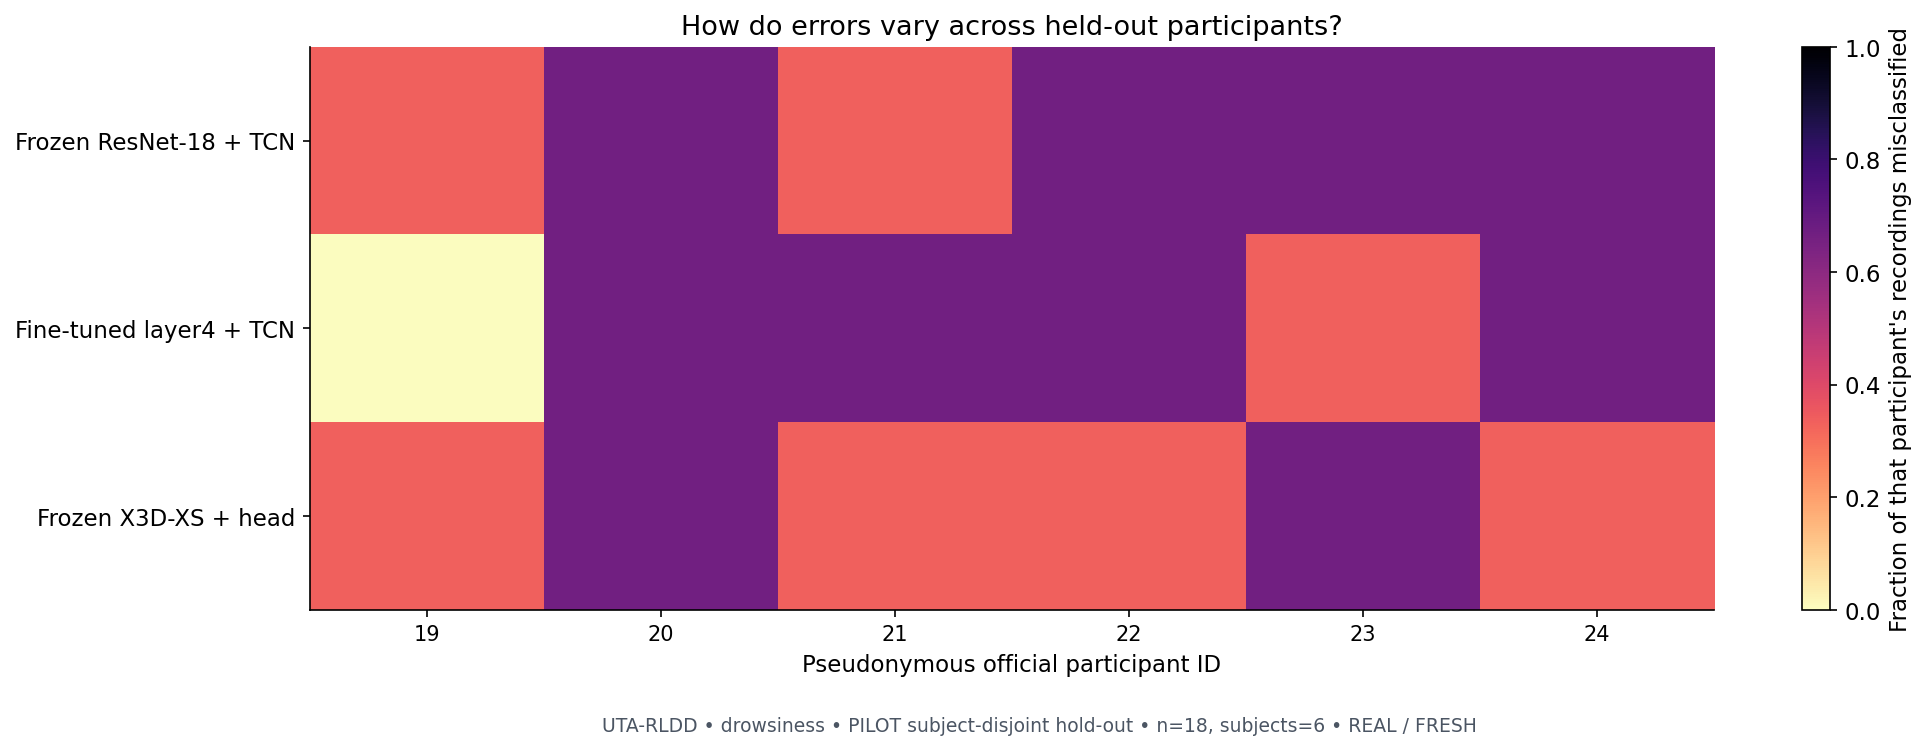

In [12]:
uta_show_figure("participant_errors.png")

**Yang terlihat:** setiap kolom menunjukkan proporsi rekaman salah dari satu peserta. Tabel contoh memperlihatkan ground truth, prediksi, dan probabilitas seluruh model pada rekaman yang sama.

**Artinya:** kesalahan yang terkonsentrasi pada peserta tertentu perlu dipahami sebagai masalah generalisasi; beberapa klip orang yang sama bukan bukti independen tambahan.

**Perlu diingat:** tanpa anotasi fisiologis dan eksperimen terkontrol tambahan, kita tidak bisa mengatribusikan kesalahan kepada blink, identitas, pencahayaan, atau kualitas label secara pasti.


**Hasil aktual pilot:** pada peserta20 ketiga model masing-masing salah pada dua dari tiga rekaman. Ini memperlihatkan variasi antarorang, tetapi tidak menjelaskan apakah penyebabnya ciri wajah, kondisi pengambilan data, atau ketidakpastian label.

## 10. Apa yang dapat disimpulkan untuk riset ATC?

Kita pisahkan **pipeline berhasil dijalankan** dari **metode lebih unggul secara konsisten**. Yang pertama memerlukan bukti pretrained loading, training, checkpoint replay, dan prediksi held-out lengkap. Yang kedua memerlukan perbandingan paired, pola antarfold, dan ketidakpastian peserta.

Benchmark ini mengevaluasi **drowsiness self-report UTA-RLDD pada peserta baru**. Tidak ada klaim akurasi occupational fatigue operator ATC, tidak ada penyamaan kode 0/5/10 dengan KSS, dan tidak ada perubahan kesimpulan DROZY sebelumnya.

Keterbatasan utama: release nominal 60 peserta, tetapi pilot hanya memakai 24 peserta dan 6 peserta test, video-level weak supervision, sampel temporal sangat jarang, satu seed yang ditetapkan sebelumnya, kemungkinan confounding perangkat/lingkungan, dan tidak adanya external ATC validation. Tindak lanjut yang paling bernilai adalah replikasi seed terbatas dan dataset eksternal berlabel tervalidasi; tuning berdasarkan skor outer-test saat ini harus dihindari.


In [13]:
uta_scores = pd.DataFrame(uta_report["model_comparison"]).set_index("model")
uta_folds = pd.DataFrame(uta_report["per_fold"]).pivot(index="fold", columns="model", values="macro_f1")
uta_leader = uta_scores.macro_f1.idxmax()
print("CACHED / REAL — model dengan held-out Macro F1 tertinggi:", uta_leader)
for model in ["finetuned_resnet18", "x3d_xs"]:
    difference = uta_folds[model] - uta_folds["frozen_resnet18"]
    print(model, "unggul atas frozen pada", int((difference > 0).sum()), "dari", len(difference), "fold;",
          "selisih held-out Macro F1 =", round(float(uta_scores.loc[model, "macro_f1"] - uta_scores.loc["frozen_resnet18", "macro_f1"]), 4))
print("Temuan ini adalah benchmark drowsiness; peningkatan konsisten tidak diasumsikan.")

print("PILOT: konsistensi lima fold belum dievaluasi; full benchmark NOT RUN — DATA UNAVAILABLE.")


CACHED / REAL — model dengan held-out Macro F1 tertinggi: x3d_xs
finetuned_resnet18 unggul atas frozen pada 1 dari 1 fold; selisih held-out Macro F1 = 0.0444
x3d_xs unggul atas frozen pada 1 dari 1 fold; selisih held-out Macro F1 = 0.1203
Temuan ini adalah benchmark drowsiness; peningkatan konsisten tidak diasumsikan.
PILOT: konsistensi lima fold belum dievaluasi; full benchmark NOT RUN — DATA UNAVAILABLE.
